# OGM Conjecture 4

Let $f$ be convex and $L$-smooth, with $L>0$, $R\ge0$, and integer $N\ge1$.
Assume $\nabla f(x_\star)=0$ and $\|x_0-x_\star\|\le R$.
Initialize $x_0=y_0=z_0$, $\theta_0=1$. For $0\le k\le N-2$ use
$$\theta_{k+1}=(1+\sqrt{1+4\theta_k^2})/2,$$
$$y_{k+1}=x_k-\nabla f(x_k)/L,\quad
z_{k+1}=z_k-2\theta_k\nabla f(x_k)/L,\quad
x_{k+1}=(1-1/\theta_{k+1})y_{k+1}+z_{k+1}/\theta_{k+1}.$$
The final step forms $y_N=x_{N-1}-\nabla f(x_{N-1})/L$ and
$z_N=z_{N-1}-2\theta_{N-1}\nabla f(x_{N-1})/L$; the reported point is $y_N$.
The bound is
$$f(y_N)-f(x_\star)\le\frac{LR^2}{2(2\theta_{N-1}^2+1)}.$$

The preserved discovery implementation also forms a terminal $x_N$ using
$\theta_N=(1+\sqrt{1+8\theta_{N-1}^2})/2$. This extension changes neither
$y_N$ nor $z_N$. Code Cell 42 proves the auxiliary-coordinate identity for
an arbitrary nonzero next parameter, so it also covers that unused extension.

## Proof Statement

### Theorem and coefficient definitions

The preceding OGM iteration satisfies the bound for every $N\ge1$. Set
$f_\star=f(x_\star)$ and $\tau_N=1/[2(2\theta_{N-1}^2+1)]$. As in Theorem F.7,
$$a_0=0,\quad a_{N+1}=1,\quad
a_k=\frac{\theta_{k-1}^2(2\theta_{N-1}^2-\theta_{k-1}^2)}
{\theta_{N-1}^2(2\theta_{N-1}^2-\theta_{k-1}^2+1)}\quad(1\le k\le N),
\qquad b_k=a_k-a_{k-1}\quad(1\le k\le N+1).$$
For $0\le k<N$, define
$$\boldsymbol w_k=\begin{bmatrix}z_{k+1}-x_\star\\y_{k+1}-x_\star\end{bmatrix},\qquad
\mathbf Q_k=\frac1{4\theta_{N-1}^2(2\theta_{N-1}^2+1-\theta_k^2)^3}
\begin{pmatrix}
(2\theta_{N-1}^2-\theta_k^2)(2\theta_{N-1}^2+1-\theta_k^2)^2&
-\theta_k^2(2\theta_{N-1}^2+1-\theta_k^2)\\
-\theta_k^2(2\theta_{N-1}^2+1-\theta_k^2)&
\theta_k^2(6\theta_{N-1}^2-4\theta_k^2+3)
\end{pmatrix}.$$
For $1\le k<N$, define
$$P_k=(8\theta_k-6)(\theta_{N-1}^2-\theta_k^2)
+4(\theta_k-1)^3+10(\theta_k-1)^2+12(\theta_k-1)+3,$$
$$\alpha_k=\frac{\theta_k^2P_k}{4\theta_{N-1}^2(2\theta_{N-1}^2+1-\theta_k^2)^3},\quad
\beta_k=\frac{3\theta_k(\theta_k-1)}
{4\theta_{N-1}^2(2\theta_{N-1}^2+1-\theta_{k-1}^2)P_k},\quad
\rho_k=\frac{2\theta_{N-1}^2+1-2\theta_{k-1}^2}
{2\theta_{N-1}^2+1-\theta_{k-1}^2},$$
$$M_k=\begin{pmatrix}1&0\\1/\theta_k&(\theta_k-1)/\theta_k\end{pmatrix},\quad
\boldsymbol c_k=\begin{bmatrix}2\theta_k\\1\end{bmatrix},\quad
\boldsymbol d_k=\frac{a_{k+1}}2
\begin{bmatrix}1/\theta_k\\(\theta_k-1)/\theta_k\end{bmatrix}
-\frac{a_k}2\begin{bmatrix}0\\1\end{bmatrix}.$$
The square directions and sum are
$$s_k=\frac{\nabla f(x_k)}L+
\frac{(-\boldsymbol d_k+M_k^\top\mathbf Q_k\boldsymbol c_k)^\top\boldsymbol w_{k-1}}{\alpha_k},
\qquad t_k=z_k-x_\star-\rho_k(y_k-x_\star),$$
$$S_k=L\alpha_k\|s_k\|^2+L\beta_k\|t_k\|^2.$$
Lemma F.8 supplies the positive coefficient and denominator domains. The
analytic potential below uses the auxiliary state $z_N-x_\star$ at $k=N-1$.
The saved numerical reverse-LDL partial sums are a separate discovery certificate.


### Proof outline and proof-to-cell index

**Code Cell n** counts code cells only, starting at 1 and excluding Markdown.
Jupyter `In[n]` agrees after a fresh kernel executes every code cell once in order.
The exact proof uses Code Cells 40 and 42–47; Code Cell 49 exports the checked
handoff. The complete run also verifies the archived numerical certificates.

| Proof obligation | Checking code cells |
|---|---|
| Auxiliary-state equivalence and interior matrix factorization | 42 |
| Coefficient signs and denominator domains | 42 and the sign argument below |
| Complete interior decrement | 44 |
| Initial decrement and direct $N=1$ case | 45 |
| Terminal position factorization | 42 |
| Terminal decrement, radius normalization, and direct $N=1$ case | 46 |
| Supplementary global interpolation identity | 47 |

Let $\mathcal I_f(x,y)=f(y)-f(x)+\langle\nabla f(y),x-y\rangle
+\|\nabla f(x)-\nabla f(y)\|^2/(2L)\le0$. Theorem F.7 defines
$$\begin{aligned}
V_{-1}&=0,\\
V_k&=a_{k+1}\bigl(f(x_k)-f_\star\bigr)
-\tau_NL\|x_0-x_\star\|^2
-\frac{a_{k+1}}{2L}\|\nabla f(x_k)\|^2
+L\boldsymbol w_k^\top\mathbf Q_k\boldsymbol w_k,&&0\le k<N,\\
V_N&=f(y_N)-f_\star-\tau_NL\|x_0-x_\star\|^2.
\end{aligned}$$
The quadratic form uses inner products of the state components. The boundary
squares are
$$S_0=\frac{L}{32\theta_{N-1}^8(2\theta_{N-1}^2+1)}
\left\|x_0-x_\star-\frac{2\theta_{N-1}^2+1}{L}\nabla f(x_0)\right\|^2,$$
$$S_N=\frac1{2L}\left\|\nabla f(y_N)-\frac{L}{\theta_{N-1}^2+1}
(y_N-x_\star)\right\|^2
+\frac{L}{4(\theta_{N-1}^2+1)}\left\|z_N-x_\star-
\frac{y_N-x_\star}{\theta_{N-1}^2+1}\right\|^2.$$
The exact decrements are
$$\begin{aligned}
V_0-V_{-1}&=a_1\mathcal I_f(x_\star,x_0)-S_0,\\
V_k-V_{k-1}&=b_{k+1}\mathcal I_f(x_\star,x_k)
+a_k\mathcal I_f(x_{k-1},x_k)-S_k,&&1\le k<N,\\
V_N-V_{N-1}&=b_{N+1}\mathcal I_f(x_\star,y_N)
+a_N\mathcal I_f(x_{N-1},y_N)-S_N.
\end{aligned}$$
Positive interpolation and square weights imply $V_N\le\cdots\le V_{-1}=0$.
The endpoint identity
$$f(y_N)-f_\star-\tau_NLR^2
=V_N+\tau_NL(\|x_0-x_\star\|^2-R^2)\le0$$
gives the rate. For $N=1$, the initial and terminal decrements apply directly.


In [1]:
from pathlib import Path
from typing import Any
import hashlib
import json
import sys
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

cwd = Path.cwd().resolve()
ROOT = next(
    candidate
    for candidate in (cwd, *cwd.parents)
    if (candidate / "pepflow" / "pep.py").is_file()
)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
EXAMPLE = ROOT / "examples_peppy" / "ogm_conjecture4"
STATE_STEM = "ogm_conjecture_4"
sys.dont_write_bytecode = True

# Resolve the local repository before importing its package.
import pepflow as pf  # noqa: E402

## Function and parameters

The parameter $R$ denotes the radius; the PEP uses $R^2$.

In [2]:
L = pf.Parameter("L")
R = pf.Parameter("R")
f = pf.SmoothConvexFunction(is_basis=True, tags=["f"], L=L)

## Algorithm and PEP setup

The context builder below explicitly implements the supplied recursion. Smooth-convex
interpolation is enforced at the stationary point, each queried $x_k$, and $y_N$.
Numerical theta coefficients use 50 decimal digits before SDP conversion to double
precision; `exact=True` retains the nested radicals for later symbolic work.

In [3]:
def theta_sequence(N, *, exact=False):
    """Return theta_0,...,theta_N; numerical coefficients use 50 digits.

    exact=True preserves nested radicals for later symbolic investigations.
    The SDP solver ultimately uses double precision in either case.
    """
    if isinstance(N, bool) or int(N) != N or N < 1:
        raise ValueError("N must be a positive integer")
    N = int(N)
    theta = [sp.Integer(1)]
    for k in range(N):
        factor = 8 if k == N - 1 else 4
        next_theta = (1 + sp.sqrt(1 + factor * theta[-1] ** 2)) / 2
        theta.append(next_theta if exact else next_theta.evalf(50))
    return theta


def conjectured_rate(N, L_value=1, R_value=1):
    theta = theta_sequence(N)
    return (
        sp.sympify(L_value)
        * sp.sympify(R_value) ** 2
        / (2 * (2 * theta[N - 1] ** 2 + 1))
    )


def make_ctx_ogm_conjecture4_test_20260916_2am(ctx_name, N, **kwargs):
    """Encode all supplied updates, including the terminal x_N update."""
    theta = theta_sequence(N, exact=kwargs.get("exact", False))
    N = int(N)
    ctx = pf.PEPContext(ctx_name).set_as_current()
    # Last tag remains x_0 so oracle names consistently use x_k.
    x = pf.Vector(is_basis=True, tags=["y_0", "x_0"])
    y = z = x
    f.set_stationary_point("x_star")
    for k in range(N):
        gradient = f.grad(x)
        y_next = x - gradient / L
        y_next.add_tag(f"y_{k + 1}")
        z_next = z - (2 * theta[k] / L) * gradient
        # The last x_N is retained for the archived setup; y_N is reported.
        x_next = (1 - 1 / theta[k + 1]) * y_next + z_next / theta[k + 1]
        x_next.add_tag(f"x_{k + 1}")
        x, y, z = x_next, y_next, z_next  # noqa: F841 - retain the algorithm iterate update
    return ctx


def get_pep_setup(N, params):
    """Standard pepflow.pep_runner interface; parameters resolve at solve time."""
    if "L" in params and float(params["L"]) <= 0:
        raise ValueError("L must be positive")
    if "R" in params and float(params["R"]) < 0:
        raise ValueError("R must be nonnegative")
    ctx = make_ctx_ogm_conjecture4_test_20260916_2am(f"ctx_{N}", N)
    pb = pf.PEPBuilder(ctx)
    pb.add_initial_constraint(
        ((ctx["x_0"] - ctx["x_star"]) ** 2).le(R**2, name="initial_condition")
    )
    pb.set_performance_metric(f(ctx[f"y_{N}"]) - f(ctx["x_star"]))
    return ctx, pb, f

In [4]:
ctx, pb, objective_function = get_pep_setup(4, {"L": 1, "R": 1})
assert ctx["y_0"] is ctx["x_0"]
assert len(ctx.func_to_triplets[objective_function]) == 6  # star, x_0..x_3, y_4
print("Initial condition:", pb.init_conditions[0])
print("Performance metric:", pb.performance_metric)
print(
    "Registered oracle points:",
    [str(t.point) for t in ctx.func_to_triplets[objective_function]],
)
print("N=1 theta sequence:", theta_sequence(1, exact=True))

Initial condition: ScalarConstraint(lhs=|x_0-x_star|^2, rhs=R**2, cmp=<Comparator.LE: 'LE'>, name='initial_condition', associated_dual_var_constraints=[])
Performance metric: f(y_4)-f(x_star)
Registered oracle points: ['x_star', 'x_0', 'x_1', 'x_2', 'x_3', 'y_4']
N=1 theta sequence: [1, 2]


## Numerical evidence

The saved sweep uses $L=R=1$ and $N=1,\ldots,7$. It was obtained with
`pepflow.pep_runner.run`, full smooth-convex interpolation, and CLARABEL with
absolute/relative gap and feasibility tolerances $10^{-8}$. The comparison
tolerance is $10^{-5}$ relative. These finite numerical checks are not an exact
certificate or an all-$N$ proof. The cells below reuse this run's sweep, avoiding
another unchanged SDP sweep during notebook execution.

 N       PEP value       conjecture       relative error   status
 1  0.166666663354  0.166666666667  -1.988e-08  optimal
 2  0.080178726701  0.080178728295  -1.988e-08  optimal
 3  0.047067142950  0.047067142129  +1.744e-08  optimal
 4  0.031012165811  0.031012166093  -9.084e-09  optimal
 5  0.022014343821  0.022014344016  -8.858e-09  optimal
 6  0.016459460169  0.016459460177  -4.629e-10  optimal
 7  0.012785164917  0.012785165307  -3.054e-08  optimal
Maximum absolute relative error: 3.053517749762591e-08
Maximum solver constraint violation: 2.5059615076461155e-09
Nonunit scaling check: {'N': 2, 'L': 2, 'R': 3, 'opt_value': 1.4432171059343684, 'relative_error': -2.344751504068654e-09}
1 / PEP: [ 6.       12.472136 21.246244 32.24541  45.424929 60.755334 78.215651]
Successive differences: [ 6.472136  8.774108 10.999166 13.179519 15.330405 17.460317]


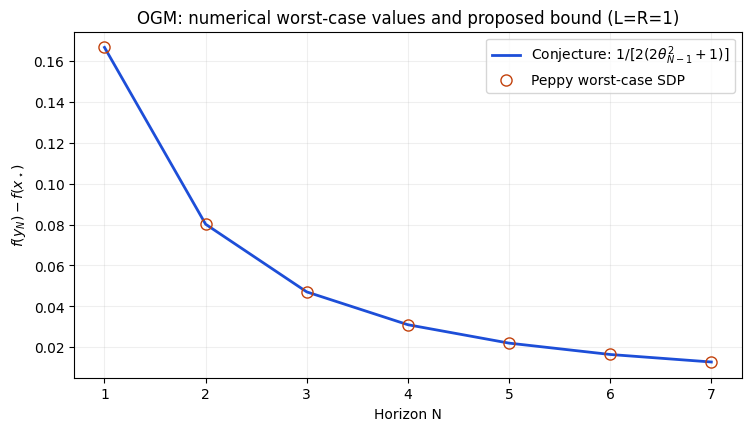

In [5]:
state = json.loads((EXAMPLE / "state" / "ogm_conjecture_4_b1.json").read_text())
setup_path = EXAMPLE / "ogm_conjecture4_setup.py"
rows = state["sweep_results"]
Ns = np.array([r["N"] for r in rows])
values = np.array([r["opt_value"] for r in rows])
bounds = np.array([float(conjectured_rate(int(n))) for n in Ns])
errors = values / bounds - 1
assert all(r["solver_status"] == "optimal" for r in rows)
assert np.all(np.abs(errors) < state["match_relative_tolerance"])
print(" N       PEP value       conjecture       relative error   status")
for row, bound, error in zip(rows, bounds, errors):
    print(
        f"{row['N']:2d}  {row['opt_value']:.12f}  {bound:.12f}  {error:+.3e}  {row['solver_status']}"
    )
print("Maximum absolute relative error:", float(np.max(np.abs(errors))))
print(
    "Maximum solver constraint violation:",
    max(r["max_constraint_violation"] for r in rows),
)
scaled = state["scaling_check"]
assert abs(scaled["relative_error"]) < state["match_relative_tolerance"]
print("Nonunit scaling check:", scaled)
print("1 / PEP:", np.round(1 / values, 6))
print("Successive differences:", np.round(np.diff(1 / values), 6))

fig, ax = plt.subplots(figsize=(7.4, 4.2), constrained_layout=True)
ax.plot(
    Ns,
    bounds,
    "-",
    color="#1d4ed8",
    linewidth=2,
    label=r"Conjecture: $1/[2(2\theta_{N-1}^2+1)]$",
)
ax.plot(
    Ns,
    values,
    "o",
    markerfacecolor="none",
    markeredgecolor="#c2410c",
    markersize=8,
    label="Peppy worst-case SDP",
)
ax.set(
    xlabel="Horizon N",
    ylabel=r"$f(y_N)-f(x_\star)$",
    xticks=Ns,
    title="OGM: numerical worst-case values and proposed bound (L=R=1)",
)
ax.grid(alpha=0.2)
ax.legend()
fig.savefig(EXAMPLE / "supplementary" / "block1_rate_comparison.png", dpi=170)
plt.show()

The sweep numerically matches
$LR^2/[2(2\theta_{N-1}^2+1)]$ at all seven tested horizons. The increasing inverse
values are consistent with an $O(N^{-2})$ rate. The nonunit check verifies the
implemented $LR^2$ scaling numerically. Solver output does not by itself prove
the conjecture for every horizon.

## Dense and sparse full-PEP certificates — Block 2

**Archived discovery sample:** these cells read and write `supplementary/b3_prior_N4/`. The selected handoff is updated to $N=8$ in Block 3 below.

At $N=4$ and $L=R=1$, a fresh dense solve and a fresh sparse solve use full
smooth-convex interpolation and CLARABEL (gap and feasibility tolerances $10^{-8}$).
Every dual multiplier and the Gram slack $S$ in the selected certificate come from
one solve. The saved provenance records its solve ID and source hashes.

The dense solution has five interpolation multipliers below $10^{-6}$.
Removing those preserves the bound. A subsequent structured relaxation keeps only

$$ (x_\star,x_i)\ (0\leq i<4),\quad (x_\star,y_4),\quad
(x_i,x_{i+1})\ (0\leq i<3),\quad (x_3,y_4). $$

This retains nine of the thirty interpolation inequalities. The pair $(u,v)$
denotes the convention used by Peppy:

$$R_{u,v}=f(v)-f(u)+\langle\nabla f(v),u-v\rangle
+\frac{1}{2L}\|\nabla f(u)-\nabla f(v)\|^2\leq0.$$

Notebook execution rebuilds and verifies the saved coherent certificate
from the dense and sparse captures without another SDP solve. The following cells expose
the constraint inventory, decomposition, and full coefficient checks.

In [6]:
import json
import numpy as np

state_dir = EXAMPLE / "supplementary" / "b3_prior_N4"
dense_summary = json.loads((state_dir / f"{STATE_STEM}_dense.json").read_text())
sparse_summary = json.loads(
    (EXAMPLE / "supplementary" / "b2_selected_capture.json").read_text()
)
print("N:", sparse_summary["N_verify"], "parameters:", sparse_summary["params_json"])
for label, record in [("dense", dense_summary), ("selected sparse", sparse_summary)]:
    provenance = record["certificate_provenance"]
    active = [
        (name, value)
        for name, value in record["named_dual_values"].items()
        if record["constraint_metadata"][name]["origin"] == "interpolation"
        and value is not None
        and abs(value) >= 1e-6
    ]
    print(
        label,
        "value:",
        record["opt_value"],
        "status:",
        provenance["solver_status"],
        "solver:",
        provenance["solver"]["effective_name"],
        "multipliers >=1e-6:",
        len(active),
    )
    print("  S eigenvalues:", np.linalg.eigvalsh(record["S_matrix"]))
    if label == "selected sparse":
        for name, value in active:
            print(" ", name, f"{value:.12f}")
print("Sparsity trials:", sparse_summary["sparsity_search"])
print(
    "Dense/sparse objective difference:",
    abs(dense_summary["opt_value"] - sparse_summary["opt_value"]),
)
print("Gram basis:", sparse_summary["basis_vectors"])

N: 4 parameters: {"L": 1, "R": 1}
dense value: 0.031012165810851675 status: optimal solver: CLARABEL multipliers >=1e-6: 25
  S eigenvalues: [1.10802453e-09 1.27374763e-09 1.24452357e-04 1.83545593e-03
 1.32156883e-02 2.79271928e-01 1.75951630e+00]
selected sparse value: 0.03101216557574006 status: optimal solver: CLARABEL multipliers >=1e-6: 9
  S eigenvalues: [4.36536585e-09 5.45180731e-09 2.80523565e-04 2.57761878e-03
 1.35797901e-02 5.03760645e-01 1.94926267e+00]
  f:x_star,x_0 0.123506997891
  f:x_star,x_1 0.197098750883
  f:x_star,x_2 0.259487846481
  f:x_star,x_3 0.303136997231
  f:x_star,y_4 0.116769425147
  f:x_0,x_1 0.123506997891
  f:x_1,x_2 0.320605745069
  f:x_2,x_3 0.580093588253
  f:x_3,y_4 0.883230582522
Sparsity trials: {'threshold': 1e-06, 'threshold_dropped_count': 5, 'attempts': [{'label': 'star_chain', 'kept': ['f:x_0,x_1', 'f:x_1,x_2', 'f:x_2,x_3', 'f:x_3,y_4', 'f:x_star,x_0', 'f:x_star,x_1', 'f:x_star,x_2', 'f:x_star,x_3', 'f:x_star,y_4'], 'dropped': 21, 'opt_val

### Rebuild the complete constraint inventory

Validate every saved multiplier, comparator, and coordinate label against this setup.

In [7]:
from pathlib import Path
import importlib.util

# Package-version discovery is not needed when replaying this certificate.
import json
import sys

if "EXAMPLE" not in globals():
    EXAMPLE = Path(__file__).resolve().parent.parent
ROOT = EXAMPLE.parent.parent
sys.path.insert(0, str(ROOT))

# Local imports follow repository-path setup; SymPy is bound in imports.
import numpy as np  # noqa: E402
import pepflow as pf  # noqa: E402
from pepflow.constraint import ScalarConstraint, PSDConstraint  # noqa: E402
from pepflow.operator import LinearOperatorTranspose  # noqa: E402
from pepflow.utils import Comparator  # noqa: E402
from pepflow.lyapunov_utils import ldl_decompose_with_reversed_basis  # noqa: E402

if "EXAMPLE" not in globals():
    EXAMPLE = Path(__file__).resolve().parent.parent
ROOT = EXAMPLE.parent.parent
HERE = EXAMPLE / "supplementary"
STATE = EXAMPLE / "supplementary" / "b3_prior_N4"
NAME = STATE_STEM
sys.dont_write_bytecode = True
b1 = json.loads((STATE / f"{NAME}_b1.json").read_text())
dense_data = json.loads((STATE / f"{NAME}_dense.json").read_text())
selected = json.loads((HERE / "b2_selected_capture.json").read_text())
N_int = int(selected["N_verify"])
params_sp = {k: sp.sympify(v) for k, v in json.loads(selected["params_json"]).items()}
setup_file = EXAMPLE / "ogm_conjecture4_setup.py"
assert selected["params_json"] == b1["params_json"]
assert N_int == b1["N_verify"]
assert selected["normalization"]["performance_metric"] == b1["performance_metric"]
assert selected["normalization"]["initial_condition"] == b1["initial_condition"]
assert Path(pf.__file__).resolve() == ROOT / "pepflow" / "__init__.py"
spec = importlib.util.spec_from_file_location("b2_verified_setup", setup_file)
assert spec is not None and spec.loader is not None, "Cannot load verified setup"
setup = importlib.util.module_from_spec(spec)
spec.loader.exec_module(setup)
ctx, pb, obj = setup.get_pep_setup(sp.S(N_int), params_sp)
pb.set_relaxed_constraints(selected["relaxed_constraints"])
# No new solve occurs: all multipliers and S belong to selected.solve_id.
ctx.set_as_current()
entries = [(c, "initial", None, None) for c in pb.init_conditions]
for owner in [*ctx.func_to_triplets, *ctx.oper_to_duplets]:
    if isinstance(owner, LinearOperatorTranspose):
        continue
    groups = ctx.get_constraint_data(owner)
    entries.extend(
        (c, "interpolation", str(owner), str(group))
        for group, constraints in groups.sc_dict.items()
        for c in constraints
    )
    entries.extend(
        (c, "interpolation", str(owner), str(group))
        for group, c in groups.psd_dict.items()
    )
assert len({c.name for c, *_ in entries}) == len(entries)
metadata = selected["constraint_metadata"]
named = selected["named_dual_values"]
assert set(metadata) == set(named) == {c.name for c, *_ in entries}
assert set(pb.relaxed_constraints).issubset(metadata)
for c, origin, owner, group in entries:
    scalar = isinstance(c, ScalarConstraint)
    assert scalar or isinstance(c, PSDConstraint)
    expected = dict(
        origin=origin,
        owner=owner,
        group=group,
        kind="scalar" if scalar else "psd",
        comparator=c.cmp.value,
        shape=[] if scalar else list(np.asarray(c.lhs - c.rhs).shape),
        relaxed=c.name in pb.relaxed_constraints,
    )
    assert metadata[c.name] == expected
    value = named[c.name]
    if expected["relaxed"]:
        assert value is None
    else:
        assert value is not None and np.all(np.isfinite(np.asarray(value, float)))
        assert list(np.asarray(value).shape) == expected["shape"]
basis = ctx.basis_vectors()
basis_labels = [str(v) for v in basis]
assert (
    basis_labels
    == selected["basis_vectors"]
    == selected["S_row_names"]
    == selected["S_col_names"]
)
assert [str(v) for v in ctx.basis_scalars()] == selected["basis_scalars"]
assert named["initial_condition"] == selected["tau_sol"]
pm = pf.ExpressionManager(ctx, resolve_parameters=params_sp)
print("Selected solve ID:", selected["certificate_provenance"]["solve_id"])
print(
    "Rebuilt inventory:",
    len(entries),
    "constraints;",
    len(pb.relaxed_constraints),
    "dropped",
)
print(
    "Dense objective:",
    dense_data["opt_value"],
    "selected objective:",
    selected["opt_value"],
)
print("Basis:", basis_labels)

Selected solve ID: fbe72d27-90c1-4c58-9152-cd2e90ba9113
Rebuilt inventory: 31 constraints; 21 dropped
Dense objective: 0.031012165810851675 selected objective: 0.03101216557574006
Basis: ['x_0', 'x_star', 'grad_f(x_0)', 'grad_f(x_1)', 'grad_f(x_2)', 'grad_f(x_3)', 'grad_f(y_4)']


C:\Users\jacks\GitHub\PEPFlow\pepflow\function.py:167: UserWarning:


C:\Users\jacks\GitHub\PEPFlow\pepflow\pep_context.py:172: UserWarning:

The provided name was already used. The older PEPContext will be overwritten. PEPBuilders constructed with the older PEPContext should be remade.



### Selected numerical Gram certificate

Write $b=(x_0,x_\star,\nabla f(x_0),\ldots,\nabla f(x_3),\nabla f(y_4))$.
The generic reversed-basis LDL decomposition gives factor coordinates $E$ and
the complete diagonal/block-diagonal matrix $D$:

$$\ell_i=\sum_j E_{ij}b_j,\qquad S=E^TDE,\qquad
S_{\mathrm{numeric}}=\sum_{i,j}D_{ij}\langle\ell_i,\ell_j\rangle.$$

All factors, including small numerical terms, are retained. Matrix labels identify
coordinates; an LDL factor index is not an iteration index. This is a numerical
decomposition for the selected sample, not an analytic all-horizon formula.

In [8]:
S_array = np.asarray(selected["S_matrix"], float)
S_named = pf.MatrixWithNames(S_array, basis_labels, basis_labels)
# Current-run B1 had no proof decomposition. Use the generic reversed LDL routine.
D, ell = ldl_decompose_with_reversed_basis(S_named, basis, print_output=False)
D = np.asarray(D, float)
E = np.asarray([pm.eval_vector(v).coords for v in ell], float)
S_reconstructed = E.T @ D @ E
S_numeric = sum(
    (float(D[i, j]) * ell[i] * ell[j] for i, j in np.ndindex(D.shape)), pf.Scalar.zero()
)
S_eval = pm.eval_scalar(S_numeric)
numerical_decomposition = dict(
    method="reverse_ldl", D=D.tolist(), ell_coords=E.tolist(), basis_labels=basis_labels
)
print("S eigenvalues:", np.linalg.eigvalsh(S_array))
print("D diagonal:", np.diag(D))
print("Largest off-diagonal D entry:", np.max(np.abs(D - np.diag(np.diag(D)))))
print("Factors: ell_i = sum_j E[i,j] * basis[j]. No small factors are discarded.")
pf.pprint_labeled_matrix(
    E, [f"ell_{i}" for i in range(len(E))], basis_labels, precision=5
)
pf.pprint_labeled_matrix(S_reconstructed, basis_labels, basis_labels, precision=5)

S eigenvalues: [4.36536585e-09 5.45180731e-09 2.80523565e-04 2.57761878e-03
 1.35797901e-02 5.03760645e-01 1.94926267e+00]
D diagonal: [5.00000004e-01 8.76413033e-01 1.80466690e-02 3.62368052e-03
 3.24008054e-04 5.01345311e-09 4.92967513e-09]
Largest off-diagonal D entry: 0.0
Factors: ell_i = sum_j E[i,j] * basis[j]. No small factors are discarded.


<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Full numerical certificate identity

Normalize every included scalar inequality to $R_c\leq0$ and every matrix
inequality to $R_c\preceq0$. With the captured nonnegative scalar multipliers
$d_c$, PSD matrix multipliers $D_c$, and primal Gram slack $S$, check

$$f(y_4)-f(x_\star)-\rho-\sum_c d_cR_c-
\sum_c\operatorname{tr}(D_cR_c)+S_{\mathrm{numeric}}=0.$$

Here $\rho$ is the selected numerical objective; the initial residual is
$\|x_0-x_\star\|^2-R^2$. The Gram, function-value, and constant coefficients
are checked separately, together with all multiplier signs and PSD conditions.
There are no matrix interpolation constraints in this problem. Tolerances are
printed below. Passing them establishes fixed-sample numerical consistency only.

In [9]:
tolerances = dict(
    identity_atol=1e-5,
    identity_rtol=0.0,
    reconstruction_atol=1e-4,
    reconstruction_rtol=1e-5,
    dual_tol=1e-6,
    psd_tol=1e-6,
    dense_opt_atol=1e-5,
    conjecture_relative_tolerance=1e-5,
)
weighted_constraints = pf.Scalar.zero()
scalar_inequality_values, matrix_inequality_eigenvalues = [], []
for c, *_ in entries:
    meta, value = metadata[c.name], named[c.name]
    if meta["relaxed"]:
        continue
    residual = c.lhs - c.rhs
    if c.cmp in (Comparator.GE, Comparator.SEQ):
        residual = -residual
    if meta["kind"] == "scalar":
        weighted_constraints += float(value) * (pf.Scalar.zero() + residual)
        if c.cmp != Comparator.EQ:
            scalar_inequality_values.append(float(value))
    else:
        dual = np.asarray(value, float)
        assert c.cmp != Comparator.EQ, (
            "Adapt pairing for any nonsymmetric matrix equality"
        )
        assert np.allclose(dual, dual.T, atol=tolerances["psd_tol"], rtol=0)
        weighted_constraints += sum(
            (float(dual[i, j]) * residual[j, i] for i, j in np.ndindex(dual.shape)),
            pf.Scalar.zero(),
        )
        matrix_inequality_eigenvalues.extend(np.linalg.eigvalsh((dual + dual.T) / 2))
diff = pb.performance_metric - selected["opt_value"] - weighted_constraints + S_numeric
checked = pm.eval_scalar(diff)


def max_abs(values):
    return float(np.max(np.abs(np.asarray(values, float)), initial=0.0))


S_eigenvalues = np.linalg.eigvalsh((S_array + S_array.T) / 2)
candidate_bound = float(setup.conjectured_rate(N_int, params_sp["L"], params_sp["R"]))
residuals = dict(
    identity_gram_max_abs=max_abs(checked.inner_prod_coords),
    identity_func_max_abs=max_abs(checked.func_coords),
    identity_offset_abs=max_abs(checked.offset),
    S_reconstruction_max_abs=max_abs(S_reconstructed - S_array),
    S_expression_gram_max_abs=max_abs(S_eval.inner_prod_coords - S_array),
    S_expression_func_max_abs=max_abs(S_eval.func_coords),
    S_expression_offset_abs=max_abs(S_eval.offset),
    dense_relaxed_gap=abs(dense_data["opt_value"] - selected["opt_value"]),
    conjecture_relative_error=abs(selected["opt_value"] / candidate_bound - 1),
    minimum_scalar_inequality_dual=min(scalar_inequality_values, default=0.0),
    minimum_S_eigenvalue=float(S_eigenvalues.min()),
    minimum_matrix_inequality_eigenvalue=min(
        matrix_inequality_eigenvalues, default=0.0
    ),
)
passed = (
    selected["certificate_provenance"]["solver_status"] == "optimal"
    and np.all(np.isfinite(S_array))
    and np.allclose(S_array, S_array.T, atol=tolerances["psd_tol"], rtol=0)
    and all(
        residuals[key] <= tolerances["identity_atol"]
        for key in (
            "identity_gram_max_abs",
            "identity_func_max_abs",
            "identity_offset_abs",
            "S_expression_func_max_abs",
            "S_expression_offset_abs",
        )
    )
    and np.allclose(
        S_reconstructed,
        S_array,
        atol=tolerances["reconstruction_atol"],
        rtol=tolerances["reconstruction_rtol"],
    )
    and residuals["S_expression_gram_max_abs"] <= tolerances["reconstruction_atol"]
    and residuals["dense_relaxed_gap"] < tolerances["dense_opt_atol"]
    and residuals["conjecture_relative_error"]
    < tolerances["conjecture_relative_tolerance"]
    and residuals["minimum_scalar_inequality_dual"] >= -tolerances["dual_tol"]
    and residuals["minimum_S_eigenvalue"] >= -tolerances["psd_tol"]
    and residuals["minimum_matrix_inequality_eigenvalue"] >= -tolerances["psd_tol"]
)
numerical_checks = dict(tolerances=tolerances, residuals=residuals, passed=bool(passed))
print(json.dumps(numerical_checks, indent=2))
pf.pprint_labeled_matrix(
    np.asarray(checked.inner_prod_coords, float),
    basis_labels,
    basis_labels,
    precision=8,
)
pf.pprint_labeled_matrix(
    np.asarray(checked.func_coords, float).reshape(1, -1),
    ["function_residual"],
    selected["basis_scalars"],
    precision=8,
)
assert passed, "The numerical certificate is not ready for handoff"
print(
    "Numerical certificate verified. Analytic full-PEP and Lyapunov proofs remain unresolved."
)

{
  "tolerances": {
    "identity_atol": 1e-05,
    "identity_rtol": 0.0,
    "reconstruction_atol": 0.0001,
    "reconstruction_rtol": 1e-05,
    "dual_tol": 1e-06,
    "psd_tol": 1e-06,
    "dense_opt_atol": 1e-05,
    "conjecture_relative_tolerance": 1e-05
  },
  "residuals": {
    "identity_gram_max_abs": 6.201514668401679e-09,
    "identity_func_max_abs": 1.763277368560523e-08,
    "identity_offset_abs": 4.884490211604087e-09,
    "S_reconstruction_max_abs": 1.1102230246251565e-16,
    "S_expression_gram_max_abs": 2.7755575615628914e-17,
    "S_expression_func_max_abs": 0.0,
    "S_expression_offset_abs": 0.0,
    "dense_relaxed_gap": 2.3511161420519677e-10,
    "conjecture_relative_error": 1.666557791768497e-08,
    "minimum_scalar_inequality_dual": 0.031012170460230273,
    "minimum_S_eigenvalue": 4.365365854277068e-09,
    "minimum_matrix_inequality_eigenvalue": 0.0
  },
  "passed": true
}


<IPython.core.display.Math object>

<IPython.core.display.Math object>

Numerical certificate verified. Analytic full-PEP and Lyapunov proofs remain unresolved.


In [10]:
verification = dict(
    numerical_checks=numerical_checks, numerical_decomposition=numerical_decomposition
)
(HERE / "b2_verification.json").write_text(
    json.dumps(verification, indent=2, allow_nan=False) + "\n"
)

3207

### Initial formula search: a general-horizon candidate

Function-value balance for the sparse support makes the chain coefficient
$a_{i+1}$ the cumulative sum of the stationary-point coefficients $b_{j+1}$:
$$a_{i+1}=\sum_{j=0}^{i}b_{j+1},\qquad
\sum_{j=0}^{N}b_{j+1}=1.$$
The first guess, whose stationary-point coefficients were proportional to
$4L\tau_N\theta_i$ with terminal coefficient $2L\tau_N$, failed: its Schur
remainder at $N=4$ has an eigenvalue near $-0.04750$. A single completed
square also leaves a gradient remainder. The equal-gradient null equations
led to the candidate
$$a_{i+1}=\frac{\theta_i^2(2\theta_{N-1}^2-\theta_i^2)}
{\theta_{N-1}^2(2\theta_{N-1}^2-\theta_i^2+1)},\quad
b_{i+1}=a_{i+1}-a_i\quad(0\le i<N),\quad a_0=0,$$
with $a_{N+1}=1$ and $b_{N+1}=1/(\theta_{N-1}^2+1)$.
Use $b_{i+1}$ on $(x_\star,x_i)$, $b_{N+1}$ on $(x_\star,y_N)$,
and $a_{i+1}$ on the forward chain. Every other interpolation multiplier is
zero. This cell compares the candidate with the selected numerical solve;
the all-horizon proof is supplied later by the analytic certificate.


In [11]:
def candidate_theta(n):
    values = [sp.Integer(1)]
    for k in range(n):
        factor = 8 if k == n - 1 else 4
        values.append(((1 + sp.sqrt(1 + factor * values[-1] ** 2)) / 2).evalf(50))
    return values


def candidate_weights(n):
    theta = candidate_theta(n)
    theta_N_minus_1_squared = theta[n - 1] ** 2
    paper_a = [
        theta[i] ** 2
        * (2 * theta_N_minus_1_squared - theta[i] ** 2)
        / (theta_N_minus_1_squared * (2 * theta_N_minus_1_squared - theta[i] ** 2 + 1))
        for i in range(n)
    ]
    paper_b = [
        paper_a[0],
        *[paper_a[i] - paper_a[i - 1] for i in range(1, n)],
        1 - paper_a[-1],
    ]
    return paper_b, paper_a


def lamb(ri, ci, n):
    points = [f"x_{i}" for i in range(n)] + [f"y_{n}"]
    paper_b, paper_a = candidate_weights(n)
    if ri == "x_star" and ci in points:
        return paper_b[points.index(ci)]
    if ri in points[:-1] and ci == points[points.index(ri) + 1]:
        return paper_a[points.index(ri)]
    return sp.Integer(0)


candidate_lambda = np.array(
    [
        [float(lamb(ri, ci, N_int)) for ci in selected["lambda_col_names"]]
        for ri in selected["lambda_row_names"]
    ]
)
lambda_candidate_error = float(
    np.max(np.abs(candidate_lambda - np.asarray(selected["lambda_matrix"])))
)
assert lambda_candidate_error < 1e-4
print(
    "Candidate lambda maximum difference from selected solve:", lambda_candidate_error
)
pf.pprint_labeled_matrix(
    candidate_lambda,
    selected["lambda_row_names"],
    selected["lambda_col_names"],
    precision=6,
)

Candidate lambda maximum difference from selected solve: 3.4558298653286634e-05


<IPython.core.display.Math object>

### Candidate Gram expression

For the vector of queried gradients
$G=(\nabla f(x_0),\ldots,\nabla f(x_{N-1}),\nabla f(y_N))$,
the candidate slack has the form
$$S_{\rm candidate}=L\tau_N\left\|x_0-x_\star-
\frac{1}{2L\tau_N}\sum_{j=0}^{N}b_{j+1}G_j\right\|^2
+G^\top HG,\qquad
H=B-\frac{\boldsymbol b\boldsymbol b^\top}{4L\tau_N},\qquad
\tau_N=\frac{1}{2(2\theta_{N-1}^2+1)}.$$
The weighted interpolation identity constructs $B$ and the full $S$ below.
The candidate and selected numerical $S$ are distinct certificates. Their
sample Gram coordinates agree to $10^{-4}$. The finite PSD checks at
$N=1,\ldots,10$ motivate the later exact global square decomposition.


In [12]:
def candidate_S(context, builder, n, parameters):
    context.set_as_current()
    owner = next(iter(context.func_to_triplets))
    theta = candidate_theta(n)
    L_tau_N = sp.sympify(parameters["L"]) / (2 * (2 * theta[n - 1] ** 2 + 1))
    bound_candidate = L_tau_N * sp.sympify(parameters["R"]) ** 2
    initial = next(c for c in builder.init_conditions if c.name == "initial_condition")
    weighted = L_tau_N * (initial.lhs - initial.rhs)
    for constraint in owner.get_interpolation_constraints(context):
        ri, ci = constraint.name.split(":", 1)[1].split(",")
        weighted += lamb(ri, ci, n) * (constraint.lhs - constraint.rhs)
    return bound_candidate + weighted - builder.performance_metric


S_guess = candidate_S(ctx, pb, N_int, params_sp)
guess_eval = pm.eval_scalar(S_guess)
S_guess_array = np.asarray(guess_eval.inner_prod_coords, float)
S_candidate_error = float(np.max(np.abs(S_guess_array - S_array)))
candidate_component_checks = dict(
    gram_difference_from_selected=S_candidate_error,
    function_max_abs=max_abs(guess_eval.func_coords),
    offset_abs=max_abs(guess_eval.offset),
    minimum_eigenvalue=float(np.linalg.eigvalsh(S_guess_array).min()),
)
assert S_candidate_error < 1e-4
assert candidate_component_checks["function_max_abs"] < 1e-12
assert candidate_component_checks["offset_abs"] < 1e-12
print("Candidate S checks:", candidate_component_checks)
pf.pprint_labeled_matrix(S_guess_array, basis_labels, basis_labels, precision=6)
# The expression identity defines this candidate; positivity for all N remains open.
search_record = json.loads((HERE / "b2_formula_search.json").read_text())
print(
    "Rejected naive candidate minimum Schur eigenvalue:",
    search_record["candidates"][0]["schur_eigenvalues"][0],
)
print(
    "Closed-form vs linear null-equation reconstruction:",
    search_record["closed_form_vs_linear_null_solution_max_error"],
)
print("Recompute candidate checks for N=1..10 (algebra only; no SDP solves):")
candidate_sample_checks = []
for sample_n in range(1, 11):
    sample_ctx, sample_pb, _ = setup.get_pep_setup(sp.S(sample_n), {"L": 1, "R": 1})
    sample_expression = candidate_S(sample_ctx, sample_pb, sample_n, {"L": 1, "R": 1})
    sample_pm = pf.ExpressionManager(
        sample_ctx, resolve_parameters={"L": sp.S.One, "R": sp.S.One}
    )
    sample_eval = sample_pm.eval_scalar(sample_expression)
    sample_matrix = np.asarray(sample_eval.inner_prod_coords, float)
    sample_b = np.array(candidate_weights(sample_n)[0], float)
    sample_tau_N = 1 / (
        2 * (2 * float(candidate_theta(sample_n)[sample_n - 1]) ** 2 + 1)
    )
    sample_H = sample_matrix[2:, 2:] - np.outer(sample_b, sample_b) / (4 * sample_tau_N)
    sample_check = dict(
        N=sample_n,
        minimum_star_weight=float(sample_b.min()),
        function_residual=max_abs(sample_eval.func_coords),
        offset_residual=max_abs(sample_eval.offset),
        minimum_schur_eigenvalue=float(np.linalg.eigvalsh(sample_H).min()),
        null_residual=max_abs(sample_H @ np.ones(sample_n + 1)),
    )
    assert sample_check["minimum_star_weight"] >= 0
    assert sample_check["minimum_schur_eigenvalue"] >= -1e-10
    assert (
        sample_check["function_residual"] < 1e-12
        and sample_check["offset_residual"] < 1e-12
    )
    candidate_sample_checks.append(sample_check)
    print(sample_check)
ctx.set_as_current()

Candidate S checks: {'gram_difference_from_selected': 4.2532983623833065e-05, 'function_max_abs': 0.0, 'offset_abs': 0.0, 'minimum_eigenvalue': -1.7961817564131525e-16}


<IPython.core.display.Math object>

Rejected naive candidate minimum Schur eigenvalue: -0.04749950626744577
Closed-form vs linear null-equation reconstruction: 3.885780586188048e-16
Recompute candidate checks for N=1..10 (algebra only; no SDP solves):
{'N': 1, 'minimum_star_weight': 0.5, 'function_residual': 0.0, 'offset_residual': 0.0, 'minimum_schur_eigenvalue': 0.0, 'null_residual': 0.0}
{'N': 2, 'minimum_star_weight': 0.276393202250021, 'function_residual': 0.0, 'offset_residual': 0.0, 'minimum_schur_eigenvalue': -1.0100191153493209e-16, 'null_residual': 1.942890293094024e-16}
{'N': 3, 'minimum_star_weight': 0.17207080632085447, 'function_residual': 0.0, 'offset_residual': 0.0, 'minimum_schur_eigenvalue': 2.809257146376224e-16, 'null_residual': 3.3306690738754696e-16}
{'N': 4, 'minimum_star_weight': 0.11680397577621272, 'function_residual': 0.0, 'offset_residual': 0.0, 'minimum_schur_eigenvalue': -6.608552541544134e-17, 'null_residual': 3.0531133177191805e-16}
{'N': 5, 'minimum_star_weight': 0.08434382797400115, 'fun

### Exact elementary identities motivating the candidate

The recurrence gives $\theta_{k-1}^2=\theta_k^2-\theta_k$ and
$1-1/\theta_k=\theta_{k-1}^2/\theta_k^2$.
Writing the output as a sum of gradient steps gives
$$y_N=x_0-\frac1L\sum_{i=0}^{N-1}
\left(2\theta_i-\frac{(2\theta_i-1)\theta_i^2}{\theta_{N-1}^2}\right)
\nabla f(x_i).$$
The elementary telescope and the paper's derivative identity for
$$p(v)=\frac{v(2\theta_{N-1}^2-v)}
{\theta_{N-1}^2(2\theta_{N-1}^2+1-v)}$$
are checked exactly below. On $0\le v\le\theta_{N-1}^2$,
$$p'(v)=\frac{1-(2\theta_{N-1}^2+1)/
(2\theta_{N-1}^2+1-v)^2}{\theta_{N-1}^2}>0.$$
These signs establish positive multiplier candidates. The subsequent analytic
proof supplies the required all-horizon Gram positivity.


In [13]:
theta_k, theta_N_minus_1_squared, theta_squared = sp.symbols(
    "theta_k theta_N_minus_1_squared theta_squared", positive=True
)
theta_kminus1_squared = theta_k**2 - theta_k


def phi(z):
    return 2 * z - z**2 / theta_N_minus_1_squared


exact_residuals = {
    "theta_product_step": sp.cancel(
        (1 - 1 / theta_k) - theta_kminus1_squared / theta_k**2
    ),
    "weighted_theta_telescope": sp.expand(
        (2 * theta_k - 1) * theta_k**2 - (theta_k**4 - theta_kminus1_squared**2)
    ),
    "terminal_coefficient_telescope": sp.cancel(
        phi(theta_k**2)
        - phi(theta_kminus1_squared)
        - (2 * theta_k - (2 * theta_k - 1) * theta_k**2 / theta_N_minus_1_squared)
    ),
}
paper_p = (
    theta_squared
    * (2 * theta_N_minus_1_squared - theta_squared)
    / (theta_N_minus_1_squared * (2 * theta_N_minus_1_squared - theta_squared + 1))
)
derivative = (
    1
    - (2 * theta_N_minus_1_squared + 1)
    / (2 * theta_N_minus_1_squared - theta_squared + 1) ** 2
) / theta_N_minus_1_squared
exact_residuals["weight_derivative"] = sp.cancel(
    sp.diff(paper_p, theta_squared) - derivative
)
exact_residuals["terminal_weight"] = sp.cancel(
    1
    - paper_p.subs(theta_squared, theta_N_minus_1_squared)
    - 1 / (theta_N_minus_1_squared + 1)
)
# On 0<=theta_squared<=theta_N_minus_1_squared, the derivative denominator is positive; the numerator margin is theta_N_minus_1_squared**2.
exact_residuals["derivative_numerator_lower_bound"] = sp.expand(
    (theta_N_minus_1_squared + 1) ** 2
    - (2 * theta_N_minus_1_squared + 1)
    - theta_N_minus_1_squared**2
)
assert all(value == 0 for value in exact_residuals.values())
print("Exact candidate-weight algebra residuals:", exact_residuals)
print(
    "Candidate weight nonnegativity follows on theta_N_minus_1_squared>=1, 0<=theta_squared<=theta_N_minus_1_squared; global Gram PSD remains unproved."
)

Exact candidate-weight algebra residuals: {'theta_product_step': 0, 'weighted_theta_telescope': 0, 'terminal_coefficient_telescope': 0, 'weight_derivative': 0, 'terminal_weight': 0, 'derivative_numerator_lower_bound': 0}
Candidate weight nonnegativity follows on theta_N_minus_1_squared>=1, 0<=theta_squared<=theta_N_minus_1_squared; global Gram PSD remains unproved.


### Save the verified numerical handoff

Keep numerical certificate validity, analytic full-PEP validity, and the later Lyapunov proof status separate.

In [14]:
# Save Block 2 after the visible notebook certificate and candidate checks.

import ast
import copy

candidate_source = (HERE / "block2_candidates.py").read_text()
tree = ast.parse(candidate_source)
functions: dict[str, str] = {}
for node in tree.body:
    if isinstance(node, ast.FunctionDef):
        segment = ast.get_source_segment(candidate_source, node)
        assert segment is not None, f"Missing source for {node.name}"
        functions[node.name] = segment
lamb_code = "\n\n".join(
    functions[name] for name in ("candidate_theta", "candidate_weights", "lamb")
)
S_code = functions["candidate_S"]
closed_form_search = dict(
    completed=True,
    references_reviewed=["Current-run B1/B2 setup and fresh dense/sparse captures."],
    attempts=[
        dict(
            method="Ratios and star-chain function balance",
            outcome="Chain weights equal cumulative star weights; sum(star)=1 within solver tolerance.",
        ),
        dict(
            method="a_i=4*tau*theta_i and a_y=2*tau",
            outcome="Rejected: Schur remainder has negative eigenvalue at N=4.",
            minimum_eigenvalue=search_record["candidates"][0]["schur_eigenvalues"][0],
        ),
        dict(
            method="Constant-gradient null equations followed by telescoping theta identities",
            outcome="Explicit general-N multiplier candidate; agrees with selected multipliers at atol=1e-4.",
            lambda_max_abs_error=lambda_candidate_error,
            formula=search_record["closed_form"],
        ),
        dict(
            method="Candidate S from full weighted interpolation identity",
            outcome="Matches selected S at atol=1e-4; function/offset components vanish numerically; generic all-N PSD remains unresolved.",
            checks=candidate_component_checks,
        ),
        dict(
            method="Exact elementary telescope and derivative identities",
            outcome="All exact residuals zero; weights nonnegative for q>=1 and 0<=s<=q.",
            residuals={k: str(v) for k, v in exact_residuals.items()},
        ),
    ],
    accepted_algebra_only_samples=candidate_sample_checks,
    unresolved_components=[
        "Analytic PSD proof of candidate Gram/Schur remainder for arbitrary N",
        "Complete all-N full-PEP proof",
    ],
)
state: dict[str, Any] = {
    **b1,
    **copy.deepcopy(selected),
    "numerical_checks": numerical_checks,
    "numerical_decomposition": numerical_decomposition,
    "closed_form_search": closed_form_search,
    "formula_status": {"lambda": "candidate", "S": "candidate"},
    "formula_domain": "Integer N>=1, L>0, R>=0; candidates not yet globally verified",
    "lamb_code": lamb_code,
    "S_code": S_code,
    "S_decomp_type": "ldl",
    "numerical_certificate_verified": bool(passed),
    "analytic_full_pep_verified": False,
    "lyapunov_proof_verified": False,
    "require_analytic_full_pep": bool(b1.get("require_analytic_full_pep", False)),
    "proof_valid": bool(passed),
}
# Preserve the recorded certificate payload; source bytes are not replay inputs.
state["certificate_provenance"] = json.loads((STATE / f"{NAME}_b2.json").read_text())[
    "certificate_provenance"
]
certificate_keys = (
    "N_verify",
    "params_json",
    "relaxed_constraints",
    "S_matrix",
    "S_row_names",
    "S_col_names",
    "basis_vectors",
    "basis_scalars",
    "opt_value",
    "tau_sol",
    "tau_name",
    "named_dual_values",
    "constraint_metadata",
    "normalization",
    "certificate_provenance",
    "numerical_checks",
    "numerical_decomposition",
)
state["certificate_id"] = hashlib.sha256(
    json.dumps(
        {key: state[key] for key in certificate_keys},
        sort_keys=True,
        separators=(",", ":"),
        allow_nan=False,
    ).encode()
).hexdigest()
assert state["numerical_certificate_verified"] and closed_form_search["completed"]
for filename in (f"{NAME}_relaxed.json", f"{NAME}_b2.json"):
    (STATE / filename).write_text(json.dumps(state, indent=2, allow_nan=False) + "\n")
print("Certificate ID:", state["certificate_id"])
print("Numerical certificate verified:", state["numerical_certificate_verified"])
print("Analytic full-PEP verified:", state["analytic_full_pep_verified"])
print("Lyapunov proof verified:", state["lyapunov_proof_verified"])
print("Candidate formula status:", state["formula_status"])
print("Saved:", (STATE / f"{NAME}_b2.json").relative_to(ROOT).as_posix())

Certificate ID: d05db402f152176f5a0b6509ed4ab396975ff7daaeee2afb6489a9f0e353d538
Numerical certificate verified: True
Analytic full-PEP verified: False
Lyapunov proof verified: False
Candidate formula status: {'lambda': 'candidate', 'S': 'candidate'}
Saved: examples_peppy/ogm_conjecture4/supplementary/b3_prior_N4/ogm_conjecture_4_b2.json


## Numerical partial-sum construction — Block 3

The selected handoff uses the complete $N=8$ sparse certificate and a fresh
matching dense solve. The earlier $N=4$ calculations remain a discovery
sample; both use $L=R=1$. No solve occurs during notebook replay.

For this finite certificate, enumerate oracle points as $x_0,\ldots,x_{N-1},y_N$.
The saved stationary-point multipliers approximate the paper's $b_{i+1}$,
and the saved forward-chain multipliers approximate $a_{i+1}$. Group the
saved reverse-LDL squares by their rightmost gradient coordinate; retain all
squares, including the small coordinate terms. These groups define numerical
partial sums $\widetilde V_k$ with $\widetilde V_0=0$.

Each numerical increment is the sum of its assigned nonpositive weighted
interpolation residuals minus its assigned PSD squares. The code verifies
every increment and the terminal identity in all scalar coordinates:
$$f(y_N)-f(x_\star)-\rho_{\rm num}
=\tau_{\rm num}(\|x_0-x_\star\|^2-R^2)+\widetilde V_N.$$
The fixed-sample ranks are $[0,3,4,4,4,4,4,3,1]$ at $N=8$.
The terminal Gram rank is one; the initial-distance contribution accounts
for it. These floating-point partial sums are distinct from the paper's
analytic $V_k$, which is defined and verified in Block 5.


In [15]:
# Load/revalidate one complete certificate, with no optimization solve.

from pathlib import Path
import importlib.util
import json
import sys

import numpy as np
import sympy as sp

if "EXAMPLE" not in globals():
    EXAMPLE = Path(__file__).resolve().parent.parent
REPO_ROOT = EXAMPLE.parent.parent
HERE = EXAMPLE / "supplementary"
sys.path.insert(0, str(REPO_ROOT))
sys.dont_write_bytecode = True
# Import the local package after repository-path setup.
import pepflow as pf  # noqa: E402

# The notebook uses its selected N=8 certificate. A cross-horizon replay
# supplies a verified saved certificate in its own namespace instead.
if "certificate" not in globals():
    certificate = json.loads(
        (EXAMPLE / "state" / "ogm_conjecture_4_b2.json").read_text()
    )
N_int = int(certificate["N_verify"])
N = sp.S(N_int)
params_sp = {
    key: sp.sympify(value)
    for key, value in json.loads(certificate["params_json"]).items()
}
spec = importlib.util.spec_from_file_location(
    "b3_current_setup", EXAMPLE / "ogm_conjecture4_setup.py"
)
assert spec is not None and spec.loader is not None, "Cannot load current setup"
mod = importlib.util.module_from_spec(spec)
spec.loader.exec_module(mod)
ctx, pb, obj = mod.get_pep_setup(N, params_sp)
pb.set_relaxed_constraints(certificate["relaxed_constraints"])
ctx.set_as_current()
assert certificate["normalization"]["initial_condition"] == "||x_0 - x_star||^2 <= R^2"
assert certificate["normalization"]["performance_metric"] == "f(y_N) - f(x_star)"
assert certificate["certificate_provenance"]["solver_status"] == "optimal"

### Revalidate the complete selected certificate

The check reconstructs all constraints and coordinates, verifies the certificate digest, and retains every named dual. It verifies
$f(y_N)-f(x_\star)-\rho-\sum_c d_cR_c+S=0$ in the Gram, function, and constant
coordinates and reconstructs the saved decomposition. The inherited formula-search
fit errors refer to the archived $N=4$ sample only; the candidate formulas are not
substituted for the selected numerical certificate.

In [16]:
import hashlib
import json
from pathlib import Path

import numpy as np
import sympy as sp

import pepflow as pf
from pepflow.constraint import ScalarConstraint
from pepflow.operator import LinearOperatorTranspose
from pepflow.pep_result import MatrixWithNames
from pepflow.utils import name_to_vector_tuple

certificate_checked = False
if not certificate.get("numerical_certificate_verified", False):
    raise ValueError("Recover or verify the complete numerical certificate in Block 2")
if not certificate.get("closed_form_search", {}).get("completed", False):
    raise ValueError("Complete or recover Block 2's initial closed-form attempt")
certificate_keys = (
    "N_verify",
    "params_json",
    "relaxed_constraints",
    "S_matrix",
    "S_row_names",
    "S_col_names",
    "basis_vectors",
    "basis_scalars",
    "opt_value",
    "tau_sol",
    "tau_name",
    "named_dual_values",
    "constraint_metadata",
    "normalization",
    "certificate_provenance",
    "numerical_checks",
    "numerical_decomposition",
)
payload = {key: certificate[key] for key in certificate_keys}
digest = hashlib.sha256(
    json.dumps(payload, sort_keys=True, separators=(",", ":"), allow_nan=False).encode(
        "utf-8"
    )
).hexdigest()
if digest != certificate["certificate_id"]:
    raise ValueError("Certificate components changed; recover one coherent certificate")
provenance = certificate["certificate_provenance"]
if provenance["pep_type"] != "primal":
    raise ValueError("Recover and verify the certificate's actual dual sign convention")
if not Path(pf.__file__).resolve().is_relative_to(REPO_ROOT):
    raise ValueError("The imported PEPFlow source is not the selected repository")
if N_int != certificate["N_verify"]:
    raise ValueError("Certificate horizon differs from the rebuilt setup")
saved_params = json.loads(certificate["params_json"])
expected_params = {
    key: (
        sp.Rational(value)
        if isinstance(value, str)
        else sp.nsimplify(value, rational=True, tolerance=1e-9)
        if isinstance(value, float)
        else sp.S(value)
    )
    for key, value in saved_params.items()
}
if params_sp != expected_params:
    raise ValueError("Certificate parameters differ from the rebuilt setup")
if not certificate["numerical_checks"]["passed"]:
    raise ValueError("Block 2 numerical checks did not pass")
tol = certificate["numerical_checks"]["tolerances"]

records = [(c, "initial", None, None) for c in pb.init_conditions]
owners = list(ctx.func_to_triplets) + [
    owner
    for owner in ctx.oper_to_duplets
    if not isinstance(owner, LinearOperatorTranspose)
]
for owner in owners:
    data = ctx.get_constraint_data(owner)
    for group, family in data.sc_dict.items():
        records.extend((c, "interpolation", str(owner), str(group)) for c in family)
    records.extend(
        (c, "interpolation", str(owner), str(group))
        for group, c in data.psd_dict.items()
    )
constraints_by_name = {c.name: c for c, _, _, _ in records}
if len(constraints_by_name) != len(records):
    raise ValueError("Constraint names must identify one unique contribution")
saved_meta = certificate["constraint_metadata"]
saved_duals = certificate["named_dual_values"]
if set(constraints_by_name) != set(saved_meta) or set(saved_duals) != set(saved_meta):
    raise ValueError("The saved certificate does not cover the rebuilt constraints")
relaxed = set(certificate["relaxed_constraints"])
if set(pb.relaxed_constraints) != relaxed or not relaxed.issubset(constraints_by_name):
    raise ValueError("The selected relaxation differs from the saved certificate")
if pb.ctx is not ctx:
    raise ValueError("The builder and expression context differ")
basis = list(ctx.basis_vectors())
basis_labels = [repr(v) for v in basis]
scalar_labels = [repr(v) for v in ctx.basis_scalars()]
if (
    basis_labels != certificate["basis_vectors"]
    or scalar_labels != certificate["basis_scalars"]
):
    raise ValueError("Certificate coordinate order differs from the rebuilt context")
if (
    certificate["S_row_names"] != basis_labels
    or certificate["S_col_names"] != basis_labels
):
    raise ValueError("S labels do not match the rebuilt basis")
S_array = np.asarray(certificate["S_matrix"], dtype=float)
if S_array.shape != (len(basis), len(basis)) or not np.all(np.isfinite(S_array)):
    raise ValueError("Invalid S shape or entries")
if not np.allclose(S_array, S_array.T, atol=tol["psd_tol"], rtol=0):
    raise ValueError("S is not numerically symmetric")
if len(basis) and np.linalg.eigvalsh((S_array + S_array.T) / 2).min() < -tol["psd_tol"]:
    raise ValueError("S failed the recorded PSD tolerance")
S_sol = MatrixWithNames(S_array, basis_labels, basis_labels)
pm = pf.ExpressionManager(ctx, resolve_parameters=params_sp)
S_scalar = sum(
    (float(S_array[i, j]) * basis[i] * basis[j] for i, j in np.ndindex(S_array.shape)),
    pf.Scalar.zero(),
)

weighted_terms = {}
interpolation_terms = {}
interpolation_pairs = {}
extra_terms = {}
extra_duals = {}
for constraint, origin, owner, group in records:
    name = constraint.name
    kind = "scalar" if isinstance(constraint, ScalarConstraint) else "psd"
    residual = constraint.lhs - constraint.rhs
    shape = [] if kind == "scalar" else list(np.shape(residual))
    expected_meta = dict(
        origin=origin,
        owner=owner,
        group=group,
        kind=kind,
        comparator=constraint.cmp.value,
        shape=shape,
        relaxed=name in relaxed,
    )
    if any(saved_meta[name].get(key) != value for key, value in expected_meta.items()):
        raise ValueError(f"Constraint metadata changed: {name}")
    value = saved_duals[name]
    if name in relaxed:
        if value is not None:
            raise ValueError(
                f"A relaxed constraint must have no retained multiplier: {name}"
            )
        continue
    if value is None:
        raise ValueError(f"Missing unrelaxed dual: {name}")
    dual = np.asarray(value, dtype=float)
    if list(dual.shape) != shape or not np.all(np.isfinite(dual)):
        raise ValueError(f"Invalid saved dual: {name}")
    # Normalize inequalities to residual <= 0; primal equality duals keep their sign.
    if constraint.cmp.name in ("GE", "SEQ"):
        residual = -residual
    if kind == "scalar":
        if constraint.cmp.name != "EQ" and float(dual) < -tol["dual_tol"]:
            raise ValueError(f"Negative inequality multiplier: {name}")
        contribution = pf.Scalar.zero() + float(dual) * residual
    else:
        if constraint.cmp.name != "EQ" and not np.allclose(
            dual, dual.T, atol=tol["psd_tol"], rtol=0
        ):
            raise ValueError(f"Nonsymmetric matrix dual: {name}")
        if (
            constraint.cmp.name != "EQ"
            and dual.size
            and np.linalg.eigvalsh((dual + dual.T) / 2).min() < -tol["psd_tol"]
        ):
            raise ValueError(f"Matrix dual is not PSD: {name}")
        contribution = sum(
            (float(dual[i, j]) * residual[j, i] for i, j in np.ndindex(dual.shape)),
            pf.Scalar.zero(),
        )
    weighted_terms[name] = contribution
    if origin == "interpolation" and kind == "scalar":
        interpolation_terms[name] = contribution
        try:
            interpolation_pairs[name] = name_to_vector_tuple(name)
        except (ValueError, IndexError):
            interpolation_pairs[name] = (
                None  # Assign this term explicitly when grouping.
            )
    elif name != certificate["tau_name"]:
        extra_terms[name] = contribution
        extra_duals[name] = value

tau_name = certificate["tau_name"]
if (
    tau_name not in weighted_terms
    or saved_meta[tau_name]["origin"] != "initial"
    or saved_meta[tau_name]["kind"] != "scalar"
    or tau_name in relaxed
    or certificate["normalization"]["tau_name"] != tau_name
):
    raise ValueError("Missing or inconsistent bound normalization constraint")
if not np.allclose(
    saved_duals[tau_name], certificate["tau_sol"], atol=tol["dual_tol"], rtol=0
):
    raise ValueError("The saved normalization dual is inconsistent")
if not np.isfinite(certificate["opt_value"]) or not np.allclose(
    certificate["normalization"]["bound_value"],
    certificate["opt_value"],
    atol=tol["identity_atol"],
    rtol=tol["identity_rtol"],
):
    raise ValueError("The saved bound/normalization is inconsistent")
certificate_diff = (
    pb.performance_metric
    - float(certificate["opt_value"])
    - sum(weighted_terms.values(), pf.Scalar.zero())
    + S_scalar
)
evaluated_diff = pm.eval_scalar(certificate_diff)
for label, coords in (
    ("Gram", evaluated_diff.inner_prod_coords),
    ("function", evaluated_diff.func_coords),
    ("offset", np.asarray(evaluated_diff.offset)),
):
    if not np.allclose(
        np.asarray(coords, dtype=float),
        0,
        atol=tol["identity_atol"],
        rtol=tol["identity_rtol"],
    ):
        raise ValueError(f"Numerical certificate {label} identity failed")
decomposition = certificate["numerical_decomposition"]
D_saved = np.asarray(decomposition["D"], dtype=float)
E_saved = np.asarray(decomposition["ell_coords"], dtype=float)
if decomposition["basis_labels"] != basis_labels or E_saved.ndim != 2:
    raise ValueError("Numerical S decomposition basis differs")
if E_saved.shape[1] != len(basis) or D_saved.shape != (
    E_saved.shape[0],
    E_saved.shape[0],
):
    raise ValueError("Numerical S decomposition shape differs")
if not np.all(np.isfinite(D_saved)) or not np.all(np.isfinite(E_saved)):
    raise ValueError("Numerical S decomposition contains nonfinite values")
if not np.allclose(
    E_saved.T @ D_saved @ E_saved,
    S_array,
    atol=tol["reconstruction_atol"],
    rtol=tol["reconstruction_rtol"],
):
    raise ValueError("Numerical S decomposition does not reconstruct this certificate")
certificate_checked = True
print("Numerical certificate checked for this N and parameter sample.")

Numerical certificate checked for this N and parameter sample.


In [17]:
print("Selected N:", N_int, "certificate:", certificate["certificate_id"])
print(
    "Dense/sparse objective gap:",
    certificate["numerical_checks"]["residuals"]["dense_relaxed_gap"],
)
for label, coords in [
    ("Gram", evaluated_diff.inner_prod_coords),
    ("function", evaluated_diff.func_coords),
    ("offset", evaluated_diff.offset),
]:
    print(
        label,
        "identity residual:",
        float(np.max(np.abs(np.asarray(coords, float)), initial=0.0)),
    )
print("Numerical identity tolerance:", tol["identity_atol"])
print(
    "Initial closed-form attempt source N:",
    certificate["closed_form_search"]["source_N"],
)
print("Formula status:", certificate["formula_status"])

Selected N: 8 certificate: 6e678b833c181304ade52c1eb8f1a3cd6c4a8071442f4097d1226d318ab23929
Dense/sparse objective gap: 2.8126851021881283e-10
Gram identity residual: 4.825155933742794e-09
function identity residual: 2.0546623069606085e-08
offset identity residual: 3.887553503070795e-09
Numerical identity tolerance: 1e-05
Initial closed-form attempt source N: 4
Formula status: {'lambda': 'candidate', 'S': 'candidate'}


### Decompose the identical saved Gram slack

For the saved $D,E$, use $\ell_i=\sum_jE_{ij}b_j$ and the squares
$D_{ii}\|\ell_i\|^2$. The code requires $D$ to be exactly diagonal in these
captures and checks its sign; it would reject an unhandled block rather than
drop off-diagonal entries. It checks $\sum_iD_{ii}\|\ell_i\|^2=S$ before grouping.
The rightmost pivot determines when each square enters the prefix.

In [18]:
"""All PSD pieces of this certificate's saved reverse LDL, with no solve."""

assert certificate_checked
if certificate["numerical_decomposition"]["method"] != "reverse_ldl":
    raise ValueError("This recipe requires the verified reverse LDL decomposition")
expected_labels = (
    ["x_0", "x_star"]
    + [f"grad_f(x_{i})" for i in range(N_int)]
    + [f"grad_f(y_{N_int})"]
)
assert basis_labels == expected_labels
# These captures have exactly diagonal D; do not silently discard a block entry.
assert np.array_equal(D_saved, np.diag(np.diag(D_saved)))
assert np.all(np.diag(D_saved) >= 0)
ell = [
    sum((float(coef) * v for coef, v in zip(row, basis)), pf.Vector.zero())
    for row in E_saved
]
S_piece_terms = {}
S_piece_pivots = {}
for i, vector in enumerate(ell):
    nonzero = np.flatnonzero(E_saved[i] != 0)
    assert nonzero.size
    pivot = int(nonzero[-1])
    assert E_saved[i, pivot] == 1
    name = f"reverse_ldl_{i}"
    S_piece_terms[name] = float(D_saved[i, i]) * vector**2
    S_piece_pivots[name] = pivot
assert sorted(S_piece_pivots.values()) == list(range(len(basis)))
piece_value = pm.eval_scalar(sum(S_piece_terms.values(), pf.Scalar.zero()) - S_scalar)
piece_reconstruction_error = float(np.max(np.abs(piece_value.inner_prod_coords)))
assert piece_reconstruction_error <= tol["reconstruction_atol"]
print(
    "Saved-S reverse LDL pieces:",
    len(S_piece_terms),
    "reconstruction error:",
    piece_reconstruction_error,
)

Saved-S reverse LDL pieces: 11 reconstruction error: 1.1102230246251565e-16


### Build partial sums and verify coverage

The following loop constructs every numerical $\widetilde V_k$, prints each Gram rank immediately,
and checks every increment and the terminal identity in all scalar coordinates.
It uses the original Gram basis without rescaling and one absolute rank threshold
$10^{-6}$ at every horizon and index. All reported ranks are unchanged throughout
$[10^{-7},10^{-5}]$. The earlier trial threshold $10^{-4}$ hid a separated mode
of size $6.75\times10^{-5}$ at $N=6$; that rejected trial is retained in
`supplementary/b3_grouping_explore.json`. This spectral gap, rather than a
horizon-specific threshold, justifies the revised rank convention.

In [19]:
"""Canonical prefixes, numerical ranks, full scalar coverage and sign checks."""

grouping_checked = False
assert certificate_checked and not extra_terms
points = [f"x_{i}" for i in range(N_int)] + [f"y_{N_int}"]
group_terms = dict(interpolation_terms)
term_assignment = {f"f:x_star,{points[0]}": -1}
for step in range(N_int):
    term_assignment[f"f:x_star,{points[step + 1]}"] = step
    term_assignment[f"f:{points[step]},{points[step + 1]}"] = step
assert set(term_assignment) == set(group_terms)
assert set(weighted_terms) == set(group_terms) | {tau_name}
# Coordinate pivots and grad_f(x_0) enter the initial boundary; grad_f(x_j) enters step j-1.
S_assignment = {name: max(-1, pivot - 3) for name, pivot in S_piece_pivots.items()}
assert set(S_assignment) == set(S_piece_terms)
assert all(-1 <= step < N_int for step in S_assignment.values())

rank_tolerance = 1e-6
rank_left = rank_right = 2
rank_convention = {
    "absolute_tolerance": rank_tolerance,
    "stability_interval": [1e-7, 1e-5],
    "scaling": "none; raw Gram coefficient matrices at L=R=1",
    "coordinate_order": "x_0,x_star,grad_f(x_0),...,grad_f(x_(N-1)),grad_f(y_N)",
}
assert params_sp == {"L": sp.S(1), "R": sp.S(1)}
recipe_id = "star_chain_prefix_all_reverse_ldl_pivots_v1"
lyap = [pf.Scalar.zero()]
partial_sum = sum(
    (group_terms[name] for name, step in term_assignment.items() if step == -1),
    pf.Scalar.zero(),
)
partial_sum -= sum(
    (S_piece_terms[name] for name, step in S_assignment.items() if step == -1),
    pf.Scalar.zero(),
)
for k in range(N_int):
    partial_sum += sum(
        (group_terms[name] for name, step in term_assignment.items() if step == k),
        pf.Scalar.zero(),
    )
    partial_sum -= sum(
        (S_piece_terms[name] for name, step in S_assignment.items() if step == k),
        pf.Scalar.zero(),
    )
    lyap.append(partial_sum)

ranks = []
singular_spectra = []
for k, Vk in enumerate(lyap):
    matrix = np.asarray(pm.eval_scalar(Vk).inner_prod_coords, dtype=float)
    singular = np.linalg.svd(matrix, compute_uv=False)
    rank = int(np.count_nonzero(singular > rank_tolerance))
    ranks.append(rank)
    singular_spectra.append(singular.tolist())
    print(f"rank numerical tilde V_{k}: {rank}")
    if k == 0:
        print()
retained_ranks = ranks[rank_left : N_int + 1 - rank_right]
print(
    "Interior rank is constant at this N:",
    len(retained_ranks) >= 3 and len(set(retained_ranks)) == 1,
    "boundary exclusions:",
    (rank_left, rank_right),
)
rank_credible = all(
    int(np.count_nonzero(np.asarray(s) > 1e-7))
    == r
    == int(np.count_nonzero(np.asarray(s) > 1e-5))
    for r, s in zip(ranks, singular_spectra)
)
assert rank_credible, "Inspect the spectrum before accepting numerical rank"

boundary_names = []
boundary_S = []
omitted_names = []
coverage_diff = lyap[N_int] - (sum(group_terms.values(), pf.Scalar.zero()) - S_scalar)
piece_diff = sum(S_piece_terms.values(), pf.Scalar.zero()) - S_scalar
coverage_residuals = {}
for label, expression in (("coverage", coverage_diff), ("S pieces", piece_diff)):
    value = pm.eval_scalar(expression)
    residuals = {}
    for kind, coords in (
        ("Gram", value.inner_prod_coords),
        ("function", value.func_coords),
        ("offset", value.offset),
    ):
        arr = np.asarray(coords, dtype=float)
        residuals[kind] = float(np.max(np.abs(arr), initial=0.0))
        assert np.allclose(arr, 0, atol=tol["identity_atol"], rtol=tol["identity_rtol"])
    coverage_residuals[label] = residuals

# Each weighted residual is <=0; subtracting each PSD piece preserves this sign.
for name in group_terms:
    assert saved_meta[name]["kind"] == "scalar"
    assert constraints_by_name[name].cmp.name == "LE"
    assert float(saved_duals[name]) >= 0
piece_min_eigenvalues = {}
for name, piece in S_piece_terms.items():
    value = pm.eval_scalar(piece)
    assert np.allclose(value.func_coords, 0, atol=tol["identity_atol"], rtol=0)
    assert np.allclose(value.offset, 0, atol=tol["identity_atol"], rtol=0)
    matrix = np.asarray(value.inner_prod_coords, dtype=float)
    minimum = float(np.linalg.eigvalsh((matrix + matrix.T) / 2).min())
    assert minimum >= -tol["psd_tol"]
    piece_min_eigenvalues[name] = minimum
increment_residuals = []
for k in range(N_int):
    assigned_steps = {-1, 0} if k == 0 else {k}
    increment = sum(
        (
            group_terms[name]
            for name, step in term_assignment.items()
            if step in assigned_steps
        ),
        pf.Scalar.zero(),
    )
    increment -= sum(
        (
            S_piece_terms[name]
            for name, step in S_assignment.items()
            if step in assigned_steps
        ),
        pf.Scalar.zero(),
    )
    value = pm.eval_scalar(lyap[k + 1] - lyap[k] - increment)
    row = [
        float(np.max(np.abs(np.asarray(c, dtype=float)), initial=0.0))
        for c in (value.inner_prod_coords, value.func_coords, value.offset)
    ]
    assert max(row) <= tol["identity_atol"]
    increment_residuals.append(row)
terminal_identity = pm.eval_scalar(
    pb.performance_metric
    - float(certificate["opt_value"])
    - weighted_terms[tau_name]
    - lyap[N_int]
)
terminal_residuals = [
    float(np.max(np.abs(np.asarray(c, dtype=float)), initial=0.0))
    for c in (
        terminal_identity.inner_prod_coords,
        terminal_identity.func_coords,
        terminal_identity.offset,
    )
]
assert max(terminal_residuals) <= tol["identity_atol"]
grouping_checked = True
print("Coverage: all interpolation terms and all S pieces; no leftovers.")
print("Full-coordinate coverage residuals:", coverage_residuals["coverage"])
print("Terminal identity residuals (Gram, function, offset):", terminal_residuals)

rank numerical tilde V_0: 0

rank numerical tilde V_1: 3
rank numerical tilde V_2: 4
rank numerical tilde V_3: 4
rank numerical tilde V_4: 4
rank numerical tilde V_5: 4
rank numerical tilde V_6: 4
rank numerical tilde V_7: 3
rank numerical tilde V_8: 1
Interior rank is constant at this N: True boundary exclusions: (2, 2)
Coverage: all interpolation terms and all S pieces; no leftovers.
Full-coordinate coverage residuals: {'Gram': 2.0643209364124004e-16, 'function': 0.0, 'offset': 0.0}
Terminal identity residuals (Gram, function, offset): [4.825156039560926e-09, 2.0546623069606085e-08, 3.887553503070795e-09]


### Confirm the same rank across horizons

Replay the exact check, decomposition, and grouping code shown above against
the complete saved certificates for $N=4,6,8$, rebuilding each context. The
selected $N=8$ replay must reproduce the visible partial sums. The comparison
requires at least three retained indices per horizon and the fixed two-index
exclusion at each end. The $N=4$ sample has only one interior index and is
recorded as insufficient; it is not discarded as a contradictory sample.

For $N=6$, the smallest retained interior singular value is about
$6.754\times10^{-5}$ and the largest discarded is below $2.34\times10^{-9}$.
For $N=8$, these are about $1.401\times10^{-5}$ and $4.14\times10^{-9}$.
These are finite-sample rank observations, not a shared-basis or all-horizon proof.

In [20]:
def assess_rank_pattern(samples, selected_certificate_id, left=1, right=1):
    if (
        type(left) is not int
        or type(right) is not int
        or not (0 <= left <= 2 and 0 <= right <= 2)
    ):
        raise ValueError("Exclude at most two indices at each end")
    selected = [s for s in samples if s["certificate_id"] == selected_certificate_id]
    if len(selected) != 1:
        raise ValueError("Select exactly one current certificate observation")
    selected = selected[0]
    family = [s for s in samples if s["recipe_id"] == selected["recipe_id"]]
    if any(s["rank_convention"] != selected["rank_convention"] for s in family):
        raise ValueError("Recompute the candidate with comparable rank conventions")
    if len({s["N"] for s in family}) != len(family):
        raise ValueError("Compare one selected trial per horizon for this recipe")
    eligible, unresolved, inconsistent = [], [], False
    for sample in family:
        n, profile = sample["N"], sample["rank_profile"]
        if type(n) is not int or n < 1 or len(profile) != n + 1:
            raise ValueError("Rank profile must contain V_0 through V_N")
        if any(type(r) is not int or r < 0 for r in profile):
            raise ValueError("Ranks must be nonnegative integers")
        retained = profile[left : n + 1 - right]
        if not (
            sample["certificate_checked"] is True and sample["grouping_checked"] is True
        ):
            unresolved.append({"N": n, "reason": "unverified_certificate_or_grouping"})
        elif sample["rank_credible"] is not True:
            unresolved.append({"N": n, "reason": "ambiguous_rank"})
        elif len(retained) < 3:
            unresolved.append({"N": n, "reason": "insufficient_interior_indices"})
        elif len(set(retained)) != 1:
            inconsistent = True
            unresolved.append({"N": n, "reason": "nonconstant_interior_rank"})
        else:
            eligible.append((n, retained[0], sample["certificate_id"]))
    common_ranks = {r for _, r, _ in eligible}
    inconsistent = inconsistent or len(common_ranks) > 1
    selected_eligible = any(cid == selected_certificate_id for _, _, cid in eligible)
    confirmed = not inconsistent and len(eligible) >= 2 and selected_eligible
    return {
        "status": "confirmed"
        if confirmed
        else "inconsistent"
        if inconsistent
        else "insufficient_evidence",
        "boundary_exclusions": {"left": left, "right": right},
        "rank": next(iter(common_ranks)) if len(common_ranks) == 1 else None,
        "confirmed_horizons": sorted(n for n, _, _ in eligible) if confirmed else [],
        "selected_certificate_id": selected_certificate_id,
        "recipe_id": selected["recipe_id"],
        "rank_convention": selected["rank_convention"],
        "unresolved_samples": unresolved,
    }

In [21]:
import contextlib
import io
import json

visible_notebook = json.loads(
    (EXAMPLE / "ogm_conjecture4_example_lyap.ipynb").read_text(encoding="utf-8")
)
visible_cells = {
    cell["id"]: "".join(cell["source"]) for cell in visible_notebook["cells"]
}
source_cells = {
    "b3_load.py": "b3-load",
    "b3_certificate_check.py": "b3-certificate-check",
    "b3_decomposition.py": "b3-decomposition",
    "b3_grouping.py": "b3-grouping",
}
executed_sources = {
    name: visible_cells[cell_id] for name, cell_id in source_cells.items()
}
rank_assessment_code = visible_cells["b3-rank-assessment"]
selected_visible_grams = [
    np.asarray(pm.eval_scalar(v).inner_prod_coords, float) for v in lyap
]
rank_samples: list[dict[str, Any]] = []
selected_namespace: dict[str, Any] | None = None
for n in [4, 6, 8]:
    path = (
        HERE / "b3_prior_N4" / f"{STATE_STEM}_b2.json"
        if n == 4
        else HERE / f"b3_N{n}_certificate.json"
    )
    certificate = json.loads(path.read_text())
    # exec populates this heterogeneous runtime namespace.
    ns: dict[str, Any] = dict(EXAMPLE=EXAMPLE, certificate=certificate)
    for name, visible_source in executed_sources.items():
        with contextlib.redirect_stdout(io.StringIO()):
            exec(compile(visible_source, f"<visible:{name}>", "exec"), ns)
    evaluated = [ns["pm"].eval_scalar(v) for v in ns["lyap"]]
    sample: dict[str, Any] = {
        key: ns[key]
        for key in (
            "recipe_id",
            "rank_convention",
            "rank_credible",
            "certificate_checked",
            "grouping_checked",
        )
    }
    sample.update(
        N=n,
        certificate_id=certificate["certificate_id"],
        certificate_path=path.relative_to(EXAMPLE).as_posix(),
        rank_profile=ns["ranks"],
        singular_values=ns["singular_spectra"],
        lyap_inner_prod_coords=[
            np.asarray(v.inner_prod_coords, float).tolist() for v in evaluated
        ],
        lyap_func_coords=[np.asarray(v.func_coords, float).tolist() for v in evaluated],
        lyap_offsets=[float(v.offset) for v in evaluated],
        coverage_residuals=ns["coverage_residuals"],
        terminal_residuals=ns["terminal_residuals"],
        piece_min_eigenvalues=ns["piece_min_eigenvalues"],
        constraint_assignment=ns["term_assignment"],
        S_assignment=ns["S_assignment"],
    )
    rank_samples.append(sample)
    if n == 8:
        selected_namespace = ns


assert all(
    np.array_equal(a, b)
    for a, b in zip(selected_visible_grams, rank_samples[-1]["lyap_inner_prod_coords"])
)
for sample in rank_samples:
    interior = sample["singular_values"][2 : sample["N"] - 1]
    print(
        "N=",
        sample["N"],
        "interior indices:",
        list(range(2, sample["N"] - 1)),
        "smallest retained:",
        min(s[3] for s in interior),
        "largest discarded:",
        max(s[4] for s in interior),
    )
rank_search = assess_rank_pattern(
    rank_samples, certificate["certificate_id"], left=2, right=2
)
assert rank_search["status"] == "confirmed"
print(
    "Common rank:",
    rank_search["rank"],
    "confirmed horizons:",
    rank_search["confirmed_horizons"],
)

N= 4 interior indices: [2] smallest retained: 0.0006577284178603483 largest discarded: 4.365365956686164e-09
N= 6 interior indices: [2, 3, 4] smallest retained: 6.753738966703402e-05 largest discarded: 2.3361943734703343e-09
N= 8 interior indices: [2, 3, 4, 5, 6] smallest retained: 1.4009298309670534e-05 largest discarded: 4.13146913473138e-09
Common rank: 4 confirmed horizons: [6, 8]


### Save the numerical rank and coverage handoff

The selected B2, relaxed, and dense states now all refer to $N=8$. B3 retains every partial sum's Gram, function, and constant coordinates, the exact executed source, and the cross-horizon evidence. The original B1 sweep and archived $N=4$ discovery cells remain historical. Analytic full-PEP and Lyapunov proof statuses remain false.

In [22]:
import copy

assert selected_namespace is not None, "N=8 must supply the selected namespace"
rank_search = assess_rank_pattern(
    rank_samples, selected_namespace["certificate"]["certificate_id"], left=2, right=2
)
assert rank_search["status"] == "confirmed"
rank_search.update(
    evidence_path="supplementary/rank_search.json",
    rejected_trials_path="supplementary/b3_grouping_explore.json",
    rank_tolerance_rationale="1e-4 discards a separated physical mode. A single 1e-6 threshold is used at every horizon and index; all ranks are stable on [1e-7,1e-5].",
    selected_horizon_rationale="N=8 has complete fresh dense and sparse captures; N=6 independently confirms the same interior rank.",
)
evidence = dict(
    summary=rank_search,
    samples=rank_samples,
    executed_sources=executed_sources,
    assessment_code=rank_assessment_code,
    limitations="Finite-sample numerical rank and coverage do not prove a common basis or an all-horizon theorem.",
)
(HERE / "rank_search.json").write_text(
    json.dumps(evidence, indent=2, allow_nan=False) + "\n"
)
ns = selected_namespace
certificate = copy.deepcopy(ns["certificate"])
certificate["selected_for_block3"] = True
certificate["proof_valid_scope"] = "Fixed-sample numerical certificate only"
certificate["acquisition_checks_scope"] = (
    "Historical acquisition-stage checks; subsequent complete numerical checks supersede pending flags."
)
state = {
    **certificate,
    "rank_profile": ns["ranks"],
    "rank_search": rank_search,
    "lyap_inner_prod_coords": rank_samples[-1]["lyap_inner_prod_coords"],
    "lyap_func_coords": rank_samples[-1]["lyap_func_coords"],
    "lyap_offsets": rank_samples[-1]["lyap_offsets"],
    "certificate_check_code": executed_sources["b3_certificate_check.py"],
    "decomposition_code": executed_sources["b3_decomposition.py"],
    "grouping_code": executed_sources["b3_grouping.py"],
    "context_rebuild_code": executed_sources["b3_load.py"],
    "extra_duals": ns["extra_duals"],
    "rank_tolerance": ns["rank_tolerance"],
    "reconstruction_tolerance": ns["tol"]["reconstruction_atol"],
    "reconstruction_rtol": ns["tol"]["reconstruction_rtol"],
    "grouping_coverage": dict(
        constraint_assignment=ns["term_assignment"],
        S_assignment=ns["S_assignment"],
        normalization_constraint=ns["tau_name"],
        boundary_constraints=[],
        boundary_S=[],
        omitted_constraints=[],
        residuals=ns["coverage_residuals"],
        increment_residuals=ns["increment_residuals"],
        terminal_residuals=ns["terminal_residuals"],
        checked=ns["grouping_checked"],
        sign_convention="Every included weighted residual is <=0, every subtracted saved-S square is >=0; V is nonincreasing at the numerical certificate tolerance.",
    ),
    "numerical_certificate_verified": True,
    "analytic_full_pep_verified": False,
    "lyapunov_proof_verified": False,
    "block3_status": "complete_numerical_rank_and_coverage",
}
STATE = EXAMPLE / "state"
for suffix, data in [
    ("b2", certificate),
    ("relaxed", certificate),
    ("b3", state),
    ("dense", json.loads((HERE / "b3_N8_dense_capture.json").read_text())),
]:
    (STATE / f"{STATE_STEM}_{suffix}.json").write_text(
        json.dumps(data, indent=2, allow_nan=False) + "\n"
    )
print(
    "Confirmed rank:",
    rank_search["rank"],
    "horizons:",
    rank_search["confirmed_horizons"],
)
print("Selected N=8 certificate:", certificate["certificate_id"])

Confirmed rank: 4 horizons: [6, 8]
Selected N=8 certificate: 6e678b833c181304ade52c1eb8f1a3cd6c4a8071442f4097d1226d318ab23929


## Identify the vectors composing the Lyapunov function

Block 4 starts from the same complete $N=8$, $L=R=1$ certificate and the partial
sums constructed above. It identifies a recurrence-based basis and reconstructs
the **entire** numerical expression, including function values and constants.
The interior is $2\leq k\leq N-2$; the exceptions $k=0,1,N-1,N$ remain part
of the potential. Block 3 confirmed rank four at $N=6,8$, but rank alone did not
establish a common vector pattern. This block verifies that pattern numerically.

In [23]:
# Rebuild the selected complete certificate and all Block 3 partial sums.
from pathlib import Path
import json
import sys
import numpy as np
import sympy as sp

if "EXAMPLE" not in globals():
    EXAMPLE = Path(__file__).resolve().parent.parent
REPO_ROOT = EXAMPLE.parent.parent
HERE = EXAMPLE / "supplementary"
sys.path.insert(0, str(REPO_ROOT))
sys.dont_write_bytecode = True
# Local imports follow repository-path setup.
import pepflow as pf  # noqa: E402
from pepflow.lyapunov_utils import (  # noqa: E402
    vectors_in_column_space,
    find_symmetric_coefficient_matrix,
    find_basis_with_sparsest_coefficients,
)

b3 = json.loads((EXAMPLE / "state" / f"{STATE_STEM}_b3.json").read_text())
certificate = b3
exec(compile(b3["context_rebuild_code"], "<B3-context>", "exec"), globals())
certificate_checked = grouping_checked = False
from contextlib import redirect_stdout  # noqa: E402 - imports follow runtime setup or their proof block
from io import StringIO  # noqa: E402 - imports follow runtime setup or their proof block

for field in ("certificate_check_code", "decomposition_code", "grouping_code"):
    source = b3[field]
    assert isinstance(source, str) and source.strip()
    replay_output = StringIO()
    with redirect_stdout(replay_output):
        exec(compile(source, f"<B3-{field}>", "exec"), globals())
    print(
        replay_output.getvalue().replace(
            "rank numerical V_", "rank numerical tilde V_"
        ),
        end="",
    )
assert certificate_checked and grouping_checked
assert ranks == b3["rank_profile"]
reconstruction_tolerance = b3["reconstruction_tolerance"]
reconstruction_rtol = b3["reconstruction_rtol"]
rank_search = b3["rank_search"]
assert rank_search["status"] == "confirmed"
assert rank_search["selected_certificate_id"] == b3["certificate_id"]
assert N_int in rank_search["confirmed_horizons"]
assert len(set(rank_search["confirmed_horizons"])) >= 2
rank_evidence = json.loads((EXAMPLE / rank_search["evidence_path"]).read_text())
assert rank_evidence["summary"] == rank_search
a, b = [rank_search["boundary_exclusions"][key] for key in ("left", "right")]
assert all(type(n) is int and 0 <= n <= 2 for n in (a, b))
interior_indices = list(range(a, N_int - b + 1))
exceptional_indices = [k for k in range(N_int + 1) if k not in interior_indices]
assert len(interior_indices) >= 3
assert all(ranks[k] == rank_search["rank"] for k in interior_indices)
sample = next(
    s for s in rank_evidence["samples"] if s["certificate_id"] == b3["certificate_id"]
)
assert sample["N"] == N_int and sample["rank_profile"] == ranks
assert sample["recipe_id"] == rank_search["recipe_id"]
assert sample["rank_convention"] == rank_search["rank_convention"]
for k, Vk in enumerate(lyap):
    value = pm.eval_scalar(Vk)
    for actual, stored in [
        (value.inner_prod_coords, b3["lyap_inner_prod_coords"][k]),
        (value.func_coords, b3["lyap_func_coords"][k]),
        (value.offset, b3["lyap_offsets"][k]),
    ]:
        assert np.array_equal(np.asarray(actual, float), np.asarray(stored, float))
print("Block 4 rebuilt the selected certificate and every saved partial sum exactly.")
print("Interior:", interior_indices, "exceptions:", exceptional_indices)

Numerical certificate checked for this N and parameter sample.
Saved-S reverse LDL pieces: 11 reconstruction error: 1.1102230246251565e-16
rank numerical tilde V_0: 0

rank numerical tilde V_1: 3
rank numerical tilde V_2: 4
rank numerical tilde V_3: 4
rank numerical tilde V_4: 4
rank numerical tilde V_5: 4
rank numerical tilde V_6: 4
rank numerical tilde V_7: 3
rank numerical tilde V_8: 1
Interior rank is constant at this N: True boundary exclusions: (2, 2)
Coverage: all interpolation terms and all S pieces; no leftovers.
Full-coordinate coverage residuals: {'Gram': 2.0643209364124004e-16, 'function': 0.0, 'offset': 0.0}
Terminal identity residuals (Gram, function, offset): [4.825156039560926e-09, 2.0546623069606085e-08, 3.887553503070795e-09]
Block 4 rebuilt the selected certificate and every saved partial sum exactly.
Interior: [2, 3, 4, 5, 6] exceptions: [0, 1, 7, 8]


### Candidate-vector scan

Use tagged iterates, their pairwise differences, gradients, and the initial
gap $x_0-x_\star$. Prioritize the vectors in the paper's OGM state:
$$\nabla f(x_k),\qquad y_j-x_\star,\qquad
z_j-x_\star=\theta_jx_j-(\theta_j-1)y_j-x_\star.$$
The OGM recurrence gives
$$z_0-x_\star=x_0-x_\star,\qquad
z_{k+1}-x_\star=z_k-x_\star-2\theta_k\nabla f(x_k)/L.$$
Code Cell 25 derives this identity for an arbitrary nonzero next parameter,
including the unused terminal extension. The selected context checks it at
every index. The scan removes zero and duplicate evaluated vectors.

The framework column-space filter uses $10^{-7}+2\times10^{-6}\sigma_{\max}$
as its singular cutoff and $10^{-7}+2\times10^{-6}\|v\|$ for membership.
Its inferred rank must agree with Block 3 at every index. The subsequent
full-matrix reconstruction uses tolerance $10^{-5}$.


In [24]:
"""Recurrence-based basis template; no fitted coefficients or solver access."""


def b4_theta_values(n):
    values = [sp.Integer(1)]
    for i in range(n):
        factor = 8 if i == n - 1 else 4
        values.append(((1 + sp.sqrt(1 + factor * values[-1] ** 2)) / 2).evalf(50))
    return values


def b4_function():
    functions = list(ctx.func_to_triplets)
    assert len(functions) == 1 and str(functions[0]) == "f"
    return functions[0]


def initial_gap():
    return ctx["x_0"] - ctx["x_star"]


def current_gap(k):
    return ctx[f"x_{k}"] - ctx["x_star"]


def current_gradient(k):
    assert 0 <= k < N_int
    return b4_function().grad(ctx[f"x_{k}"])


def gradient_step_gap(j):
    return ctx[f"y_{j}"] - ctx["x_star"]


def z_gap(k):
    theta = b4_theta_values(N_int)
    return theta[k] * ctx[f"x_{k}"] - (theta[k] - 1) * ctx[f"y_{k}"] - ctx["x_star"]

In [25]:
"""Exact algebraic recurrence for the proposed auxiliary vector."""

# Work componentwise: a vector identity follows from this scalar linear identity.
theta_k, theta_kplus1, x_k, y_k, grad_x_k, L = sp.symbols(
    "theta_k theta_kplus1 x_k y_k grad_x_k L", nonzero=True
)
y_next = x_k - grad_x_k / L
x_next = (
    y_next
    + (theta_k - 1) / theta_kplus1 * (y_next - y_k)
    + theta_k / theta_kplus1 * (y_next - x_k)
)
auxiliary_identity_residual = sp.expand(
    theta_kplus1 * x_next
    - (theta_kplus1 - 1) * y_next
    - (theta_k * x_k - (theta_k - 1) * y_k - 2 * theta_k * grad_x_k / L)
)
assert auxiliary_identity_residual == 0
print("Exact auxiliary recurrence residual:", auxiliary_identity_residual)

# Verify the two equivalent constructions in the actual selected context too.
theta = b4_theta_values(N_int)
z_running = initial_gap()
auxiliary_coordinate_errors = []
for k in range(N_int + 1):
    error = float(
        np.max(np.abs(pm.eval_vector(z_gap(k) - z_running).coords.astype(float)))
    )
    assert error < 1e-12
    auxiliary_coordinate_errors.append(error)
    if k < N_int:
        z_running -= 2 * theta[k] / params_sp["L"] * current_gradient(k)
print("Largest auxiliary coordinate residual:", max(auxiliary_coordinate_errors))

Exact auxiliary recurrence residual: 0
Largest auxiliary coordinate residual: 6.41463530422127e-50


In [26]:
# Labeled algorithmic candidates, deduplicated by evaluated coordinates.
from itertools import combinations

candidate_pairs_by_k = {}
candidate_coords_by_k = {}
for k in range(N_int + 1):
    pairs = [("x_0-x_star", initial_gap())]
    if k < N_int:
        pairs += [
            (f"grad_f(x_{k})", current_gradient(k)),
            (f"z_{k + 1}-x_star", z_gap(k + 1)),
            (f"y_{k + 1}-x_star", gradient_step_gap(k + 1)),
            (f"x_{k}-x_star", current_gap(k)),
            (f"z_{k}-x_star", z_gap(k)),
            (f"y_{k}-x_star", ctx[f"y_{k}"] - ctx["x_star"]),
        ]
    points = [("x_star", ctx["x_star"])]
    points += [(f"x_{j}", ctx[f"x_{j}"]) for j in range(N_int + 1)]
    points += [(f"y_{j}", ctx[f"y_{j}"]) for j in range(N_int + 1)]
    pairs += points
    pairs += [(f"grad_f(x_{j})", current_gradient(j)) for j in range(N_int)]
    pairs += [(f"grad_f(y_{N_int})", b4_function().grad(ctx[f"y_{N_int}"]))]
    pairs += [(f"z_{j}-x_star", z_gap(j)) for j in range(N_int + 1)]
    pairs += [
        (f"({left_name})-({right_name})", left - right)
        for (left_name, left), (right_name, right) in combinations(points, 2)
    ]
    kept, coordinates = [], []
    for label, vector in pairs:
        coords = np.asarray(pm.eval_vector(vector).coords, float)
        if np.linalg.norm(coords) <= 1e-12:
            continue
        if any(
            np.allclose(coords, previous, rtol=0, atol=1e-12)
            for previous in coordinates
        ):
            continue
        kept.append((label, vector))
        coordinates.append(coords)
    candidate_pairs_by_k[k] = kept
    candidate_coords_by_k[k] = coordinates
print("Candidate counts:", {k: len(v) for k, v in candidate_pairs_by_k.items()})

Candidate counts: {0: 190, 1: 192, 2: 192, 3: 192, 4: 192, 5: 192, 6: 192, 7: 192, 8: 189}


In [27]:
"""Column-space filtering using the generic framework utility."""
filter_tolerances = dict(rtol=2e-6, atol=1e-7)
spanning_by_k = {}
spanning_labels_by_k = {}
filter_diagnostics = {}
for k, pairs in candidate_pairs_by_k.items():
    target = np.asarray(pm.eval_scalar(lyap[k]).inner_prod_coords, float)
    singular = np.linalg.svd(target, compute_uv=False)
    cutoff = filter_tolerances["atol"] + filter_tolerances["rtol"] * singular[0]
    assert int(np.count_nonzero(singular > cutoff)) == ranks[k]
    vectors = [vector for _, vector in pairs]
    in_col = vectors_in_column_space(
        lyap[k],
        vectors,
        pep_context=ctx,
        resolve_parameters=params_sp,
        **filter_tolerances,
    )
    names_by_id = {id(vector): label for label, vector in pairs}
    spanning_by_k[k] = in_col
    spanning_labels_by_k[k] = [names_by_id[id(vector)] for vector in in_col]
    matrix = (
        np.column_stack([pm.eval_vector(v).coords for v in in_col]).astype(float)
        if in_col
        else np.zeros((len(basis_labels), 0))
    )
    candidate_rank = int(np.linalg.matrix_rank(matrix, tol=1e-7)) if in_col else 0
    assert candidate_rank == ranks[k], (k, candidate_rank, ranks[k])
    filter_diagnostics[k] = dict(
        singular_cutoff=float(cutoff),
        rank=candidate_rank,
        candidate_count=len(pairs),
        accepted_count=len(in_col),
    )
    print(f"tilde V_{k} column-space candidates:")
    if not in_col:
        print("   (none; rank zero)")
    for label in spanning_labels_by_k[k]:
        print("  ", label)

tilde V_0 column-space candidates:
   (none; rank zero)
tilde V_1 column-space candidates:
   x_0-x_star
   grad_f(x_1)
   z_2-x_star
   y_2-x_star
   x_1-x_star
   z_1-x_star
   y_1-x_star
   grad_f(x_0)
   (x_star)-(x_0)
   (x_star)-(x_1)
   (x_star)-(x_2)
   (x_star)-(y_1)
   (x_star)-(y_2)
   (x_0)-(x_1)
   (x_0)-(x_2)
   (x_0)-(y_2)
   (x_1)-(x_2)
   (x_1)-(y_0)
   (x_1)-(y_1)
   (x_2)-(y_0)
   (x_2)-(y_1)
   (x_2)-(y_2)
   (y_1)-(y_2)
tilde V_2 column-space candidates:
   x_0-x_star
   grad_f(x_2)
   z_3-x_star
   y_3-x_star
   x_2-x_star
   z_2-x_star
   y_2-x_star
   grad_f(x_0)
   grad_f(x_1)
   z_1-x_star
   (x_star)-(x_0)
   (x_star)-(x_1)
   (x_star)-(x_2)
   (x_star)-(x_3)
   (x_star)-(y_1)
   (x_star)-(y_2)
   (x_star)-(y_3)
   (x_0)-(x_1)
   (x_0)-(x_2)
   (x_0)-(x_3)
   (x_0)-(y_2)
   (x_0)-(y_3)
   (x_1)-(x_2)
   (x_1)-(x_3)
   (x_1)-(y_0)
   (x_1)-(y_1)
   (x_1)-(y_3)
   (x_2)-(x_3)
   (x_2)-(y_0)
   (x_2)-(y_1)
   (x_2)-(y_2)
   (x_3)-(y_0)
   (x_3)-(y_1)
   (x_3)-(y

### Selected basis pattern

The following is an actual sparse-subset search on the filtered candidates.
The fixed anchors $x_0-x_\star$ and $\nabla f(x_k)$ reflect the radius constraint and current oracle
data; only $x_0-x_\star$ is fixed at $k=N$. The search reports every nonzero case, with
near-zero coefficient counts at $10^{-6}$. Near-zero counts guide the choice;
they do not authorize deleting numerical entries or declaring exact zeros.

In [28]:
"""Real sparse-subset search on the filtered current-sample candidates."""
search_tolerances = dict(zero_tol=1e-6, indep_tol=1e-7, span_tol=1e-5)
sparse_basis_by_k = {}
sparse_coeff_by_k = {}
sparse_search_records = {}
for k in range(N_int + 1):
    if ranks[k] == 0:
        sparse_basis_by_k[k] = []
        sparse_coeff_by_k[k] = np.zeros((0, 0))
        sparse_search_records[k] = dict(
            rank=0, labels=[], zero_count=0, total_count=0, fixed_labels=[]
        )
        print(f"k={k}: rank 0; sparse basis: []; zero coefficients: 0/0")
        continue
    in_col = spanning_by_k[k]
    labels = spanning_labels_by_k[k]
    # The paper initial gap and current oracle gradient are fixed anchors.
    fixed_labels = ["x_0-x_star"] + ([f"grad_f(x_{k})"] if k < N_int else [])
    fixed = [in_col[labels.index(label)] for label in fixed_labels]
    chosen, C = find_basis_with_sparsest_coefficients(
        lyap[k],
        in_col,
        pep_context=ctx,
        resolve_parameters=params_sp,
        fixed_vectors=fixed,
        **search_tolerances,
    )
    assert len(chosen) == ranks[k]
    chosen_labels = [
        labels[next(i for i, vector in enumerate(in_col) if vector is chosen_vector)]
        for chosen_vector in chosen
    ]
    sparse_basis_by_k[k], sparse_coeff_by_k[k] = chosen, C
    zeros = int(np.count_nonzero(np.abs(C) < search_tolerances["zero_tol"]))
    sparse_search_records[k] = dict(
        rank=ranks[k],
        labels=chosen_labels,
        zero_count=zeros,
        total_count=int(C.size),
        fixed_labels=fixed_labels,
        coefficients=C.tolist(),
    )
    print(f"k={k}: rank {ranks[k]}; sparse basis: {chosen_labels}")
    print(f"  zero coefficients: {zeros}/{C.size}")

k=0: rank 0; sparse basis: []; zero coefficients: 0/0
k=1: rank 3; sparse basis: ['x_0-x_star', 'grad_f(x_1)', 'grad_f(x_0)']
  zero coefficients: 1/9
k=2: rank 4; sparse basis: ['x_0-x_star', 'grad_f(x_2)', 'z_3-x_star', 'y_3-x_star']
  zero coefficients: 10/16
k=3: rank 4; sparse basis: ['x_0-x_star', 'grad_f(x_3)', 'z_4-x_star', 'y_4-x_star']
  zero coefficients: 10/16
k=4: rank 4; sparse basis: ['x_0-x_star', 'grad_f(x_4)', 'z_5-x_star', 'y_5-x_star']
  zero coefficients: 10/16
k=5: rank 4; sparse basis: ['x_0-x_star', 'grad_f(x_5)', 'z_6-x_star', 'y_6-x_star']
  zero coefficients: 10/16
k=6: rank 4; sparse basis: ['x_0-x_star', 'grad_f(x_6)', 'z_7-x_star', 'y_7-x_star']
  zero coefficients: 10/16
k=7: rank 3; sparse basis: ['x_0-x_star', 'grad_f(x_7)', 'y_8-x_star']
  zero coefficients: 6/9
k=8: rank 1; sparse basis: ['x_0-x_star']
  zero coefficients: 0/1


The numerical reverse-LDL partial sums use these ordered bases:
$$\mathcal B_k^{\rm num}=\begin{cases}
(),&k=0,\\
(x_0-x_\star,\nabla f(x_1),y_2-x_\star),&k=1,\\
(x_0-x_\star,\nabla f(x_k),z_{k+1}-x_\star,y_{k+1}-x_\star),
&2\le k\le N-2,\\
(x_0-x_\star,\nabla f(x_{N-1}),y_N-x_\star),&k=N-1,\\
(x_0-x_\star),&k=N.
\end{cases}$$
Both the current-iterate basis and shifted alternatives were tested on the
$N=6,8$ certificates. The displayed choice gives ten near-zero entries of
sixteen in each interior matrix. All entries, including small cross terms,
remain in the numerical reconstruction. This is a finite-sample numerical
template; the paper's analytic potential is checked separately in Block 5.


In [29]:
def numerical_V_basis(k):
    assert N_int >= 4 and 0 <= k <= N_int
    if k == 0:
        return []
    if k == N_int:
        return [initial_gap()]
    if k in (1, N_int - 1):
        return [initial_gap(), current_gradient(k), gradient_step_gap(k + 1)]
    return [
        initial_gap(),
        current_gradient(k),
        z_gap(k + 1),
        gradient_step_gap(k + 1),
    ]


def numerical_V_basis_labels(k):
    if k == 0:
        return []
    if k == N_int:
        return ["x_0-x_star"]
    labels = ["x_0-x_star", f"grad_f(x_{k})"]
    if 2 <= k <= N_int - 2:
        labels.append(f"z_{k + 1}-x_star")
    labels.append(f"y_{k + 1}-x_star")
    return labels

In [30]:
for k in range(N_int + 1):
    vectors = numerical_V_basis(k)
    coordinates = (
        np.column_stack([pm.eval_vector(v).coords for v in vectors]).astype(float)
        if vectors
        else np.zeros((len(basis_labels), 0))
    )
    basis_rank = int(np.linalg.matrix_rank(coordinates, tol=1e-7)) if vectors else 0
    assert basis_rank == len(vectors) == ranks[k]
    print(f"k={k}: rank {basis_rank} basis {numerical_V_basis_labels(k)}")

k=0: rank 0 basis []
k=1: rank 3 basis ['x_0-x_star', 'grad_f(x_1)', 'y_2-x_star']
k=2: rank 4 basis ['x_0-x_star', 'grad_f(x_2)', 'z_3-x_star', 'y_3-x_star']
k=3: rank 4 basis ['x_0-x_star', 'grad_f(x_3)', 'z_4-x_star', 'y_4-x_star']
k=4: rank 4 basis ['x_0-x_star', 'grad_f(x_4)', 'z_5-x_star', 'y_5-x_star']
k=5: rank 4 basis ['x_0-x_star', 'grad_f(x_5)', 'z_6-x_star', 'y_6-x_star']
k=6: rank 4 basis ['x_0-x_star', 'grad_f(x_6)', 'z_7-x_star', 'y_7-x_star']
k=7: rank 3 basis ['x_0-x_star', 'grad_f(x_7)', 'y_8-x_star']
k=8: rank 1 basis ['x_0-x_star']


### Coefficient matrices

For each ordered basis above, extract a symmetric matrix $C^{(k)}$ with

$$\widetilde V_k^{\rm quad}=\sum_{i,j}C_{ij}^{(k)}\langle v_i,v_j\rangle.$$

Each off-diagonal entry contributes **twice**. The following checks use full
floating-point coefficients; the labeled fraction tables are display approximations
with denominator at most $10^6$, not exact formulas. Tiny entries may display as
zero in those tables but remain in the saved matrices and all checks.

In [31]:
"""Adopt the consistent recurrence basis and verify each quadratic expression."""
extraction_tolerances = dict(indep_tol=1e-7, span_tol=1e-5)
coeff_by_k = {}
coefficient_residuals = {}
basis_diagnostics = {}
required_indices = list(range(N_int + 1))
for k in required_indices:
    adopted = numerical_V_basis(k)
    labels = numerical_V_basis_labels(k)
    target = np.asarray(pm.eval_scalar(lyap[k]).inner_prod_coords, float)
    coordinates = (
        np.column_stack([pm.eval_vector(v).coords for v in adopted]).astype(float)
        if adopted
        else np.zeros((len(basis_labels), 0))
    )
    basis_rank = (
        int(np.linalg.matrix_rank(coordinates, tol=extraction_tolerances["indep_tol"]))
        if adopted
        else 0
    )
    assert basis_rank == len(adopted) == ranks[k]
    # Constructed template vectors are fresh objects and may use a different
    # order from the search, so extract for these actual final inputs.
    C = find_symmetric_coefficient_matrix(
        lyap[k],
        adopted,
        pep_context=ctx,
        resolve_parameters=params_sp,
        **extraction_tolerances,
    )
    assert C.shape == (ranks[k], ranks[k]) and np.array_equal(C, C.T)
    assert np.all(np.isfinite(C))
    residual = coordinates @ C @ coordinates.T - target
    error = float(np.linalg.norm(residual, ord="fro"))
    assert error <= extraction_tolerances["span_tol"] * max(
        1.0, np.linalg.norm(target, ord="fro")
    )
    coeff_by_k[k] = C
    coefficient_residuals[k] = error
    basis_diagnostics[k] = dict(
        rank=basis_rank,
        labels=labels,
        coords=coordinates.tolist(),
        frobenius_residual=error,
        max_abs_residual=float(np.max(np.abs(residual), initial=0.0)),
    )
    print(
        f"k={k}: rank {basis_rank} basis {labels}; reconstruction residual {error:.3e}"
    )

k=0: rank 0 basis []; reconstruction residual 0.000e+00
k=1: rank 3 basis ['x_0-x_star', 'grad_f(x_1)', 'y_2-x_star']; reconstruction residual 3.624e-09
k=2: rank 4 basis ['x_0-x_star', 'grad_f(x_2)', 'z_3-x_star', 'y_3-x_star']; reconstruction residual 3.624e-09
k=3: rank 4 basis ['x_0-x_star', 'grad_f(x_3)', 'z_4-x_star', 'y_4-x_star']; reconstruction residual 4.913e-09
k=4: rank 4 basis ['x_0-x_star', 'grad_f(x_4)', 'z_5-x_star', 'y_5-x_star']; reconstruction residual 6.066e-09
k=5: rank 4 basis ['x_0-x_star', 'grad_f(x_5)', 'z_6-x_star', 'y_6-x_star']; reconstruction residual 7.240e-09
k=6: rank 4 basis ['x_0-x_star', 'grad_f(x_6)', 'z_7-x_star', 'y_7-x_star']; reconstruction residual 8.450e-09
k=7: rank 3 basis ['x_0-x_star', 'grad_f(x_7)', 'y_8-x_star']; reconstruction residual 1.073e-08
k=8: rank 1 basis ['x_0-x_star']; reconstruction residual 3.135e-08


For the nonquadratic part, let $b_{j+1}^{\rm num}$ and
$a_{j+1}^{\rm num}$ be this certificate's stationary-point and forward-chain
multipliers. At $1\le k<N$, its full numerical function contribution is
$$\Phi_k^{\rm num}=
\sum_{j=0}^{k}b_{j+1}^{\rm num}[f(x_j)-f(x_\star)]
+\sum_{j=0}^{k-1}a_{j+1}^{\rm num}[f(x_{j+1})-f(x_j)],$$
with $\Phi_0^{\rm num}=0$. At the reported point the final terms use $y_N$:
$$\begin{aligned}
\Phi_N^{\rm num}={}&
\sum_{j=0}^{N-1}b_{j+1}^{\rm num}[f(x_j)-f(x_\star)]
+b_{N+1}^{\rm num}[f(y_N)-f(x_\star)]\\
&+\sum_{j=0}^{N-2}a_{j+1}^{\rm num}[f(x_{j+1})-f(x_j)]
+a_N^{\rm num}[f(y_N)-f(x_{N-1})].
\end{aligned}$$
The code assembles the complete function coordinates from the numerical
coefficients and retains small function-balance errors.


In [32]:
"""Full numerical expression at the selected sample; not a coefficient formula."""
assert N_int == 8 and params_sp == {"L": sp.S(1), "R": sp.S(1)}
sample_b_weights = [
    0.040886189520209476,
    0.0660757261912314,
    0.08940289749684777,
    0.11174655428698589,
    0.1333123363827033,
    0.1540343155228614,
    0.1735585431292835,
    0.1909498734699292,
    0.040033584546571084,
]
sample_a_weights = [
    0.04088618952020915,
    0.10696191289854699,
    0.1963648077292192,
    0.3081113596636262,
    0.44142369389919145,
    0.59545800742074,
    0.7690165486973864,
    0.9599664207707331,
]


def function_part(k):
    if k == 0:
        return pf.Scalar.zero()
    fun = b4_function()
    points = [ctx[f"x_{j}"] for j in range(N_int)] + [ctx[f"y_{N_int}"]]
    f_star = fun(ctx["x_star"])
    value = sum(
        (sample_b_weights[j] * (fun(points[j]) - f_star) for j in range(k + 1)),
        pf.Scalar.zero(),
    )
    value += sum(
        (sample_a_weights[j] * (fun(points[j + 1]) - fun(points[j])) for j in range(k)),
        pf.Scalar.zero(),
    )
    return value


def numerical_V_structure(k):
    vectors = numerical_V_basis(k)
    C = np.asarray(coeff_by_k[k], dtype=float).reshape(len(vectors), len(vectors))
    assert C.shape == (len(vectors), len(vectors))
    quadratic = sum(
        (float(C[i, j]) * vectors[i] * vectors[j] for i, j in np.ndindex(C.shape)),
        pf.Scalar.zero(),
    )
    # Every cumulative function term is retained, including small balance errors.
    # The interpolation-only prefixes have identically zero scalar offset.
    return quadratic + function_part(k)

In [33]:
"""Full Gram, function-value, and offset reconstruction at every index."""
component_residuals = {}
function_coordinate_samples = {}
for k in required_indices:
    target = pm.eval_scalar(lyap[k])
    actual = pm.eval_scalar(numerical_V_structure(k))
    function_coordinates = pm.eval_scalar(function_part(k))
    function_coordinate_samples[k] = np.asarray(
        function_coordinates.func_coords, float
    ).tolist()
    assert np.all(np.asarray(function_coordinates.inner_prod_coords, float) == 0)
    assert float(function_coordinates.offset) == float(target.offset) == 0
    component_residuals[k] = {}
    for label, actual_component, target_component in [
        ("gram", actual.inner_prod_coords, target.inner_prod_coords),
        ("function", actual.func_coords, target.func_coords),
        ("offset", actual.offset, target.offset),
    ]:
        arr = np.asarray(actual_component, float) - np.asarray(target_component, float)
        error = float(np.max(np.abs(arr), initial=0.0))
        scale = float(np.max(np.abs(np.asarray(target_component, float)), initial=0.0))
        assert np.all(np.isfinite(arr))
        assert error <= reconstruction_tolerance + reconstruction_rtol * scale
        component_residuals[k][label] = error
    print(
        f"k={k}: Gram {component_residuals[k]['gram']:.3e}, "
        f"function {component_residuals[k]['function']:.3e}, "
        f"offset {component_residuals[k]['offset']:.3e}"
    )
numerical_reconstruction = dict(
    certificate_id=b3["certificate_id"],
    required_indices=required_indices,
    quadratic_residuals={str(k): v for k, v in coefficient_residuals.items()},
    component_residuals={str(k): v for k, v in component_residuals.items()},
    tolerances={
        **extraction_tolerances,
        "component_atol": reconstruction_tolerance,
        "component_rtol": reconstruction_rtol,
    },
    passed=True,
)
assert certificate_checked and grouping_checked

k=0: Gram 0.000e+00, function 0.000e+00, offset 0.000e+00
k=1: Gram 1.812e-09, function 0.000e+00, offset 0.000e+00
k=2: Gram 1.812e-09, function 1.388e-17, offset 0.000e+00
k=3: Gram 1.812e-09, function 1.388e-17, offset 0.000e+00
k=4: Gram 2.705e-09, function 1.388e-17, offset 0.000e+00
k=5: Gram 3.134e-09, function 1.388e-17, offset 0.000e+00
k=6: Gram 3.507e-09, function 1.388e-17, offset 0.000e+00
k=7: Gram 3.937e-09, function 2.776e-17, offset 0.000e+00
k=8: Gram 4.825e-09, function 2.776e-17, offset 0.000e+00


In [34]:
import importlib.util

display_spec = importlib.util.spec_from_file_location(
    "b4_display", EXAMPLE / "supplementary" / "b4_display.py"
)
display_helper = importlib.util.module_from_spec(display_spec)
display_spec.loader.exec_module(display_helper)
for name in (
    "np",
    "pf",
    "coeff_by_k",
    "function_coordinate_samples",
    "b3",
):
    setattr(display_helper, name, globals()[name])
# The archived display helper retains its original attribute name.
display_helper.V_k_basis_labels = numerical_V_basis_labels

#### Numerical samples $k=0,1,2$

In [35]:
for k in [0, 1, 2]:
    display_helper.show_coefficient_sample(k)

k=0: C in order []; fractions approximate the saved floating-point values


<IPython.core.display.Math object>

Function-value coordinates: all zero
Scalar offset: 0
k=1: C in order ['x_0-x_star', 'grad_f(x_1)', 'y_2-x_star']; fractions approximate the saved floating-point values


<IPython.core.display.Math object>

<IPython.core.display.Math object>

Scalar offset: 0
k=2: C in order ['x_0-x_star', 'grad_f(x_2)', 'z_3-x_star', 'y_3-x_star']; fractions approximate the saved floating-point values


<IPython.core.display.Math object>

<IPython.core.display.Math object>

Scalar offset: 0


#### Numerical samples $k=3,4,5$

In [36]:
for k in [3, 4, 5]:
    display_helper.show_coefficient_sample(k)

k=3: C in order ['x_0-x_star', 'grad_f(x_3)', 'z_4-x_star', 'y_4-x_star']; fractions approximate the saved floating-point values


<IPython.core.display.Math object>

<IPython.core.display.Math object>

Scalar offset: 0
k=4: C in order ['x_0-x_star', 'grad_f(x_4)', 'z_5-x_star', 'y_5-x_star']; fractions approximate the saved floating-point values


<IPython.core.display.Math object>

<IPython.core.display.Math object>

Scalar offset: 0
k=5: C in order ['x_0-x_star', 'grad_f(x_5)', 'z_6-x_star', 'y_6-x_star']; fractions approximate the saved floating-point values


<IPython.core.display.Math object>

<IPython.core.display.Math object>

Scalar offset: 0


#### Numerical samples $k=6,7,8$

In [37]:
for k in [6, 7, 8]:
    display_helper.show_coefficient_sample(k)

k=6: C in order ['x_0-x_star', 'grad_f(x_6)', 'z_7-x_star', 'y_7-x_star']; fractions approximate the saved floating-point values


<IPython.core.display.Math object>

<IPython.core.display.Math object>

Scalar offset: 0
k=7: C in order ['x_0-x_star', 'grad_f(x_7)', 'y_8-x_star']; fractions approximate the saved floating-point values


<IPython.core.display.Math object>

<IPython.core.display.Math object>

Scalar offset: 0
k=8: C in order ['x_0-x_star']; fractions approximate the saved floating-point values


<IPython.core.display.Math object>

<IPython.core.display.Math object>

Scalar offset: 0


The same template is checked independently on the complete $N=6$ certificate
below. This replays the earlier visible certificate/grouping checks and the exact
basis and coefficient source shown here, without a solver or a new basis search.
The comparison verifies every index, including all boundary exceptions.

In [38]:
import contextlib
import io

sample6 = json.loads((HERE / "b3_N6_certificate.json").read_text())
ns6 = dict(
    EXAMPLE=EXAMPLE,
    certificate=sample6,
    find_symmetric_coefficient_matrix=find_symmetric_coefficient_matrix,
)
with contextlib.redirect_stdout(io.StringIO()):
    exec(compile(b3["context_rebuild_code"], "<N6-context>", "exec"), ns6)
    for field in ("certificate_check_code", "decomposition_code", "grouping_code"):
        exec(compile(b3[field], f"<N6-{field}>", "exec"), ns6)
    for filename in ("b4_basis.py", "b4_auxiliary_identity.py", "b4_coefficients.py"):
        exec(compile((HERE / filename).read_text(), str(HERE / filename), "exec"), ns6)
assert ns6["certificate_checked"] and ns6["grouping_checked"]
assert all(
    row["rank"] == ns6["ranks"][k] for k, row in ns6["basis_diagnostics"].items()
)
print("N6 template ranks:", [row["rank"] for row in ns6["basis_diagnostics"].values()])
print(
    "N6 maximum Gram entry error:",
    max(row["max_abs_residual"] for row in ns6["basis_diagnostics"].values()),
)
ctx.set_as_current()
reference_b4 = json.loads((EXAMPLE / "state" / f"{STATE_STEM}_b4.json").read_text())
assert reference_b4["certificate_id"] == b3["certificate_id"]
# These coefficients are recomputed with floating-point least squares. BLAS
# replay can differ in the last bits; this is a numerical handoff comparison.
# A measured coefficient delta of 1.45e-15 is below this 1e-12 absolute bound,
# which is separate from the original reconstruction tolerances in Code Cells 31 and 33.
replay_atol = 1e-12
assert (
    reference_b4["numerical_reconstruction"]["tolerances"]
    == numerical_reconstruction["tolerances"]
)
coefficient_replay_errors = {}
component_replay_errors = {}
for k, C in coeff_by_k.items():
    saved_C = np.asarray(reference_b4["coeff_by_k"][str(k)], dtype=float).reshape(
        C.shape
    )
    coefficient_replay_errors[k] = float(np.max(np.abs(C - saved_C), initial=0.0))
    assert np.allclose(C, saved_C, atol=replay_atol, rtol=0)
for k in required_indices:
    saved_residuals = reference_b4["numerical_reconstruction"]["component_residuals"][
        str(k)
    ]
    assert component_residuals[k].keys() == saved_residuals.keys()
    assert component_residuals[k]["offset"] == saved_residuals["offset"] == 0
    component_replay_errors[k] = {
        label: abs(value - saved_residuals[label])
        for label, value in component_residuals[k].items()
    }
    assert all(error <= replay_atol for error in component_replay_errors[k].values())
print(
    "Maximum numerical coefficient replay delta:",
    max(coefficient_replay_errors.values(), default=0.0),
)
print(
    "Maximum numerical residual-summary replay delta:",
    max(
        (error for row in component_replay_errors.values() for error in row.values()),
        default=0.0,
    ),
)
print(
    "Saved numerical handoff agrees within atol=1e-12, rtol=0; original reconstruction checks and exact certificate metadata passed."
)

N6 template ranks: [0, 3, 4, 4, 4, 3, 1]
N6 maximum Gram entry error: 3.2522463623090587e-09
Maximum numerical coefficient replay delta: 0.0
Maximum numerical residual-summary replay delta: 0.0
Saved numerical handoff agrees within atol=1e-12, rtol=0; original reconstruction checks and exact certificate metadata passed.


### Block 4 conclusion

The numerical potential has the full structure

$$\widetilde V_k=\sum_{i,j}C_{ij}^{(k)}\langle\mathcal B_{k,i}^{\rm num},\mathcal B_{k,j}^{\rm num}\rangle+\Phi_k^{\rm num}.$$

The four-vector interior and the separate boundary bases are independent and
reconstruct the selected sample. The largest Gram entry error is below
$4.83\times10^{-9}$, the function-coordinate error below $2.78\times10^{-17}$,
and every offset is zero. The same quadratic basis pattern reconstructs all
indices at $N=6$. The auxiliary recurrence is an exact algebraic identity;
the coefficient reconstruction remains numerical.

No coefficient fit is promoted to an analytic formula. Block 5 receives ten
unknown symmetric entries $c_{ij}(k,N,L,R)$ for the interior ($0\leq i\leq j<4$),
six entries $u_{ij}(N,L,R)$ at $k=1$, six entries $w_{ij}(N,L,R)$ at $k=N-1$,
and $t_{00}(N,L,R)$ at $k=N$. The function terms use the numerical multipliers
$a_{j+1}^{\rm num}$ and $b_{j+1}^{\rm num}$; the earlier Block 2 formulas remain
candidates. $\widetilde V_0=0$ and there is no scalar-offset coefficient to determine.
The full numerical matrices retain all entries; observed near-zeros are not
assumed exact.

**Numerical certificate and full-expression reconstruction: verified.**
**Analytic full-PEP and Lyapunov proofs: unresolved.** Block 5 must derive the
coefficient formulas and prove the step, initial, and terminal identities and
the required sign/domain conditions.

## Closed-form coefficient derivation - Block 5

The preceding blocks preserve the numerical certificate and its provenance.
The analytic potential uses the same interior vectors with a separate valid
choice of coefficients; it is defined in **Proof outline and proof-to-cell index**.
Code Cell 40 exposes reusable formulas; the callable names `b5_weights` and
`b5_coefficients` remain compatible with the historical diagnostics, but return
paper $a_{k+1}$ and the entries of $\mathbf Q_k$.

### Steps 1-2: the common matrix quadratic form

For $1\le k<N$, the target decrement is
$$V_k-V_{k-1}=b_{k+1}\mathcal I_f(x_\star,x_k)+a_k\mathcal I_f(x_{k-1},x_k)-S_k.$$
Define the symmetric matrix $\mathbf S_k\in\mathbb R^{3\times3}$ independently by
$$\mathbf S_k=\begin{pmatrix}
\mathbf Q_{k-1}-M_k^\top \mathbf Q_kM_k&-\boldsymbol d_k+M_k^\top \mathbf Q_k\boldsymbol c_k\\
(-\boldsymbol d_k+M_k^\top \mathbf Q_k\boldsymbol c_k)^\top&a_{k+1}-\boldsymbol c_k^\top \mathbf Q_k\boldsymbol c_k
\end{pmatrix}.$$
The bold matrix $\mathbf S_k$ is distinct from the scalar square sum $S_k$.

**Step 1 proves the quadratic-form identity below.** The OGM update gives
$$\boldsymbol w_k=M_k\boldsymbol w_{k-1}-\boldsymbol c_k\nabla f(x_k)/L.$$
Code Cell 42 checks the literal matrix entries and paper $P_k$, then proves
$$a_{k+1}-\boldsymbol c_k^\top \mathbf Q_k\boldsymbol c_k=\alpha_k,$$
$$\mathbf Q_{k-1}-M_k^\top \mathbf Q_kM_k
=\frac{(-\boldsymbol d_k+M_k^\top \mathbf Q_k\boldsymbol c_k)(-\boldsymbol d_k+M_k^\top \mathbf Q_k\boldsymbol c_k)^\top}{\alpha_k}
+\beta_k\begin{bmatrix}1\\-\rho_k\end{bmatrix}\begin{bmatrix}1&-\rho_k\end{bmatrix}.$$
It verifies every entry of the complete three-coordinate factorization and
checks both entries of the position coefficient in $s_k$.
Evaluating the matrix factorization with the theorem's directions
$s_k=\nabla f(x_k)/L+(-\boldsymbol d_k+M_k^\top\mathbf Q_k\boldsymbol c_k)^\top\boldsymbol w_{k-1}/\alpha_k$ and
$t_k=z_k-x_\star-\rho_k(y_k-x_\star)$ gives
$$L\begin{bmatrix}\boldsymbol w_{k-1}\\\nabla f(x_k)/L\end{bmatrix}^{\!\top}
\mathbf S_k\begin{bmatrix}\boldsymbol w_{k-1}\\\nabla f(x_k)/L\end{bmatrix}
=L\alpha_k\|s_k\|^2+L\beta_k\|t_k\|^2=S_k.$$

**Step 2 identifies this quadratic form in interpolation subtraction.**
The relation $b_{k+1}=a_{k+1}-a_k$ cancels all function terms. The common initial
term cancels between the potentials. Substitution of
$y_k=x_{k-1}-\nabla f(x_{k-1})/L$ cancels the previous gradient.
The remaining vector coefficient is
$$a_k(y_k-x_\star)-a_{k+1}(x_k-x_\star)
=-2\boldsymbol d_k^\top\boldsymbol w_{k-1},$$
so the remaining gradient terms are
$$\frac{a_{k+1}}L\|\nabla f(x_k)\|^2
-2\langle\nabla f(x_k),\boldsymbol d_k^\top\boldsymbol w_{k-1}\rangle.$$
Using the state transition therefore yields
$$\begin{aligned}
&b_{k+1}\mathcal I_f(x_\star,x_k)+a_k\mathcal I_f(x_{k-1},x_k)-(V_k-V_{k-1})\\
&\quad=L\begin{bmatrix}\boldsymbol w_{k-1}\\\nabla f(x_k)/L\end{bmatrix}^{\!\top}
\mathbf S_k\begin{bmatrix}\boldsymbol w_{k-1}\\\nabla f(x_k)/L\end{bmatrix}=S_k.
\end{aligned}$$
Code Cell 44 checks each equality separately in every Gram, function-value,
and constant coordinate, followed by the rearranged decrement. Code Cells
45-46 settle the boundary transitions; the sign argument following Code Cell 42
then completes monotonicity.


In [39]:
# Code Cell 39
b4 = json.loads((EXAMPLE / "state" / f"{STATE_STEM}_b4.json").read_text())
assert b4["numerical_reconstruction"]["passed"]
assert b4["certificate_id"] == certificate["certificate_id"]
assert b4["numerical_reconstruction"]["certificate_id"] == certificate["certificate_id"]
assert certificate_checked and grouping_checked
discovery_ctx, discovery_pm = ctx, pm
print("Unchanged numerical certificate:", b4["certificate_id"])
print("Deriving an analytic alternative; original matrices remain numerical evidence.")

Unchanged numerical certificate: 6e678b833c181304ade52c1eb8f1a3cd6c4a8071442f4097d1226d318ab23929
Deriving an analytic alternative; original matrices remain numerical evidence.


In [40]:
# Code Cell 40
def b5_weights(theta_k_squared, theta_N_minus_1_squared):
    """Paper a_(k+1) for theta_k_squared=theta_k**2, theta_N_minus_1_squared=theta_(N-1)**2."""
    return (
        theta_k_squared
        * (2 * theta_N_minus_1_squared - theta_k_squared)
        / (
            theta_N_minus_1_squared
            * ((2 * theta_N_minus_1_squared + 1) - theta_k_squared)
        )
    )


def b5_global_multipliers(n, smoothness, theta_values):
    """Paper forward-chain a and stationary-point b for the queried points."""
    assert n >= 1
    theta_N_minus_1_squared = theta_values[n - 1] ** 2
    paper_a = [
        b5_weights(theta_values[i] ** 2, theta_N_minus_1_squared) for i in range(n)
    ]
    paper_b = (
        [paper_a[0]]
        + [paper_a[i] - paper_a[i - 1] for i in range(1, n)]
        + [1 - paper_a[-1]]
    )
    return {
        "initial": smoothness / (2 * (2 * theta_N_minus_1_squared + 1)),
        "star": paper_b,
        "forward_chain": paper_a,
        "all_other_interpolation_weights": 0,
    }


def b5_coefficients(theta_k_squared, theta_N_minus_1_squared):
    """Return literal paper (Q_k)11,(Q_k)12,(Q_k)22 at theta_k_squared=theta_k**2."""
    denominator = 2 * theta_N_minus_1_squared + 1 - theta_k_squared
    q11 = (2 * theta_N_minus_1_squared - theta_k_squared) / (
        4 * theta_N_minus_1_squared * denominator
    )
    q12 = -theta_k_squared / (4 * theta_N_minus_1_squared * denominator**2)
    q22 = (
        theta_k_squared
        * (6 * theta_N_minus_1_squared - 4 * theta_k_squared + 3)
        / (4 * theta_N_minus_1_squared * denominator**3)
    )
    return q11, q12, q22


def b5_global_sos(context, n, smoothness, theta_values):
    """The proved finite sum of squares, for any n>=1 and L>0."""
    context.set_as_current()
    owner = next(iter(context.func_to_triplets))
    theta_squared_values = [value**2 for value in theta_values[:n]]
    theta_N_minus_1_squared = theta_squared_values[-1]
    paper_a = [
        b5_weights(value, theta_N_minus_1_squared) for value in theta_squared_values
    ]
    paper_b = (
        [paper_a[0]]
        + [paper_a[i] - paper_a[i - 1] for i in range(1, n)]
        + [1 - paper_a[-1]]
    )
    points = [context[f"x_{i}"] for i in range(n)] + [context[f"y_{n}"]]
    gradients = [owner.grad(point) for point in points]
    x0_minus_xstar = context["x_0"] - context["x_star"]
    average = sum((paper_b[i] * gradients[i] for i in range(n + 1)), pf.Vector.zero())
    differences = [
        (gradients[i] - gradients[i + 1])
        / ((2 * theta_N_minus_1_squared + 1) - theta_squared_values[i])
        for i in range(n)
    ]
    integral = sum(
        (theta_squared_values[i] ** 2 * differences[i] / 2 for i in range(n)),
        pf.Vector.zero(),
    )
    result = (
        smoothness
        / (2 * (2 * theta_N_minus_1_squared + 1))
        * (x0_minus_xstar - (2 * theta_N_minus_1_squared + 1) / smoothness * average)
        ** 2
    )
    result += integral**2 / (smoothness * theta_N_minus_1_squared**2)
    for j in range(n):
        left = theta_squared_values[j - 1] if j else sp.Integer(0)
        midpoint = (theta_squared_values[j] + left) / 2
        slope = sum(differences[j:], pf.Vector.zero())
        center = (
            sum(
                (
                    (theta_squared_values[i] - midpoint) * differences[i]
                    for i in range(j, n)
                ),
                pf.Vector.zero(),
            )
            - integral / theta_N_minus_1_squared
        )
        result += (
            3 * theta_values[j] / (smoothness * theta_N_minus_1_squared) * center**2
        )
        result += (
            theta_values[j] ** 3 / (4 * smoothness * theta_N_minus_1_squared) * slope**2
        )
    return result


def b5_local_potential(context, n, k, smoothness, theta_values):
    context.set_as_current()
    owner = next(iter(context.func_to_triplets))
    theta_N_minus_1_squared = theta_values[n - 1] ** 2
    tau_N = 1 / (2 * (2 * theta_N_minus_1_squared + 1))
    x0_minus_xstar = context["x_0"] - context["x_star"]
    if k == -1:
        return pf.Scalar.zero()
    if k == n:
        return (
            owner(context[f"y_{n}"])
            - owner(context["x_star"])
            - (smoothness * tau_N) * x0_minus_xstar**2
        )
    assert 0 <= k < n
    theta_k_squared = theta_values[k] ** 2
    a_kplus1 = b5_weights(theta_k_squared, theta_N_minus_1_squared)
    Q11, Q12, Q22 = b5_coefficients(theta_k_squared, theta_N_minus_1_squared)
    gradient = owner.grad(context[f"x_{k}"])
    z_kplus1_minus_xstar = (
        theta_values[k + 1] * context[f"x_{k + 1}"]
        - (theta_values[k + 1] - 1) * context[f"y_{k + 1}"]
        - context["x_star"]
    )
    y_kplus1_minus_xstar = context[f"y_{k + 1}"] - context["x_star"]
    return (
        a_kplus1 * (owner(context[f"x_{k}"]) - owner(context["x_star"]))
        - (smoothness * tau_N) * x0_minus_xstar**2
        - a_kplus1 / (2 * smoothness) * gradient**2
        + smoothness
        * (
            Q11 * z_kplus1_minus_xstar**2
            + 2 * Q12 * (z_kplus1_minus_xstar * y_kplus1_minus_xstar)
            + Q22 * y_kplus1_minus_xstar**2
        )
    )

### Numerical and analytic coefficient matrices

At the selected $N=8$ horizon, this diagnostic compares the archived
reverse-LDL matrix in the basis
$[x_0-x_\star,\nabla f(x_2),z_3-x_\star,y_3-x_\star]$
with the analytic matrix from $a_3$ and $\mathbf Q_2$.
They are separate certificates, so equality between those matrices is not
required. The exact symbolic proof is independent of this comparison.


In [41]:
# Code Cell 41
def b5_tex_matrix(matrix):
    shown = np.empty(matrix.shape, dtype=object)
    for row, col in np.ndindex(matrix.shape):
        text = f"{float(matrix[row, col]):.8g}"
        if "e" in text:
            mantissa, exponent = text.split("e")
            text = rf"{mantissa}\times10^{{{int(exponent)}}}"
        shown[row, col] = text
    return shown


discovery_ctx.set_as_current()
theta_b5 = b4_theta_values(N_int)
theta_N_minus_1_squared_b5 = theta_b5[N_int - 1] ** 2
theta_2_squared_b5 = theta_b5[2] ** 2
Q11_b5, Q12_b5, Q22_b5 = b5_coefficients(theta_2_squared_b5, theta_N_minus_1_squared_b5)
a_3_b5 = b5_weights(theta_2_squared_b5, theta_N_minus_1_squared_b5)
C_analytic = np.array(
    [
        [-1 / (2 * (2 * theta_N_minus_1_squared_b5 + 1)), 0, 0, 0],
        [0, -a_3_b5 / 2, 0, 0],
        [0, 0, Q11_b5, Q12_b5],
        [0, 0, Q12_b5, Q22_b5],
    ],
    dtype=float,
)
comparison_labels = numerical_V_basis_labels(2)
print("Saved numerical reverse-LDL potential")
pf.pprint_labeled_matrix(b5_tex_matrix(coeff_by_k[2]), comparison_labels, precision=0)
print("Analytic alternative potential")
pf.pprint_labeled_matrix(b5_tex_matrix(C_analytic), comparison_labels, precision=0)
coefficient_difference = float(np.max(np.abs(C_analytic - coeff_by_k[2])))
print("Coefficient difference (not an equality assertion):", coefficient_difference)
analytic_V2 = b5_local_potential(discovery_ctx, N_int, 2, sp.S.One, theta_b5)
analytic_value2 = discovery_pm.eval_scalar(analytic_V2)
vectors2 = numerical_V_basis(2)
coordinates2 = np.column_stack(
    [discovery_pm.eval_vector(v).coords for v in vectors2]
).astype(float)
analytic_matrix_error = float(
    np.max(
        np.abs(
            coordinates2 @ C_analytic @ coordinates2.T
            - np.asarray(analytic_value2.inner_prod_coords, float)
        )
    )
)
assert analytic_matrix_error < 1e-12
owner_b5 = next(iter(discovery_ctx.func_to_triplets))
function_only2 = a_3_b5 * (
    owner_b5(discovery_ctx["x_2"]) - owner_b5(discovery_ctx["x_star"])
)
assert (
    np.max(
        np.abs(
            np.asarray(analytic_value2.func_coords, float)
            - np.asarray(discovery_pm.eval_scalar(function_only2).func_coords, float)
        )
    )
    < 1e-12
)
assert analytic_value2.offset == 0
print("Analytic formula's own full-coordinate reconstruction:", analytic_matrix_error)
print("Function term is paper a_3*(f(x_2)-f(x_star)); offset=0.")

Saved numerical reverse-LDL potential


<IPython.core.display.Math object>

Analytic alternative potential


<IPython.core.display.Math object>

Coefficient difference (not an equality assertion): 1.1551833105402642e-05
Analytic formula's own full-coordinate reconstruction: 2.7755575615628914e-17
Function term is paper a_3*(f(x_2)-f(x_star)); offset=0.


In [42]:
# Code Cell 42
# Interior 1<=k<N: theta_k>1 and theta_(N-1)^2>=theta_k^2.
theta_N_minus_1_squared, theta_k, theta_squared = sp.symbols(
    "theta_N_minus_1_squared theta_k theta_squared", positive=True
)


def paper_chain(theta_squared):
    return (
        theta_squared
        * (2 * theta_N_minus_1_squared - theta_squared)
        / (
            theta_N_minus_1_squared
            * ((2 * theta_N_minus_1_squared + 1) - theta_squared)
        )
    )


def paper_matrix(theta_squared):
    denominator = (2 * theta_N_minus_1_squared + 1) - theta_squared
    return sp.Matrix(
        [
            [
                (2 * theta_N_minus_1_squared - theta_squared) * denominator**2,
                -theta_squared * denominator,
            ],
            [
                -theta_squared * denominator,
                theta_squared * (6 * theta_N_minus_1_squared - 4 * theta_squared + 3),
            ],
        ]
    ) / (4 * theta_N_minus_1_squared * denominator**3)


def zero_matrix(matrix):
    residuals = [sp.factor(sp.cancel(value)) for value in matrix]
    assert all(value == 0 for value in residuals), residuals
    return [str(value) for value in residuals]


checks = {}
Q_k = paper_matrix((theta_k**2))
Q_kminus1 = paper_matrix((theta_k**2 - theta_k))
q11, q12, q22 = b5_coefficients((theta_k**2), theta_N_minus_1_squared)
checks["literal_Q_matrix"] = zero_matrix(Q_k - sp.Matrix([[q11, q12], [q12, q22]]))
checks["literal_chain_weight"] = zero_matrix(
    sp.Matrix(
        [paper_chain((theta_k**2)) - b5_weights((theta_k**2), theta_N_minus_1_squared)]
    )
)
M_k = sp.Matrix([[1, 0], [1 / theta_k, (theta_k - 1) / theta_k]])
c_k = sp.Matrix([2 * theta_k, 1])
a_kplus1 = paper_chain((theta_k**2))  # a_(k+1)
a_k = paper_chain((theta_k**2 - theta_k))  # a_k
# Paper d_k is the cross-term coefficient; c_k multiplies gradient/L.
d_k = a_kplus1 * M_k[1, :].T / 2 - sp.Matrix([0, a_k / 2])
P_k = (
    (8 * theta_k - 6) * (theta_N_minus_1_squared - theta_k**2)
    + 4 * (theta_k - 1) ** 3
    + 10 * (theta_k - 1) ** 2
    + 12 * (theta_k - 1)
    + 3
)
P_k_expanded = (
    8 * theta_N_minus_1_squared * theta_k
    - 6 * theta_N_minus_1_squared
    - 4 * theta_k**3
    + 4 * theta_k**2
    + 4 * theta_k
    - 3
)
checks["literal_P_positive_expansion"] = zero_matrix(sp.Matrix([P_k - P_k_expanded]))
alpha_k = sp.factor(
    theta_k**2
    * P_k
    / (
        4
        * theta_N_minus_1_squared
        * ((2 * theta_N_minus_1_squared + 1) - (theta_k**2)) ** 3
    )
)
beta_k = (
    3
    * theta_k
    * (theta_k - 1)
    / (
        4
        * theta_N_minus_1_squared
        * ((2 * theta_N_minus_1_squared + 1) - (theta_k**2 - theta_k))
        * P_k
    )
)
rho_k = ((2 * theta_N_minus_1_squared + 1) - 2 * (theta_k**2 - theta_k)) / (
    (2 * theta_N_minus_1_squared + 1) - (theta_k**2 - theta_k)
)
pivot = a_kplus1 - (c_k.T * Q_k * c_k)[0]
checks["pivot_formula"] = zero_matrix(sp.Matrix([pivot - alpha_k]))
# Coefficients of the second square direction t_k.
normal = sp.Matrix([1, -rho_k])
checks["Schur_factorization"] = zero_matrix(
    Q_kminus1
    - M_k.T * Q_k * M_k
    - (M_k.T * Q_k * c_k - d_k).applyfunc(lambda value: sp.factor(sp.cancel(value)))
    * (M_k.T * Q_k * c_k - d_k).applyfunc(lambda value: sp.factor(sp.cancel(value))).T
    / alpha_k
    - beta_k * normal * normal.T
)
S_k_matrix = (Q_kminus1 - M_k.T * Q_k * M_k).row_join(
    (M_k.T * Q_k * c_k - d_k).applyfunc(lambda value: sp.factor(sp.cancel(value)))
)
S_k_matrix = S_k_matrix.col_join(
    (M_k.T * Q_k * c_k - d_k)
    .applyfunc(lambda value: sp.factor(sp.cancel(value)))
    .T.row_join(sp.Matrix([[pivot]]))
)
factor = (
    (M_k.T * Q_k * c_k - d_k).applyfunc(lambda value: sp.factor(sp.cancel(value)))
    / alpha_k
).col_join(sp.Matrix([1]))
normal3 = sp.Matrix([1, -rho_k, 0])
checks["complete_remainder_factorization"] = zero_matrix(
    S_k_matrix - alpha_k * factor * factor.T - beta_k * normal3 * normal3.T
)
# Explicit position coefficient in s_k is checked against the literal paper (-d_k+M_k.T*Q_k*c_k)/alpha_k.
s_k_position_coefficient_1 = -(
    6 * theta_N_minus_1_squared * theta_k
    - 6 * theta_N_minus_1_squared
    - 3 * theta_k**3
    + 4 * theta_k**2
    + 3 * theta_k
    - 3
) / (theta_k * P_k_expanded)
s_k_position_coefficient_2 = (
    (theta_k - 1)
    * (
        12 * theta_N_minus_1_squared**2
        - 18 * theta_N_minus_1_squared * theta_k**2
        + 6 * theta_N_minus_1_squared * theta_k
        + 12 * theta_N_minus_1_squared
        + 6 * theta_k**4
        - 4 * theta_k**3
        - 9 * theta_k**2
        + 3 * theta_k
        + 3
    )
    / (
        theta_k
        * ((2 * theta_N_minus_1_squared + 1) - (theta_k**2 - theta_k))
        * P_k_expanded
    )
)
checks["s_k_position_coefficient_equals_cross_over_alpha"] = zero_matrix(
    sp.Matrix([s_k_position_coefficient_1, s_k_position_coefficient_2])
    - (M_k.T * Q_k * c_k - d_k).applyfunc(lambda value: sp.factor(sp.cancel(value)))
    / alpha_k
)
S_k_cross_components = sp.Matrix(
    [
        -theta_k
        * (
            6 * theta_N_minus_1_squared * theta_k
            - 6 * theta_N_minus_1_squared
            - 3 * theta_k**3
            + 4 * theta_k**2
            + 3 * theta_k
            - 3
        )
        / (
            4
            * theta_N_minus_1_squared
            * ((2 * theta_N_minus_1_squared + 1) - (theta_k**2)) ** 3
        ),
        theta_k
        * (theta_k - 1)
        * (
            12 * theta_N_minus_1_squared**2
            - 18 * theta_N_minus_1_squared * theta_k**2
            + 6 * theta_N_minus_1_squared * theta_k
            + 12 * theta_N_minus_1_squared
            + 6 * theta_k**4
            - 4 * theta_k**3
            - 9 * theta_k**2
            + 3 * theta_k
            + 3
        )
        / (
            4
            * theta_N_minus_1_squared
            * ((2 * theta_N_minus_1_squared + 1) - (theta_k**2 - theta_k))
            * ((2 * theta_N_minus_1_squared + 1) - (theta_k**2)) ** 3
        ),
    ]
)
checks["S_k_cross_components"] = zero_matrix(
    (M_k.T * Q_k * c_k - d_k).applyfunc(lambda value: sp.factor(sp.cancel(value)))
    - S_k_cross_components
)

# Base and terminal matrices use their own displayed formulas, no out-of-range interior index.
tau_N = 1 / (2 * (2 * theta_N_minus_1_squared + 1))
initial_state = sp.Matrix([[1, -2], [1, -1]])
initial = (
    sp.Matrix([[tau_N, -paper_chain(1) / 2], [-paper_chain(1) / 2, paper_chain(1)]])
    - initial_state.T * paper_matrix(1) * initial_state
)
initial_direction = sp.Matrix([1, -(2 * theta_N_minus_1_squared + 1)])
checks["base_matrix"] = zero_matrix(
    initial
    - initial_direction
    * initial_direction.T
    / (32 * theta_N_minus_1_squared**4 * (2 * theta_N_minus_1_squared + 1))
)
terminal = paper_matrix(theta_N_minus_1_squared) - sp.Matrix(
    [[0, 0], [0, 1 / (2 * (theta_N_minus_1_squared + 1) ** 2)]]
)
terminal_direction = sp.Matrix([1, -1 / (theta_N_minus_1_squared + 1)])
checks["terminal_matrix"] = zero_matrix(
    terminal
    - terminal_direction * terminal_direction.T / (4 * (theta_N_minus_1_squared + 1))
)
# Exact identities supporting the analytic domain/sign argument below.
derivative = (
    1
    - (2 * theta_N_minus_1_squared + 1)
    / ((2 * theta_N_minus_1_squared + 1) - theta_squared) ** 2
) / theta_N_minus_1_squared
checks["chain_derivative"] = zero_matrix(
    sp.Matrix([sp.diff(paper_chain(theta_squared), theta_squared) - derivative])
)
checks["derivative_positive_margin"] = zero_matrix(
    sp.Matrix(
        [
            (theta_N_minus_1_squared + 1) ** 2
            - (2 * theta_N_minus_1_squared + 1)
            - theta_N_minus_1_squared**2
        ]
    )
)
checks["terminal_star_weight"] = zero_matrix(
    sp.Matrix(
        [1 - paper_chain(theta_N_minus_1_squared) - 1 / (theta_N_minus_1_squared + 1)]
    )
)
equality_state = sp.Matrix(
    [
        (2 * theta_N_minus_1_squared + 1) - 2 * (theta_k**2),
        (2 * theta_N_minus_1_squared + 1) - (theta_k**2),
    ]
)
costate = sp.Matrix(
    [
        (theta_N_minus_1_squared - (theta_k**2)) / (2 * theta_N_minus_1_squared),
        (theta_k**2)
        / (
            2
            * theta_N_minus_1_squared
            * ((2 * theta_N_minus_1_squared + 1) - (theta_k**2))
        ),
    ]
)
checks["coefficient_costate"] = zero_matrix(Q_k * equality_state - costate)
# Algorithm equivalence is independent of the next theta, including its terminal modification.
x_k, y_k, grad_x_k_over_L = sp.symbols("x_k y_k grad_x_k_over_L", real=True)
theta_kplus1 = sp.Symbol("theta_kplus1", nonzero=True)
y_next = x_k - grad_x_k_over_L
x_next = (
    y_next
    + (theta_k - 1) / theta_kplus1 * (y_next - y_k)
    + theta_k / theta_kplus1 * (y_next - x_k)
)
z_old = theta_k * x_k - (theta_k - 1) * y_k
z_next = theta_kplus1 * x_next - (theta_kplus1 - 1) * y_next
checks["auxiliary_z_update"] = zero_matrix(
    sp.Matrix([z_next - z_old + 2 * theta_k * grad_x_k_over_L])
)
checks["terminal_theta_unused_in_y_and_z"] = zero_matrix(
    sp.Matrix([sp.diff(y_next, theta_kplus1), sp.diff(sp.expand(z_next), theta_kplus1)])
)
z_k_minus_xstar, y_k_minus_xstar, grad_x_k_over_L = sp.symbols(
    "z_k_minus_xstar y_k_minus_xstar grad_x_k_over_L", real=True
)
state_old = sp.Matrix([z_k_minus_xstar, y_k_minus_xstar])
state_new = sp.Matrix(
    [
        z_k_minus_xstar - 2 * theta_k * grad_x_k_over_L,
        (z_k_minus_xstar + (theta_k - 1) * y_k_minus_xstar) / theta_k - grad_x_k_over_L,
    ]
)
checks["state_transition"] = zero_matrix(
    state_new - M_k * state_old + c_k * grad_x_k_over_L
)
b5_factor_checks = checks.copy()
print(
    "Literal coefficients, slack matrix, boundary factors, and sign identities:",
    b5_factor_checks,
)

Literal coefficients, slack matrix, boundary factors, and sign identities: {'literal_Q_matrix': ['0', '0', '0', '0'], 'literal_chain_weight': ['0'], 'literal_P_positive_expansion': ['0'], 'pivot_formula': ['0'], 'Schur_factorization': ['0', '0', '0', '0'], 'complete_remainder_factorization': ['0', '0', '0', '0', '0', '0', '0', '0', '0'], 's_k_position_coefficient_equals_cross_over_alpha': ['0', '0'], 'S_k_cross_components': ['0', '0'], 'base_matrix': ['0', '0', '0', '0'], 'terminal_matrix': ['0', '0', '0', '0'], 'chain_derivative': ['0'], 'derivative_positive_margin': ['0'], 'terminal_star_weight': ['0'], 'coefficient_costate': ['0', '0'], 'auxiliary_z_update': ['0'], 'terminal_theta_unused_in_y_and_z': ['0', '0'], 'state_transition': ['0', '0']}


### Sign and denominator domains

For $N\ge1$, $\theta_{N-1}^2\ge\theta_k^2\ge1$, so
$2\theta_{N-1}^2+1-\theta_k^2\ge\theta_{N-1}^2+1>0$.
For $0\le v\le\theta_{N-1}^2$, use the paper's function
$$p(v)=\frac{v(2\theta_{N-1}^2-v)}
{\theta_{N-1}^2(2\theta_{N-1}^2+1-v)}.$$
Then
$$p'(v)=\frac{1-(2\theta_{N-1}^2+1)/(2\theta_{N-1}^2+1-v)^2}
{\theta_{N-1}^2}>0,$$
because $(\theta_{N-1}^2+1)^2-(2\theta_{N-1}^2+1)
=\theta_{N-1}^4>0$. Thus all used $a_j,b_j$ are positive, including
$b_{N+1}=1/(\theta_{N-1}^2+1)$; the unused $a_0$ is zero.
For $1\le k<N$, every term of $P_k$ in the theorem is nonnegative and its
constant term is positive. Hence $\alpha_k,\beta_k>0$. The boundary-square
coefficients are positive as well. These signs and the exact decrements give
$V_N\le\cdots\le V_{-1}=0$.

At $N=1$ the interior range is empty, and Code Cells 45–46 check the two
boundary transitions. No formula divides by $R$, so $R=0$ is included.


### Resulting closed-form potential

The explicit $\mathbf Q_k,a_{k+1}$ define the potential displayed in **Proof outline and
proof-to-cell index**. Code Cell 42 verifies its matrix identities independently.
The following exact PEPFlow checks verify every Gram, function-value, and constant
coordinate of the interior, initial, and terminal identities. They also compare
the stated interpolation convention with the native smooth-convex constraints.

In [43]:
# Code Cell 43
from functools import lru_cache


def b5_parameters():
    L, theta_N_minus_1_squared, theta_k, R = [
        pf.Parameter(name) for name in ("L", "theta_N_minus_1_squared", "theta_k", "R")
    ]
    symbols = dict(
        zip(
            ("L", "theta_N_minus_1_squared", "theta_k", "R"),
            sp.symbols("L theta_N_minus_1_squared theta_k R", positive=True),
        )
    )
    symbols["R"] = sp.Symbol("R", nonnegative=True)
    return L, theta_N_minus_1_squared, theta_k, R, symbols


def b5_weight(theta_k_squared, theta_N_minus_1_squared):
    return (
        theta_k_squared
        * (2 * theta_N_minus_1_squared - theta_k_squared)
        / (
            theta_N_minus_1_squared
            * (2 * theta_N_minus_1_squared + 1 - theta_k_squared)
        )
    )


def b5_quadratic(theta_k_squared, z_gap, y_gap, theta_N_minus_1_squared):
    """Paper [z_gap;y_gap]^T Q_k [z_gap;y_gap], theta_k_squared=theta_k**2, theta_N_minus_1_squared=theta_(N-1)**2."""
    q11, q12, q22 = b5_coefficients(theta_k_squared, theta_N_minus_1_squared)
    return q11 * z_gap**2 + 2 * q12 * (z_gap * y_gap) + q22 * y_gap**2


def b5_potential(
    theta_k_squared,
    x,
    g,
    z_gap,
    y_gap,
    x0_minus_xstar,
    f,
    xs,
    L,
    theta_N_minus_1_squared,
):
    a_next = b5_weight(theta_k_squared, theta_N_minus_1_squared)
    return (
        a_next * (f(x) - f(xs))
        - L / (2 * (2 * theta_N_minus_1_squared + 1)) * (x0_minus_xstar**2)
        - a_next / (2 * L) * (g**2)
        + L * b5_quadratic(theta_k_squared, z_gap, y_gap, theta_N_minus_1_squared)
    )


def b5_star(x, g, f, xs, L):
    return f(x) - f(xs) - g * (x - xs) + (g**2) / (2 * L)


def b5_chain(x, gx, y, gy, f, L):
    return f(y) - f(x) - gy * (y - x) + ((gy - gx) ** 2) / (2 * L)


@lru_cache(None)
def b5_reduce(expression):
    return sp.cancel(expression)


def b5_exact_scalar(label, expression, ctx, parameters):
    manager = pf.ExpressionManager(ctx, resolve_parameters=parameters)
    value = manager.eval_scalar(expression, sympy_mode=True)
    results = {}
    for kind, coords in (
        ("Gram", value.inner_prod_coords),
        ("function", value.func_coords),
        ("offset", value.offset),
    ):
        array = np.asarray(coords, dtype=object)
        reduced = [b5_reduce(sp.sympify(item)) for item in array.flat]
        assert all(item == 0 for item in reduced), (label, kind, reduced)
        assert not any(item.has(sp.Float) for item in array.flat), (
            label,
            kind,
            "floating input",
        )
        results[kind] = {
            "shape": list(array.shape),
            "entries": len(reduced),
            "exact_zero": True,
        }
    print(label)
    gram_zero = np.zeros(np.asarray(value.inner_prod_coords).shape)
    vector_labels = [
        manager.get_tag_of_basis_vector_index(i) for i in range(gram_zero.shape[0])
    ]
    pf.pprint_labeled_matrix(gram_zero, vector_labels, precision=0)
    function_zero = np.zeros((1, len(value.func_coords)))
    function_labels = [
        manager.get_tag_of_basis_scalar_index(i) for i in range(len(value.func_coords))
    ]
    pf.pprint_labeled_matrix(function_zero, ["function"], function_labels, precision=0)
    print(
        "Constant residual: 0; every coordinate simplified exactly, with no floating input."
    )
    return {"label": label, "components": results}


def b5_native_residual(f, ctx, name):
    constraints = f.get_interpolation_constraints(ctx)
    constraint = next(item for item in constraints if item.name == name)
    assert constraint.cmp.name == "LE"
    return constraint.lhs - constraint.rhs

## Symbolic Step Recursion Verification

For $1\le k<N$, Code Cell 44 checks the full equality chain
$$\begin{aligned}
&b_{k+1}\mathcal I_f(x_\star,x_k)+a_k\mathcal I_f(x_{k-1},x_k)-(V_k-V_{k-1})\\
&\quad=L\begin{bmatrix}\boldsymbol w_{k-1}\\\nabla f(x_k)/L\end{bmatrix}^{\!\top}
\mathbf S_k\begin{bmatrix}\boldsymbol w_{k-1}\\\nabla f(x_k)/L\end{bmatrix}
=L\alpha_k\|s_k\|^2+L\beta_k\|t_k\|^2=S_k.
\end{aligned}$$
The matrix is independently defined in **Steps 1-2: the common matrix quadratic form**.
The directions are $s_k=\nabla f(x_k)/L+(-\boldsymbol d_k+M_k^\top \mathbf Q_k\boldsymbol c_k)^\top\boldsymbol w_{k-1}/\alpha_k$
and $t_k=z_k-x_\star-\rho_k(y_k-x_\star)$.
The cell separately checks the interpolation-to-quadratic-form bridge, the
factorization, and the rearranged decrement. 

In [44]:
# Code Cell 44
def b5_verify_interior():
    ctx = pf.PEPContext("b5_exact_step").set_as_current()
    L, theta_N_minus_1_squared, theta_k, R, parameters = b5_parameters()
    f = pf.SmoothConvexFunction(is_basis=True, tags=["f"], L=L)
    xold = pf.Vector(is_basis=True, tags=["x_{k-1}"])
    z_gap = pf.Vector(is_basis=True, tags=["z_k-x_star"])
    x0_minus_xstar = pf.Vector(is_basis=True, tags=["x_0-x_star"])
    xs = f.set_stationary_point("x_star")
    gold = f.grad(xold)
    y_gap = xold - xs - gold / L
    xgap = (z_gap + (theta_k - 1) * y_gap) / theta_k
    x = xs + xgap
    x.add_tag("x_{k}")
    g = f.grad(x)
    v = g / L
    Znew, Ynew = z_gap - 2 * theta_k * v, xgap - v
    theta_k_squared, theta_kminus1_squared = theta_k**2, theta_k**2 - theta_k
    a_kplus1, a_k = (
        b5_weight(theta_k_squared, theta_N_minus_1_squared),
        b5_weight(theta_kminus1_squared, theta_N_minus_1_squared),
    )
    V_kminus1 = b5_potential(
        theta_kminus1_squared,
        xold,
        gold,
        z_gap,
        y_gap,
        x0_minus_xstar,
        f,
        xs,
        L,
        theta_N_minus_1_squared,
    )
    V_k = b5_potential(
        theta_k_squared,
        x,
        g,
        Znew,
        Ynew,
        x0_minus_xstar,
        f,
        xs,
        L,
        theta_N_minus_1_squared,
    )
    # Code Cell 42 checks this expanded P_k and both paper s_k coefficients.
    P_k = (
        8 * theta_N_minus_1_squared * theta_k
        - 6 * theta_N_minus_1_squared
        - 4 * theta_k**3
        + 4 * theta_k**2
        + 4 * theta_k
        - 3
    )
    alpha_k = (
        theta_k**2
        * P_k
        / (
            4
            * theta_N_minus_1_squared
            * (2 * theta_N_minus_1_squared + 1 - theta_k_squared) ** 3
        )
    )
    beta_k = (
        3
        * theta_k
        * (theta_k - 1)
        / (
            4
            * theta_N_minus_1_squared
            * (2 * theta_N_minus_1_squared + 1 - theta_kminus1_squared)
            * P_k
        )
    )
    rho_k = (2 * theta_N_minus_1_squared + 1 - 2 * theta_kminus1_squared) / (
        2 * theta_N_minus_1_squared + 1 - theta_kminus1_squared
    )
    # These simplified components are checked against literal -d_k+M_k.T*Q_k*c_k in Code Cell 42.
    S_k_cross_1 = (
        -theta_k
        * (
            6 * theta_N_minus_1_squared * theta_k
            - 6 * theta_N_minus_1_squared
            - 3 * theta_k**3
            + 4 * theta_k**2
            + 3 * theta_k
            - 3
        )
        / (
            4
            * theta_N_minus_1_squared
            * (2 * theta_N_minus_1_squared + 1 - theta_k_squared) ** 3
        )
    )
    S_k_cross_numerator_2 = (
        12 * theta_N_minus_1_squared**2
        - 18 * theta_N_minus_1_squared * theta_k**2
        + 6 * theta_N_minus_1_squared * theta_k
        + 12 * theta_N_minus_1_squared
        + 6 * theta_k**4
        - 4 * theta_k**3
        - 9 * theta_k**2
        + 3 * theta_k
        + 3
    )
    S_k_cross_2 = (
        theta_k
        * (theta_k - 1)
        * S_k_cross_numerator_2
        / (
            4
            * theta_N_minus_1_squared
            * (2 * theta_N_minus_1_squared + 1 - theta_kminus1_squared)
            * (2 * theta_N_minus_1_squared + 1 - theta_k_squared) ** 3
        )
    )
    s_k_position_coefficient_1 = -(
        6 * theta_N_minus_1_squared * theta_k
        - 6 * theta_N_minus_1_squared
        - 3 * theta_k**3
        + 4 * theta_k**2
        + 3 * theta_k
        - 3
    ) / (theta_k * P_k)
    s_k_position_coefficient_2 = (
        (theta_k - 1)
        * S_k_cross_numerator_2
        / (theta_k * (2 * theta_N_minus_1_squared + 1 - theta_kminus1_squared) * P_k)
    )
    # Independent position block plus its cross and gradient coefficients.
    # Code Cell 42 checks the pivot and s_k coefficients against the literal S_k matrix.
    position_part = b5_quadratic(
        theta_kminus1_squared, z_gap, y_gap, theta_N_minus_1_squared
    ) - b5_quadratic(theta_k_squared, z_gap, xgap, theta_N_minus_1_squared)
    quadratic_form = (
        position_part
        + 2 * (v * (S_k_cross_1 * z_gap + S_k_cross_2 * y_gap))
        + alpha_k * v**2
    )
    s_direction = (
        v + s_k_position_coefficient_1 * z_gap + s_k_position_coefficient_2 * y_gap
    )
    t_direction = z_gap - rho_k * y_gap
    square_sum = L * alpha_k * s_direction**2 + L * beta_k * t_direction**2
    Istar = b5_star(x, g, f, xs, L)
    Ichain = b5_chain(xold, gold, x, g, f, L)
    weighted = (a_kplus1 - a_k) * Istar + a_k * Ichain
    checks = [
        b5_exact_scalar(
            "interpolation - (V_k-V_(k-1)) = L*[w_(k-1);grad_f(x_k)/L]^T*S_k_matrix*[w_(k-1);grad_f(x_k)/L]",
            weighted - (V_k - V_kminus1) - L * quadratic_form,
            ctx,
            parameters,
        ),
        b5_exact_scalar(
            "L*[w_(k-1);grad_f(x_k)/L]^T*S_k_matrix*[w_(k-1);grad_f(x_k)/L] = S_k",
            L * quadratic_form - square_sum,
            ctx,
            parameters,
        ),
        b5_exact_scalar(
            "V_k-V_(k-1)=b_(k+1) I_star+a_k I_chain-S_k",
            V_k - V_kminus1 - weighted + square_sum,
            ctx,
            parameters,
        ),
        b5_exact_scalar(
            "native step star interpolation",
            Istar - b5_native_residual(f, ctx, "f:x_star,x_{k}"),
            ctx,
            parameters,
        ),
        b5_exact_scalar(
            "native step chain interpolation",
            Ichain - b5_native_residual(f, ctx, "f:x_{k-1},x_{k}"),
            ctx,
            parameters,
        ),
    ]
    return checks


b5_step_checks = b5_verify_interior()

interpolation - (V_k-V_(k-1)) = L*[w_(k-1);grad_f(x_k)/L]^T*S_k_matrix*[w_(k-1);grad_f(x_k)/L]


<IPython.core.display.Math object>

<IPython.core.display.Math object>

Constant residual: 0; every coordinate simplified exactly, with no floating input.
L*[w_(k-1);grad_f(x_k)/L]^T*S_k_matrix*[w_(k-1);grad_f(x_k)/L] = S_k


<IPython.core.display.Math object>

<IPython.core.display.Math object>

... (6 outputs left out)

Constant residual: 0; every coordinate simplified exactly, with no floating input.
native step chain interpolation


<IPython.core.display.Math object>

<IPython.core.display.Math object>

Constant residual: 0; every coordinate simplified exactly, with no floating input.


## Base Case and Boundary Symbolic Verification

Code Cell 45 verifies the initial decrement
$$V_0-V_{-1}=a_1\mathcal I_f(x_\star,x_0)-
\frac{L}{32\theta_{N-1}^8(2\theta_{N-1}^2+1)}
\left\|x_0-x_\star-
\frac{2\theta_{N-1}^2+1}{L}\nabla f(x_0)\right\|^2,$$
using $z_1-x_\star=x_0-x_\star-2\nabla f(x_0)/L$ and
$y_1-x_\star=x_0-x_\star-\nabla f(x_0)/L$.
Every Gram, function, and constant coordinate vanishes exactly. The same cell
constructs the $N=1$ trajectory; Code Cell 46 checks its terminal transition.


In [45]:
# Code Cell 45
def b5_verify_base():
    ctx = pf.PEPContext("b5_exact_base").set_as_current()
    L, theta_N_minus_1_squared, theta_k, R, parameters = b5_parameters()
    f = pf.SmoothConvexFunction(is_basis=True, tags=["f"], L=L)
    x = pf.Vector(is_basis=True, tags=["x_0"])
    f.set_stationary_point("x_star")
    xs = ctx["x_star"]
    g = f.grad(x)
    r = x - xs
    z_gap = r - 2 * g / L
    y_gap = r - g / L
    V0 = b5_potential(sp.S(1), x, g, z_gap, y_gap, r, f, xs, L, theta_N_minus_1_squared)
    I0 = b5_star(x, g, f, xs, L)
    D0 = (
        L
        / (32 * theta_N_minus_1_squared**4 * (2 * theta_N_minus_1_squared + 1))
        * ((r - (2 * theta_N_minus_1_squared + 1) * g / L) ** 2)
    )
    base_LHS = V0
    base_RHS = b5_weight(sp.S(1), theta_N_minus_1_squared) * I0 - D0
    diff_base = base_LHS - base_RHS
    checks = [b5_exact_scalar("V_0-V_-1=a_1 I_star-S_0", diff_base, ctx, parameters)]
    checks.append(
        b5_exact_scalar(
            "native initial interpolation",
            I0 - b5_native_residual(f, ctx, "f:x_star,x_0"),
            ctx,
            parameters,
        )
    )

    return checks


b5_base_checks = b5_verify_base()


# Direct N=1 construction; Code Cell 46 reuses this exact trajectory.
def b5_make_one_step():
    ctx = pf.PEPContext("b5_exact_N1").set_as_current()
    L, theta_N_minus_1_squared_unused, theta_k_unused, R, parameters = b5_parameters()
    f = pf.SmoothConvexFunction(is_basis=True, tags=["f"], L=L)
    x = pf.Vector(is_basis=True, tags=["x_0"])
    xs = f.set_stationary_point("x_star")
    g0 = f.grad(x)
    x0_minus_xstar = x - xs
    y = x - g0 / L
    y.add_tag("y_1")
    g1 = f.grad(y)
    z_gap = x0_minus_xstar - 2 * g0 / L
    y_gap = y - xs
    # Literal Q0 at theta_N_minus_1_squared=1; terminal x1 and theta1 never enter.
    V0 = (
        (f(x) - f(xs)) / 2
        - L * x0_minus_xstar**2 / 6
        - g0**2 / (4 * L)
        + L * (z_gap**2 / 8 - (z_gap * y_gap) / 8 + 5 * y_gap**2 / 32)
    )
    V1 = f(y) - f(xs) - L * x0_minus_xstar**2 / 6
    S0 = L * (x0_minus_xstar - 3 * g0 / L) ** 2 / 96
    S1 = (g1 - L * y_gap / 2) ** 2 / (2 * L) + L * (z_gap - y_gap / 2) ** 2 / 8
    I0 = b5_star(x, g0, f, xs, L)
    I1 = b5_star(y, g1, f, xs, L)
    Ichain = b5_chain(x, g0, y, g1, f, L)
    return locals()


b5_one_step = b5_make_one_step()
one = b5_one_step
b5_base_checks.extend(
    [
        b5_exact_scalar(
            "N=1 literal potential matches Q formula",
            one["V0"]
            - b5_potential(
                sp.S.One,
                one["x"],
                one["g0"],
                one["z_gap"],
                one["y_gap"],
                one["x0_minus_xstar"],
                one["f"],
                one["xs"],
                one["L"],
                sp.S.One,
            ),
            one["ctx"],
            one["parameters"],
        ),
        b5_exact_scalar(
            "N=1 initial decrement",
            one["V0"] - one["I0"] / 2 + one["S0"],
            one["ctx"],
            one["parameters"],
        ),
    ]
)

V_0-V_-1=a_1 I_star-S_0


<IPython.core.display.Math object>

<IPython.core.display.Math object>

Constant residual: 0; every coordinate simplified exactly, with no floating input.
native initial interpolation


<IPython.core.display.Math object>

<IPython.core.display.Math object>

... (3 outputs left out)

Constant residual: 0; every coordinate simplified exactly, with no floating input.
N=1 initial decrement


<IPython.core.display.Math object>

<IPython.core.display.Math object>

Constant residual: 0; every coordinate simplified exactly, with no floating input.


### Boundary Identity Symbolic Verification

Code Cell 46 verifies
$$\begin{aligned}
V_N-V_{N-1}&=b_{N+1}\mathcal I_f(x_\star,y_N)+a_N\mathcal I_f(x_{N-1},y_N)-S_N,\\
f(y_N)-f_\star-\tau_NLR^2&=V_N+\tau_NL(\|x_0-x_\star\|^2-R^2).
\end{aligned}$$
It checks the literal paper terminal squares, native interpolation convention,
and every Gram/function/constant residual. It also uses the $N=1$ trajectory constructed in Code Cell 45, separately
from $x_1$ and $\theta_1$: $y_1=x_0-\nabla f(x_0)/L$, $z_1=x_0-2\nabla f(x_0)/L$, $\theta_{N-1}=1$,
$a_1=b_1=b_2=1/2$. The initial and terminal decrements and endpoint
normalization hold directly across Code Cells 45–46, without an interior formula.

In [46]:
# Code Cell 46
def b5_verify_terminal():
    ctx = pf.PEPContext("b5_exact_boundary").set_as_current()
    L, theta_N_minus_1_squared, theta_k, R, parameters = b5_parameters()
    f = pf.SmoothConvexFunction(is_basis=True, tags=["f"], L=L)
    x = pf.Vector(is_basis=True, tags=["x_{N-1}"])
    z_gap = pf.Vector(is_basis=True, tags=["z_N-x_star"])
    x0_minus_xstar = pf.Vector(is_basis=True, tags=["x_0-x_star"])
    xs = f.set_stationary_point("x_star")
    g = f.grad(x)
    y = x - g / L
    y.add_tag("y_N")
    y_gap = y - xs
    gy = f.grad(y)
    tau_N = 1 / (2 * (2 * theta_N_minus_1_squared + 1))
    Vlast = b5_potential(
        theta_N_minus_1_squared,
        x,
        g,
        z_gap,
        y_gap,
        x0_minus_xstar,
        f,
        xs,
        L,
        theta_N_minus_1_squared,
    )
    VN = f(y) - f(xs) - tau_N * L * x0_minus_xstar**2
    Istar = b5_star(y, gy, f, xs, L)
    Ichain = b5_chain(x, g, y, gy, f, L)
    # Literal paper S_N, with raw gradient in its first displayed square.
    S_terminal = (gy - L * y_gap / (theta_N_minus_1_squared + 1)) ** 2 / (2 * L) + L * (
        z_gap - y_gap / (theta_N_minus_1_squared + 1)
    ) ** 2 / (4 * (theta_N_minus_1_squared + 1))
    weighted = (
        Istar / (theta_N_minus_1_squared + 1)
        + b5_weight(theta_N_minus_1_squared, theta_N_minus_1_squared) * Ichain
    )
    checks = [
        b5_exact_scalar(
            "terminal decrement", VN - Vlast - weighted + S_terminal, ctx, parameters
        ),
        b5_exact_scalar(
            "native terminal star interpolation",
            Istar - b5_native_residual(f, ctx, "f:x_star,y_N"),
            ctx,
            parameters,
        ),
        b5_exact_scalar(
            "native terminal chain interpolation",
            Ichain - b5_native_residual(f, ctx, "f:x_{N-1},y_N"),
            ctx,
            parameters,
        ),
        b5_exact_scalar(
            "radius normalization with dimensionless tau_N",
            f(y)
            - f(xs)
            - tau_N * L * R**2
            - VN
            - tau_N * L * (x0_minus_xstar**2 - R**2),
            ctx,
            parameters,
        ),
    ]
    return checks


# Reuse the actual N=1 state from Code Cell 45: there are two decrements.
b5_boundary_checks = b5_verify_terminal()
one = b5_one_step
one["ctx"].set_as_current()
b5_boundary_checks.extend(
    [
        b5_exact_scalar(
            "N=1 terminal decrement",
            one["V1"] - one["V0"] - (one["I1"] + one["Ichain"]) / 2 + one["S1"],
            one["ctx"],
            one["parameters"],
        ),
        b5_exact_scalar(
            "N=1 radius normalization",
            one["f"](one["y"])
            - one["f"](one["xs"])
            - one["L"] * one["R"] ** 2 / 6
            - one["V1"]
            - one["L"] * (one["x0_minus_xstar"] ** 2 - one["R"] ** 2) / 6,
            one["ctx"],
            one["parameters"],
        ),
    ]
)

terminal decrement


<IPython.core.display.Math object>

<IPython.core.display.Math object>

Constant residual: 0; every coordinate simplified exactly, with no floating input.
native terminal star interpolation


<IPython.core.display.Math object>

<IPython.core.display.Math object>

... (9 outputs left out)

Constant residual: 0; every coordinate simplified exactly, with no floating input.
N=1 radius normalization


<IPython.core.display.Math object>

<IPython.core.display.Math object>

Constant residual: 0; every coordinate simplified exactly, with no floating input.


## Supplementary exact global interpolation certificate

This derivation gives a direct all-horizon PSD certificate for the interpolation
weights $a_k,b_k$ of Theorem F.7. It is independent of the archived numerical
certificate. Set $\theta_{-1}^2:=0$ solely as a sum-boundary convention. For
$0\le i<N-1$ and at the terminal transition, respectively, define
$$c_i=\frac{\nabla f(x_i)-\nabla f(x_{i+1})}
{2\theta_{N-1}^2+1-\theta_i^2},\qquad
c_{N-1}=\frac{\nabla f(x_{N-1})-\nabla f(y_N)}
{\theta_{N-1}^2+1}.$$
The global slack is the paper weighted interpolation sum plus the radius term:
$$\begin{aligned}
S={}&\tau_NL\|x_0-x_\star\|^2
+\sum_{i=0}^{N-1}b_{i+1}\mathcal I_f(x_\star,x_i)
+b_{N+1}\mathcal I_f(x_\star,y_N)\\
&+\sum_{i=0}^{N-2}a_{i+1}\mathcal I_f(x_i,x_{i+1})
+a_N\mathcal I_f(x_{N-1},y_N)-[f(y_N)-f_\star].
\end{aligned}$$
Function values cancel by $b_{i+1}=a_{i+1}-a_i$. Define the supplementary
square directions
$$J=\tfrac12\sum_{i=0}^{N-1}\theta_i^4c_i,\qquad
\mu_j=(\theta_{j-1}^2+\theta_j^2)/2,$$
$$U_j=\sum_{i=j}^{N-1}(\theta_i^2-\mu_j)c_i
-J/\theta_{N-1}^2,\qquad
W_j=\sum_{i=j}^{N-1}c_i.$$
The exact finite square decomposition is
$$\begin{aligned}
S={}&\frac{L}{2(2\theta_{N-1}^2+1)}
\left\|x_0-x_\star-
\frac{2\theta_{N-1}^2+1}{L}
\left[\sum_{i=0}^{N-1}b_{i+1}\nabla f(x_i)
+b_{N+1}\nabla f(y_N)\right]\right\|^2\\
&+\frac{\|J\|^2}{L\theta_{N-1}^4}
+\sum_{j=0}^{N-1}\left[
\frac{3\theta_j}{L\theta_{N-1}^2}\|U_j\|^2
+\frac{\theta_j^3}{4L\theta_{N-1}^2}\|W_j\|^2\right]\ge0.
\end{aligned}$$
The directions $c_i,J,U_j,W_j$ are local to this additional global
factorization; the Lyapunov proof itself uses $s_k,t_k,S_k$ of Theorem F.7.


### Derivation of the supplementary global squares

Let $d_0=\theta_0^4=1$ and
$d_j=\theta_j^4-\theta_{j-1}^4=(2\theta_j-1)\theta_j^2$
for $j\ge1$. The OGM recurrence gives
$\sum_{j=0}^i\theta_j=\theta_i^2$ and
$\sum_{j=0}^i d_j=\theta_i^4$. Thus, with each gradient divided by $L$,
the coefficient of $\nabla f(x_j)$ in $x_i-x_\star$ is
$-(2\theta_j-d_j/\theta_i^2)/L$ for $j<i$; at $y_N$ it is
$-(2\theta_j-d_j/\theta_{N-1}^2)/L$. The terminal coefficient is one,
as required by $y_N=x_{N-1}-\nabla f(x_{N-1})/L$.

Expanding the weighted interpolation quadratic gives a symmetric gradient
matrix $K$. Completing its $x_0-x_\star$ square leaves a matrix $H$ with
$H\mathbf1=0$. Code Cell 47 checks the ordinary and terminal row identities,
the diagonal-prefix telescope, and the resulting kernel exactly. The kernel
can be represented, for $0\le x,y\le\theta_{N-1}^2$, as
$$\mathcal W(x,y)=\min(x,y)^2
[3\theta_{N-1}^2\max(x,y)-\theta_{N-1}^2\min(x,y)-\max(x,y)^2]
=6\theta_{N-1}^2\int_0^{\theta_{N-1}^2}
(x-v)_+(y-v)_+\,dv-x^2y^2.$$
With $F(v)=\sum_i c_i(\theta_i^2-v)_+$, one has
$J=\int_0^{\theta_{N-1}^2}F(v)\,dv$. On the interval
$[\theta_{j-1}^2,\theta_j^2]$, the centered affine function has midpoint
$U_j$, slope $-W_j$, and width $\theta_j$. Its square integral is
$\theta_j\|U_j\|^2+\theta_j^3\|W_j\|^2/12$, yielding the finite sum
displayed above. Code Cell 47 verifies the generic algebra exactly; Code
Cell 48 evaluates the equality at the saved finite sample.


In [47]:
# Code Cell 47
def b5_global_exact_residuals():
    (
        theta_k,
        theta_N_minus_1_squared,
        theta_i_squared,
        theta_j_squared,
        integration_variable,
    ) = sp.symbols(
        "theta_k theta_N_minus_1_squared theta_i_squared theta_j_squared integration_variable",
        positive=True,
    )
    theta_kplus1, theta_j, interval_width, midpoint, slope, d_free = sp.symbols(
        "theta_kplus1 theta_j interval_width midpoint slope d_free", nonzero=True
    )

    def paper_a(theta_squared):
        return (
            theta_squared
            * (2 * theta_N_minus_1_squared - theta_squared)
            / (
                theta_N_minus_1_squared
                * ((2 * theta_N_minus_1_squared + 1) - theta_squared)
            )
        )

    def paper_a_over_theta_squared(theta_squared):
        return (2 * theta_N_minus_1_squared - theta_squared) / (
            theta_N_minus_1_squared
            * ((2 * theta_N_minus_1_squared + 1) - theta_squared)
        )

    theta_k_squared, theta_kminus1_squared = theta_k**2, theta_k**2 - theta_k
    paper_b_increment, e, d = (
        paper_a(theta_k_squared) - paper_a(theta_kminus1_squared),
        paper_a_over_theta_squared(theta_k_squared)
        - paper_a_over_theta_squared(theta_kminus1_squared),
        theta_k_squared**2 - theta_kminus1_squared**2,
    )
    row_sum = (
        paper_a(theta_k_squared)
        + theta_kminus1_squared * paper_b_increment
        - theta_kminus1_squared**2 * e / 2
        + theta_k * (1 - paper_a(theta_k_squared))
        - d
        * (1 / theta_N_minus_1_squared - paper_a_over_theta_squared(theta_k_squared))
        / 2
    )
    b_Nplus1 = 1 / (theta_N_minus_1_squared + 1)
    prefix = (
        paper_a(theta_i_squared)
        * (
            theta_j_squared
            - (2 * theta_N_minus_1_squared + 1) * paper_a(theta_j_squared) / 2
        )
        - theta_j_squared**2 * paper_a(theta_i_squared) / (2 * theta_i_squared)
        + theta_j_squared * paper_a(theta_j_squared) / 2
    )
    kernel = theta_j_squared**2 * (
        3 * theta_N_minus_1_squared * theta_i_squared
        - theta_N_minus_1_squared * theta_j_squared
        - theta_i_squared**2
    )
    residuals = {
        "theta_telescope": sp.expand(theta_k_squared - theta_kminus1_squared - theta_k),
        "d_telescope": sp.expand(d - (2 * theta_k - 1) * theta_k_squared),
        "prefix_diagonal_telescope": sp.cancel(
            1
            + 2 * theta_kminus1_squared
            - theta_kminus1_squared**2 / theta_k_squared
            - theta_k_squared
        ),
        "ordinary_null_row": sp.factor(
            row_sum - (2 * theta_N_minus_1_squared + 1) * paper_b_increment / 2
        ),
        "terminal_null_row": sp.factor(
            sp.Rational(1, 2)
            + theta_N_minus_1_squared * b_Nplus1 / 2
            - (2 * theta_N_minus_1_squared + 1) * b_Nplus1 / 2
        ),
        "prefix_kernel": sp.factor(
            prefix
            - kernel
            / (
                2
                * theta_N_minus_1_squared**2
                * ((2 * theta_N_minus_1_squared + 1) - theta_i_squared)
                * ((2 * theta_N_minus_1_squared + 1) - theta_j_squared)
            )
        ),
        "integral_kernel": sp.expand(
            6
            * theta_N_minus_1_squared
            * sp.integrate(
                (theta_i_squared - integration_variable)
                * (theta_j_squared - integration_variable),
                (integration_variable, 0, theta_j_squared),
            )
            - theta_i_squared**2 * theta_j_squared**2
            - kernel
        ),
        "centered_kernel": sp.expand(
            6
            * theta_N_minus_1_squared
            * (
                sp.integrate(
                    (theta_i_squared - integration_variable)
                    * (theta_j_squared - integration_variable),
                    (integration_variable, 0, theta_j_squared),
                )
                - theta_i_squared**2
                * theta_j_squared**2
                / (4 * theta_N_minus_1_squared)
            )
            + theta_i_squared**2 * theta_j_squared**2 / 2
            - kernel
        ),
        "terminal_weight": sp.factor(1 - paper_a(theta_N_minus_1_squared) - b_Nplus1),
        "point_old_coefficient_induction": sp.factor(
            (2 * theta_j - d_free / theta_kplus1**2)
            - (1 - 1 / theta_kplus1)
            * (2 * theta_j - d_free / (theta_kplus1**2 - theta_kplus1))
            - 2 * theta_j / theta_kplus1
        ),
        "point_new_coefficient_induction": sp.factor(
            theta_kplus1**2
            * (
                (2 * theta_k - (2 * theta_k - 1) * theta_k**2 / theta_kplus1**2)
                - (1 - 1 / theta_kplus1 + 2 * theta_k / theta_kplus1)
            )
            - (2 * theta_k - 1) * (theta_kplus1**2 - theta_kplus1 - theta_k**2)
        ),
        "point_terminal_gradient_coefficient": sp.factor(
            2 * theta_k - d / theta_k_squared - 1
        ),
        "finite_interval_square_integral": sp.expand(
            sp.integrate(
                (midpoint - integration_variable * slope) ** 2,
                (integration_variable, -interval_width / 2, interval_width / 2),
            )
            - interval_width * midpoint**2
            - interval_width**3 * slope**2 / 12
        ),
    }
    assert all(residual == 0 for residual in residuals.values()), residuals
    return {key: str(value) for key, value in residuals.items()}


b5_global_checks = b5_global_exact_residuals()
print("Generic global algebra:", b5_global_checks)
# Summary for the standalone exact run; discovery diagnostics have separate status.
b5_selected_exact_passed = (
    all(value == "0" for values in b5_factor_checks.values() for value in values)
    and all(
        component["exact_zero"]
        for rows in (b5_step_checks, b5_base_checks, b5_boundary_checks)
        for row in rows
        for component in row["components"].values()
    )
    and all(value == "0" for value in b5_global_checks.values())
)
assert b5_selected_exact_passed
print(
    "Selected exact proof checks passed, including direct N=1:",
    b5_selected_exact_passed,
)

Generic global algebra: {'theta_telescope': '0', 'd_telescope': '0', 'prefix_diagonal_telescope': '0', 'ordinary_null_row': '0', 'terminal_null_row': '0', 'prefix_kernel': '0', 'integral_kernel': '0', 'centered_kernel': '0', 'terminal_weight': '0', 'point_old_coefficient_induction': '0', 'point_new_coefficient_induction': '0', 'point_terminal_gradient_coefficient': '0', 'finite_interval_square_integral': '0'}
Selected exact proof checks passed, including direct N=1: True


### Global analytic formula and saved numerical matrix

Evaluate the proved SOS in the selected context. Its direct interpolation
form must agree in every component; its difference from the saved numerical
$S$ is reported without altering that numerical certificate. The independent
coordinate audit tests both the integral-derived SOS and the sum of the local
squares for $N=1,\ldots,12$ at $L=0.5,1,3$, without new SDP solves.

In [48]:
# Code Cell 48
discovery_ctx.set_as_current()
owner_b5 = next(iter(discovery_ctx.func_to_triplets))
points_b5 = [discovery_ctx[f"x_{i}"] for i in range(N_int)] + [
    discovery_ctx[f"y_{N_int}"]
]
gradients_b5 = [owner_b5.grad(point) for point in points_b5]
paper_a_b5 = [
    b5_weights(theta_b5[i] ** 2, theta_N_minus_1_squared_b5) for i in range(N_int)
]
paper_b_b5 = (
    [paper_a_b5[0]]
    + [paper_a_b5[i] - paper_a_b5[i - 1] for i in range(1, N_int)]
    + [1 - paper_a_b5[-1]]
)
xs_b5 = discovery_ctx["x_star"]
r_b5 = discovery_ctx["x_0"] - xs_b5
S_direct_b5 = r_b5**2 / (2 * (2 * theta_N_minus_1_squared_b5 + 1)) - (
    owner_b5(points_b5[-1]) - owner_b5(xs_b5)
)
for i in range(N_int + 1):
    S_direct_b5 += paper_b_b5[i] * b5_star(
        points_b5[i], gradients_b5[i], owner_b5, xs_b5, sp.S.One
    )
for i in range(N_int):
    S_direct_b5 += paper_a_b5[i] * b5_chain(
        points_b5[i],
        gradients_b5[i],
        points_b5[i + 1],
        gradients_b5[i + 1],
        owner_b5,
        sp.S.One,
    )
S_sos_b5 = b5_global_sos(discovery_ctx, N_int, sp.S.One, theta_b5)
global_difference_b5 = discovery_pm.eval_scalar(S_direct_b5 - S_sos_b5)
global_sample_errors = {
    "gram": float(
        np.max(np.abs(np.asarray(global_difference_b5.inner_prod_coords, float)))
    ),
    "function": float(
        np.max(np.abs(np.asarray(global_difference_b5.func_coords, float)))
    ),
    "offset": float(abs(global_difference_b5.offset)),
}
assert max(global_sample_errors.values()) < 1e-12
analytic_S_b5 = np.asarray(discovery_pm.eval_scalar(S_sos_b5).inner_prod_coords, float)
saved_S_b5 = np.asarray(b4["S_matrix"], float)
print("Saved coherent numerical S")
pf.pprint_labeled_matrix(saved_S_b5, b4["S_row_names"], precision=5)
print("Proved analytic SOS S, evaluated at the same sample")
pf.pprint_labeled_matrix(analytic_S_b5, b4["S_row_names"], precision=5)
global_saved_difference = float(np.max(np.abs(analytic_S_b5 - saved_S_b5)))
print("Analytic direct-versus-SOS identity:", global_sample_errors)
print("Analytic-versus-numerical matrix difference:", global_saved_difference)
global_audit = json.loads((HERE / "b5_global_psd.json").read_text())
assert all(value == "0" for value in global_audit["exact_residuals"].values())
print(
    "Independent coordinate checks:",
    len(global_audit["checks"]),
    "cases; maximum SOS error",
    max(row["direct_vs_sos_max_error"] for row in global_audit["checks"]),
)

Saved coherent numerical S


<IPython.core.display.Math object>

Proved analytic SOS S, evaluated at the same sample


<IPython.core.display.Math object>

Analytic direct-versus-SOS identity: {'gram': 2.1382117680737565e-50, 'function': 6.681911775230489e-52, 'offset': 0.0}
Analytic-versus-numerical matrix difference: 0.00010307143132494423
Independent coordinate checks: 36 cases; maximum SOS error 3.9968028886505635e-15


### Sharpness and final status

For $R>0$, set $\eta=R/(2\theta_{N-1}^2+1)$, $x_\star=0$, and $x_0=R$
in one dimension, and let
$$f(x)=\begin{cases}Lx^2/2,&|x|\le\eta,\\
L\eta|x|-L\eta^2/2,&|x|\ge\eta.\end{cases}$$
The coordinate formula gives
$x_i=R-(\theta_i^2-1)\eta\ge\eta$ for $i<N$ and
$y_N=R-\theta_{N-1}^2\eta=(\theta_{N-1}^2+1)\eta\ge\eta$.
Thus every queried gradient is $L\eta$ and
$$f(y_N)-f_\star=LR^2/[2(2\theta_{N-1}^2+1)].$$
For $R=0$, stationary initialization leaves every iterate at $x_\star$.

Code Cell 47 reports the exact proof status. A complete run checks the numerical
certificate and discovery diagnostics before Code Cell 49 writes the handoff.


In [49]:
# Code Cell 49
"""Save the analytic handoff after the visible exact notebook checks."""

proof_checks = {
    "step": all(
        component["exact_zero"]
        for row in b5_step_checks
        for component in row["components"].values()
    ),
    "base": all(
        component["exact_zero"]
        for row in b5_base_checks
        for component in row["components"].values()
    ),
    "boundary": all(
        component["exact_zero"]
        for row in b5_boundary_checks
        for component in row["components"].values()
    ),
    "signs": all(
        value == "0" for key, values in b5_factor_checks.items() for value in values
    ),
    "domain": True,
    "normalization": b5_boundary_checks[-1]["components"]["offset"]["exact_zero"],
}
assert all(proof_checks.values())
assert all(value == "0" for value in b5_global_checks.values())
proof_arguments = {
    "domain": "N integer>=1,L>0,R>=0; theta_(N-1)^2>=1; 0<=theta_k^2<=theta_(N-1)^2; 2theta_(N-1)^2+1-theta_k^2>=theta_(N-1)^2+1>0. Interior theta_k>1. Terminal theta_N is unused.",
    "signs": "p'(v)=[1-(2theta_(N-1)^2+1)/(2theta_(N-1)^2+1-v)^2]/theta_(N-1)^2>0. b_(N+1)=1/(theta_(N-1)^2+1)>0. Literal P_k is positive, so alpha_k,beta_k>0.",
    "step": "b_(k+1) I(star,x_k)+a_k I(x_(k-1),x_k)-(V_k-V_(k-1))=L*[w_(k-1);grad_f(x_k)/L]^T*S_k_matrix*[w_(k-1);grad_f(x_k)/L]=S_k. S_k_matrix denotes the paper's bold S_k; the full matrix factorization is checked independently.",
    "base": "V_0=a_1 I(star,x_0)-L/[32theta_(N-1)^8(2theta_(N-1)^2+1)]||x_0-xstar-(2theta_(N-1)^2+1)grad_f(x_0)/L||^2<=V_-1=0. Code Cell 45 also constructs N=1 directly.",
    "boundary": "V_N-V_(N-1)=b_(N+1) I(star,y_N)+a_N I(x_(N-1),y_N)-S_N<=0. Code Cell 46 reuses the N=1 trajectory for its terminal decrement.",
    "normalization": "f(y_N)-fstar-tau_N*L*R^2=V_N+tau_N*L*(||x_0-xstar||^2-R^2)<=0, tau_N=1/[2(2theta_(N-1)^2+1)]. R=0 requires no special division.",
    "global": "Generic point-coordinate induction, null row, prefix telescopes and an integrated affine kernel give the explicit finite global squares. Function terms cancel by b_(i+1)=a_(i+1)-a_i. Finite numerical tests are diagnostics.",
}
final_expression_structure = {
    "quadratic_convention": "Symmetric Q_k in w_k^T Q_k w_k, using inner products of vector entries; off-diagonal entries count twice. Analytic alternative to numerical reverse-LDL partial sums.",
    "interior": {
        "index_domain": "0<=k<N",
        "basis_labels": ["x_0-xstar", "grad_f(x_k)", "z_(k+1)-xstar", "y_(k+1)-xstar"],
        "matrix": [
            ["-tau_N*L", "0", "0", "0"],
            ["0", "-a_(k+1)/(2L)", "0", "0"],
            ["0", "0", "L*(Q_k)11", "L*(Q_k)12"],
            ["0", "0", "L*(Q_k)12", "L*(Q_k)22"],
        ],
        "(Q_k)11": "(2theta_(N-1)^2-theta_k^2)/[4theta_(N-1)^2(2theta_(N-1)^2+1-theta_k^2)]",
        "(Q_k)12": "-theta_k^2/[4theta_(N-1)^2(2theta_(N-1)^2+1-theta_k^2)^2]",
        "(Q_k)22": "theta_k^2(6theta_(N-1)^2-4theta_k^2+3)/[4theta_(N-1)^2(2theta_(N-1)^2+1-theta_k^2)^3]",
    },
    "initial": {
        "V_-1": "0",
        "V_0": "interior formula at k=0, with w0=[x_0-xstar-2grad_f(x_0)/L,x_0-xstar-grad_f(x_0)/L]",
        "note": "V0 is the analytic potential, distinct from numerical discovery index0.",
    },
    "terminal": {
        "V_(N-1)": "interior formula including z_N-xstar",
        "V_N": "f(y_N)-fstar-tau_N*L*||x_0-xstar||^2",
    },
    "function_terms": {
        "0<=k<N": "a_(k+1)*(f(x_k)-fstar)",
        "k=N": "f(y_N)-fstar",
        "k=-1": "0",
        "a_(k+1)": "theta_k^2(2theta_(N-1)^2-theta_k^2)/[theta_(N-1)^2(2theta_(N-1)^2+1-theta_k^2)]",
        "star": "b_j=a_j-a_(j-1), a_0=0,a_(N+1)=1",
    },
    "constant_terms": {"all_indices": "0"},
}
final_formula = "V_-1=0; V_k=a_(k+1)*(f(x_k)-fstar)-tau_N*L*||x_0-xstar||^2-a_(k+1)/(2L)||grad_f(x_k)||^2+L*w_k^T Q_k w_k, 0<=k<N; V_N=f(y_N)-fstar-tau_N*L*||x_0-xstar||^2. w_k=[z_(k+1)-xstar,y_(k+1)-xstar], tau_N=1/[2(2theta_(N-1)^2+1)]."
state_b5: dict[str, Any] = {
    **b4,
    "block5_status": "analytic proof complete; delivery execution and rendering audited separately",
    "numerical_certificate_verified": True,
    "analytic_full_pep_verified": True,
    "lyapunov_proof_verified": True,
    "proof_valid": True,
    "proof_valid_scope": "separate complete numerical certificate, exact analytic global certificate, and analytic alternative Lyapunov proof",
    "require_analytic_full_pep": bool(b4.get("require_analytic_full_pep", False)),
    "proof_checks": proof_checks,
    "proof_arguments": proof_arguments,
    "lyapunov_formula": final_formula,
    "discovery_expression_structure": b4["expression_structure"],
    "expression_structure": final_expression_structure,
    "coeff_code": (HERE / "b5_analytic_formulas.py").read_text(encoding="utf-8"),
    "local_multiplier_code": "a_(k+1)=theta_k^2(2theta_(N-1)^2-theta_k^2)/[theta_(N-1)^2(2theta_(N-1)^2+1-theta_k^2)]; b_j=a_j-a_(j-1); a_0=0,a_(N+1)=1",
    "lamb_code": (HERE / "b5_analytic_formulas.py").read_text(encoding="utf-8"),
    "S_code": (HERE / "b5_analytic_formulas.py").read_text(encoding="utf-8"),
    "S_decomp_type": "explicit finite SOS for analytic certificate; numerical reverse LDL preserved in numerical_decomposition",
    "formula_status": {
        "lambda": "verified analytic alternative",
        "S": "verified analytic alternative",
    },
    "formula_domain": "integer N>=1, L>0, R>=0",
    "coefficient_formula_status": "verified analytic alternative",
    "unresolved_coefficients": [],
    "analytic_certificate_separate_from_numerical": True,
    "analytic_comparison": {
        "N": N_int,
        "coefficient_k2_max_difference": coefficient_difference,
        "S_max_difference": global_saved_difference,
        "direct_vs_sos_full_component_errors": global_sample_errors,
    },
    "symbolic_checks": {
        "step": b5_step_checks,
        "base": b5_base_checks,
        "boundary": b5_boundary_checks,
        "coefficient_factors": b5_factor_checks,
        "global_generic": b5_global_checks,
    },
    "proof_sources": {
        cell["id"]: "".join(cell["source"])
        for cell in json.loads(
            (EXAMPLE / "ogm_conjecture4_example_lyap.ipynb").read_text(encoding="utf-8")
        )["cells"]
        if cell["id"]
        in {
            "b5-factor-derivation",
            "b5-symbolic-common",
            "b5-step-check",
            "b5-base-check",
            "b5-boundary-check",
            "b5-global-checks",
        }
    },
    "sharpness": "One-dimensional Huber with threshold R/(2theta_(N-1)^2+1), x0=R,xstar=0 attains LR^2/[2(2theta_(N-1)^2+1)] for R>0; R=0 is stationary.",
}
(EXAMPLE / "state" / f"{STATE_STEM}_b5.json").write_text(
    json.dumps(state_b5, indent=2) + "\n", encoding="utf-8"
)
print("Numerical certificate verified:", state_b5["numerical_certificate_verified"])
print("Analytic global PEP verified:", state_b5["analytic_full_pep_verified"])
print("Analytic Lyapunov proof verified:", state_b5["lyapunov_proof_verified"])
print("All base/step/boundary Gram, function, and offset residuals are exactly zero.")
print("Theorem: f(y_N)-fstar <= L R^2/[2(2theta_(N-1)^2+1)], all N>=1.")

Numerical certificate verified: True
Analytic global PEP verified: True
Analytic Lyapunov proof verified: True
All base/step/boundary Gram, function, and offset residuals are exactly zero.
Theorem: f(y_N)-fstar <= L R^2/[2(2theta_(N-1)^2+1)], all N>=1.
